# 🔬 FINE-TUNE & BENCHMARK ĐỐI CHỨNG KHÁCH QUAN: `model_latest.pt` TRÊN `final_dataset`
## Option 3 (LONG — Huấn Luyện Chuỗi Đầy Đủ 540p) | 100% Zero Architectural Modification

---

### 🎯 1. Mục Tiêu Kiểm Chứng Khoa Học (Unbiased Hypothesis Testing)
Kiểm chứng xem tập dữ liệu custom **`sakuga_golden_dataset_sequences_tps_v2`** (1,485 Train / 190 Val sequences, **0% Scene Leakage**) có **thực sự cải thiện** khả năng sinh frame inbetween 2D của mô hình gốc **`model_latest.pt`** (*Zhu et al., 2024*) hay không, trong điều kiện **TUYỆT ĐỐI KHÔNG THAY ĐỔI KIẾN TRÚC MẠNG (`10,068,668` active params giữ nguyên 100%)**.

- **Giả thuyết $H_0$:** Dataset custom chỉ làm trắng nền / mượt điểm ảnh nhưng không cải thiện (hoặc làm giảm) độ chính xác hình học (`WCD`, `WCD_DoG`, `S-EMD`) và độ liền nét (`Skeleton Recall`, `Hair-Tip Recall`, `Stroke F1`).
- **Giả thuyết $H_1$:** Sau khi fine-tune trên `final_dataset`, `M3` vượt `M1` đồng thời trên **cả nhóm Hình học + Bảo toàn nét vẽ** với ý nghĩa thống kê $p < 0.01$ (kiểm định Wilcoxon ghép cặp theo **149 scenes độc lập**).

---

### ⚙️ 2. So Sánh 3 Option Tốc Độ — Phiên Bản Này Kích Hoạt Sẵn **Option 3 (`LONG`)**

| Thông Số | ⚡ Option 1 (`SHORT`) | ⚖️ Option 2 (`MEDIUM`) | 🔬 **Option 3 (`LONG` — ĐANG BẬT)** |
| :--- | :---: | :---: | :---: |
| **Thời gian / Epoch (2x T4)** | ~0.6 – 0.9 phút | ~1.5 – 2.2 phút | **~4.0 – 5.5 phút** (15 Ep $\approx$ 65–85 phút) |
| **Độ phân giải Train** | Ink Crop `384x384` | Motion Crop `512x512` | **Full-Frame 540p (`544 x W_pad`)** |
| **Chiến lược lấy mẫu** | 1 frame ngẫu nhiên/seq | 3,169 mẫu đơn/epoch | **Chuỗi đa khung hình ($N \in \{3,5,7\}$) đầy đủ** |
| **Bộ Loss** | Charb + DT(6) + Sobel + Density + Width + Clean | Charb + DT(8) + Sobel + clDice + Density + Width + Clean | **8-Term Anti-Thickening: Charb + Sym-DT(8) + Sobel + clDice + VGG16 + Exact-STE Density + Stroke-Width + Cleanliness** |
| **Độ mịn lưới TPS** | `downscale = 4` | `downscale = 4` | **`downscale = 2` ($272 \times 480$)** |

---

### 📋 3. Chuẩn Bị 3 Dataset Trên Kaggle (Tab **+ Add Input**)
Bật **Accelerator: GPU T4 x2** và **Internet: ON**. Thêm 3 dataset sau:
1. **`dungbaoviec123/tps-baseline-model`** (Checkpoint gốc `model_latest.pt` đã upload tại `/kaggle/input/datasets/dungbaoviec123/tps-baseline-model`).
2. **`sakuga-golden-dataset-v2`** (Dataset ZIP gộp chung 2 thư mục `sakuga_golden_dataset_sequences_tps_v2` và `sakuga_golden_benchmark_sequences_v2`).
3. **`anime-lineart-continuous-test`** (Dataset upload riêng chứa 24 frames 540p `0.0s.png..2.8s.png` và `continuous_keyframes_spec.json`).

> 💡 **Lưu ý Vận Hành Trên Kaggle:**
> - Toàn bộ dữ liệu được tự động định vị và mount/symlink sang NVMe SSD `/tmp/tps_sequence_ssd/` (không tốn dung lượng ổ đĩa 20GB `/kaggle/working`).
> - **Chỉ lưu đúng 2 checkpoint** (`model_tps_finetuned_best.pt` và `model_tps_finetuned_last.pt`).
> - Nếu RAM gần ngưỡng `23.5 GB`, dùng **Cell 6** (bỏ `#`, Run Cell 6 $\to$ Comment lại `#` $\to$ **Run All**) để reset Kernel sạch sẽ mà không mất dữ liệu & tự động Auto-Resume từ epoch gần nhất!

In [1]:
# ==============================================================================
# 🛠️ [CELL 1]: KHỞI TẠO MÔI TRƯỜNG, KHÓA RAM C & NHÚNG MÃ NGUỒN ĐỘC LẬP
# ==============================================================================
import os
import sys
import gc
import base64
import torch
import psutil

# Khóa phân mảnh glibc & tắt đa luồng OpenCV gây ngốn RAM phụ trong DDP
os.environ["MALLOC_TRIM_THRESHOLD_"] = "65536"
os.environ["MALLOC_ARENA_MAX"] = "2"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

try:
    import cv2
    cv2.setNumThreads(0)
    cv2.ocl.setUseOpenCL(False)
except ImportError:
    pass

torch.backends.cudnn.benchmark = True

IS_KAGGLE = os.path.exists("/kaggle")
WORKING_DIR = "/kaggle/working" if IS_KAGGLE else os.path.abspath("./kaggle_local_test_ws")
OUTPUT_CKPT_DIR = os.path.join(WORKING_DIR, "checkpoints_tps_finetune")
BENCH_OUT_DIR = os.path.join(WORKING_DIR, "benchmark_outputs")
os.makedirs(WORKING_DIR, exist_ok=True)
os.makedirs(OUTPUT_CKPT_DIR, exist_ok=True)
os.makedirs(BENCH_OUT_DIR, exist_ok=True)

if WORKING_DIR not in sys.path:
    sys.path.insert(0, WORKING_DIR)

gpu_count = torch.cuda.device_count()
print("=" * 84)
print(f"🖥️ KIỂM TRA PHẦN CỨNG: {gpu_count} GPU khả dụng (Kaggle={IS_KAGGLE})")
for i in range(gpu_count):
    p = torch.cuda.get_device_properties(i)
    print(f"   👉 GPU {i}: {p.name} | VRAM = {p.total_memory / (1024**3):.2f} GB")
mem = psutil.virtual_memory()
print(f"🧠 Host RAM: Tổng = {mem.total / (1024**3):.1f} GB | Đang dùng = {mem.used / (1024**3):.1f} GB | Trống = {mem.available / (1024**3):.1f} GB")
print(f"📁 Working Dir: {WORKING_DIR}")
print("=" * 84)

# Ghi các file thực thi độc lập vào WORKING_DIR
worker_script_path = os.path.join(WORKING_DIR, "ddp_worker_tps_sequence_final.py")
with open(worker_script_path, "w", encoding="utf-8") as f:
    f.write('#!/usr/bin/env python3\n# -*- coding: utf-8 -*-\n"""\nddp_worker_tps_sequence_final.py\n--------------------------------------------------------------------------------\nĐộng cơ Huấn luyện & Kiểm định DDP 2x GPU Tesla T4 (Kaggle Dual-GPU) cho:\nFine-tune Mô hình TPS-Inbetween Gốc (model_latest.pt) trên Sakuga Sequence Final Dataset\nđể kiểm chứng khách quan (Zero-Bias Hypothesis Testing):\n  - M0: Coarse TPS Warp (Toán tử uốn lưới hình học thuần túy, không mạng nơ-ron)\n  - M1: Original TPS-Inbetween (model_latest.pt — Baseline gốc ML240)\n  - M3: Finetuned TPS-Inbetween (100% cùng kiến trúc TPSInbetweenOriginal với M1)\n\nCác chuẩn mực kỹ thuật cốt lõi được đảm bảo trong file này:\n1. 100% ZERO ARCHITECTURAL CHANGE:\n   - M1 và M3 dùng chung duy nhất class TPSInbetweenOriginal (10,068,668 active params).\n2. SỬA TRIỆT ĐỂ LỖI NGƯỢC DẤU BACKWARD-WARP TPS & DYNAMIC MULT32 PADDING:\n   - Khôi phục đúng quy ước tpsinbet.py: flow01 (kps1 -> kps0), flow10 (kps0 -> kps1).\n   - Xử lý chính xác mọi chiều rộng khung hình W in [720, 1480] khi đệm mult-32.\n3. HỖ TRỢ 3 TÙY CHỌN TỐC ĐỘ HUẤN LUYỆN (SHORT / MEDIUM / LONG):\n   - Mặc định theo duyệt Plan: TRAIN_MODE = "LONG" (Option 3 — Full-Trajectory\n     540p, 8-term Anti-Thickening Loss: 1.0*Charb + 0.35*Sym-DT(8) + 0.20*Sobel +\n     0.20*Soft-clDice + 0.15*VGG16 + 0.50*Exact-STE Density + 0.25*Stroke-Width +\n     0.20*Ghost-Cleanliness, EMA với adaptive warmup, Cosine LR Warmup).\n   - DDP Length & Width-Bucketed Batch Sampler giữ cả 2 GPU ở ~98-100% tải.\n   - Chunked Multi-frame Gradient Accumulation giữ VRAM an toàn (~5-6 GB / 15 GB T4).\n4. CHÍNH SÁCH CHECKPOINT TINH GỌN TUYỆT ĐỐI (CHỈ 2 FILE):\n   - model_tps_finetuned_best.pt : Checkpoint tốt nhất theo Two-Tier Gated Normalized Score.\n   - model_tps_finetuned_last.pt : Checkpoint epoch gần nhất + trạng thái Auto-Resume.\n   - Không lưu rời từng epoch! Tích hợp RAM Watchdog + glibc malloc_trim().\n--------------------------------------------------------------------------------\n"""\n\nimport os\nimport sys\nimport gc\nimport time\nimport math\nimport json\nimport glob\nimport random\nimport argparse\nimport contextlib\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nimport torch.distributed as dist\nfrom torch.nn.parallel import DistributedDataParallel as DDP\nfrom torch.utils.data import Dataset, DataLoader, Sampler\nfrom torch.utils.data.distributed import DistributedSampler\n\n# ==============================================================================\n# 0. TỐI ƯU HỆ THỐNG, KHÓA PHÂN MẢNH RAM C & CẤU HÌNH MÔI TRƯỜNG\n# ==============================================================================\nos.environ.setdefault("MALLOC_TRIM_THRESHOLD_", "65536")\nos.environ.setdefault("MALLOC_ARENA_MAX", "2")\nos.environ.setdefault("OMP_NUM_THREADS", "1")\nos.environ.setdefault("MKL_NUM_THREADS", "1")\n\nif sys.platform.startswith(\'win\'):\n    try:\n        sys.stdout.reconfigure(encoding=\'utf-8\')\n        sys.stderr.reconfigure(encoding=\'utf-8\')\n    except Exception:\n        pass\n\ntry:\n    import cv2\n    cv2.setNumThreads(0)\n    cv2.ocl.setUseOpenCL(False)\nexcept ImportError:\n    cv2 = None\n\ntorch.backends.cudnn.benchmark = True\n\n\ndef trim_memory():\n    """Giải phóng bộ nhớ Python và ép glibc trả lại vùng nhớ trống cho OS (Linux/Kaggle)."""\n    gc.collect()\n    if sys.platform.startswith(\'linux\'):\n        try:\n            import ctypes\n            ctypes.CDLL(\'libc.so.6\').malloc_trim(0)\n        except Exception:\n            pass\n\n\n# ==============================================================================\n# 1. TOÁN TỬ BIẾN DẠNG LƯỚI & GIẢI TPS CHUẨN BACKWARD-WARP (KHỚP 100% TPSINBET.PY)\n# ==============================================================================\nFIXED_TPS_ANCHORS = np.array([\n    [0.0, 0.0], [0.5, 0.0], [1.0, 0.0],\n    [0.0, 0.5],             [1.0, 0.5],\n    [0.0, 1.0], [0.5, 1.0], [1.0, 1.0]\n], dtype=np.float32)\n\n_GRID_CACHE = {}\n_PIXEL_GRID_CACHE = {}\n\n\ndef warp_normalized_flow(img, flow):\n    """Backward-warp theo luồng Coarse TPS (tọa độ chuẩn hóa [0, 1] -> [-1, 1])."""\n    _, _, h, w = img.shape\n    key = (h, w, flow.device)\n    base_grid = _GRID_CACHE.get(key)\n    if base_grid is None:\n        gy, gx = torch.meshgrid(\n            torch.linspace(0.0, 1.0, h, device=flow.device, dtype=torch.float32),\n            torch.linspace(0.0, 1.0, w, device=flow.device, dtype=torch.float32),\n            indexing=\'ij\'\n        )\n        base_grid = torch.stack([gx, gy], dim=-1).unsqueeze(0).contiguous()\n        _GRID_CACHE[key] = base_grid\n\n    with torch.amp.autocast(\'cuda\', enabled=False):\n        grid = (base_grid + flow.float().permute(0, 2, 3, 1)) * 2.0 - 1.0\n        out = F.grid_sample(\n            img.float().contiguous(), grid,\n            mode=\'bilinear\', padding_mode=\'border\', align_corners=True\n        )\n    return out.to(img.dtype)\n\n\ndef warp_pixel_flow(img, flow):\n    """Backward-warp theo luồng quang học IFNet (đơn vị pixel)."""\n    _, _, h, w = img.shape\n    key = (h, w, flow.device)\n    base_grid = _PIXEL_GRID_CACHE.get(key)\n    if base_grid is None:\n        gy, gx = torch.meshgrid(\n            torch.linspace(-1.0, 1.0, h, device=flow.device, dtype=torch.float32),\n            torch.linspace(-1.0, 1.0, w, device=flow.device, dtype=torch.float32),\n            indexing=\'ij\'\n        )\n        base_grid = torch.stack([gx, gy], dim=-1).unsqueeze(0).contiguous()\n        _PIXEL_GRID_CACHE[key] = base_grid\n\n    with torch.amp.autocast(\'cuda\', enabled=False):\n        flow_f32 = flow.float()\n        flow_norm = torch.cat([\n            flow_f32[:, 0:1, :, :] / max(1.0, (w - 1.0) / 2.0),\n            flow_f32[:, 1:2, :, :] / max(1.0, (h - 1.0) / 2.0)\n        ], dim=1)\n        grid = (base_grid + flow_norm.permute(0, 2, 3, 1)).contiguous()\n        out = F.grid_sample(\n            img.float().contiguous(), grid,\n            mode=\'bilinear\', padding_mode=\'border\', align_corners=True\n        )\n    return out.to(img.dtype)\n\n\ndef tps_rbf_torch(r):\n    r = torch.clamp(r, min=1e-6)\n    return (r ** 2) * torch.log(r)\n\n\ndef solve_tps_backward_pair(kps0, kps1, max_pts=128, lambd=0.01):\n    """\n    Giải hệ phương trình TPS theo đúng chiều Backward-Warp của tpsinbet.py:\n      - flow01 được nội suy từ các điểm điều khiển tại kps1 nhắm tới kps0 (c0=kps1 -> kps0)\n      - flow10 được nội suy từ các điểm điều khiển tại kps0 nhắm tới kps1 (c1=kps0 -> kps1)\n    Tự động giảm mẫu đều xuống (max_pts - 8) điểm + 8 điểm neo biên cố định [0, 1]^2.\n    Trả về: c0, th01, c1, th10, valid_flag.\n    """\n    def _solve_single(c_src, c_dst):\n        if c_src is None or c_dst is None or len(c_src) < 4:\n            return (\n                np.zeros((max_pts, 2), dtype=np.float32),\n                np.zeros((max_pts + 3, 2), dtype=np.float32),\n                0.0\n            )\n        n_kp_keep = max_pts - 8\n        if len(c_src) > n_kp_keep:\n            idx = np.linspace(0, len(c_src) - 1, n_kp_keep, dtype=int)\n            cs_sub = np.asarray(c_src[idx], dtype=np.float64)\n            cd_sub = np.asarray(c_dst[idx], dtype=np.float64)\n        else:\n            cs_sub = np.asarray(c_src, dtype=np.float64)\n            cd_sub = np.asarray(c_dst, dtype=np.float64)\n\n        anchors64 = FIXED_TPS_ANCHORS.astype(np.float64)\n        cs_all = np.vstack([cs_sub, anchors64])\n        cd_all = np.vstack([cd_sub, anchors64])\n        m = len(cs_all)\n\n        diff = cs_all[:, None, :] - cs_all[None, :, :]\n        r = np.linalg.norm(diff, axis=-1)\n        K = (r ** 2) * np.log(np.maximum(r, 1e-6))\n        np.fill_diagonal(K, float(lambd))\n\n        P = np.hstack([np.ones((m, 1), dtype=np.float64), cs_all])\n        A = np.zeros((m + 3, m + 3), dtype=np.float64)\n        A[:m, :m] = K\n        A[:m, m:] = P\n        A[m:, :m] = P.T\n\n        Y = np.zeros((m + 3, 2), dtype=np.float64)\n        Y[:m, :] = cd_all\n\n        try:\n            theta = np.linalg.solve(A, Y)\n        except np.linalg.LinAlgError:\n            theta, _, _, _ = np.linalg.lstsq(A, Y, rcond=1e-4)\n\n        valid = 0.0 if (\n            np.isnan(theta).any() or np.isinf(theta).any() or np.max(np.abs(theta)) > 50.0\n        ) else 1.0\n\n        c_pad = np.zeros((max_pts, 2), dtype=np.float32)\n        th_pad = np.zeros((max_pts + 3, 2), dtype=np.float32)\n        if valid > 0.5:\n            c_pad[:m] = cs_all.astype(np.float32)\n            th_pad[:m] = theta[:m].astype(np.float32)\n            th_pad[max_pts:max_pts + 3] = theta[m:m + 3].astype(np.float32)\n        return c_pad, th_pad, valid\n\n    # Quy ước tpsinbet.py: flow01 tại kps1 -> kps0; flow10 tại kps0 -> kps1\n    c0, th01, v01 = _solve_single(kps1, kps0)\n    c1, th10, v10 = _solve_single(kps0, kps1)\n    v = 1.0 if (v01 > 0.5 and v10 > 0.5) else 0.0\n    return c0, th01, c1, th10, v\n\n\ndef _get_norm_grid_pts(h, w, device):\n    key = (h, w, device, \'tps_pts_2d\')\n    pts = _GRID_CACHE.get(key)\n    if pts is None:\n        gy, gx = torch.meshgrid(\n            torch.linspace(0.0, 1.0, h, device=device, dtype=torch.float32),\n            torch.linspace(0.0, 1.0, w, device=device, dtype=torch.float32),\n            indexing=\'ij\'\n        )\n        pts = torch.stack([gx, gy], dim=-1).view(-1, 2).contiguous()\n        _GRID_CACHE[key] = pts\n    return pts\n\n\n@torch.no_grad()\ndef tps_flow_from_theta_batch(theta_batch, c_src_batch, valid_mask, orig_hw, h_pad, w_pad, device, downscale_factor=2):\n    """\n    Nội suy chính xác trường dòng chảy Coarse TPS trên GPU từ nghiệm đã tiền tính toán,\n    tự động co giãn chính xác theo tỷ lệ khung ảnh gốc (orig_h, orig_w) bên trong canvas đệm (h_pad, w_pad).\n    Dùng chunking (chunk_size=32768 điểm) để giữ mức đỉnh VRAM thấp (<35 MB).\n    """\n    with torch.amp.autocast(\'cuda\', enabled=False):\n        theta_f32 = theta_batch.float()\n        c_src_f32 = c_src_batch.float()\n        valid_f32 = valid_mask.float()\n        b = theta_f32.shape[0]\n\n        h_sub = max(16, h_pad // max(1, downscale_factor))\n        w_sub = max(16, w_pad // max(1, downscale_factor))\n\n        pts_pad = _get_norm_grid_pts(h_sub, w_sub, device)  # [P, 2]\n        total_pts = pts_pad.shape[0]\n        pts_pad_exp = pts_pad.unsqueeze(0).expand(b, -1, -1)  # [B, P, 2]\n\n        # Tỷ lệ quy đổi giữa tọa độ chuẩn hóa của canvas (h_pad, w_pad) và ảnh gốc (orig_h, orig_w)\n        orig_hw_f = orig_hw.to(device=device, dtype=torch.float32)  # [B, 2] -> (H_orig, W_orig)\n        sx = (float(max(1, w_pad - 1)) / torch.clamp(orig_hw_f[:, 1] - 1.0, min=1.0)).view(b, 1, 1)\n        sy = (float(max(1, h_pad - 1)) / torch.clamp(orig_hw_f[:, 0] - 1.0, min=1.0)).view(b, 1, 1)\n        scale_xy = torch.cat([sx, sy], dim=-1)  # [B, 1, 2]\n\n        # Quy về tọa độ gốc [0, 1] và giữ dấu vùng biên hợp lệ\n        pts_orig_raw = pts_pad_exp * scale_xy\n        in_bounds = ((pts_orig_raw[..., 0:1] <= 1.001) & (pts_orig_raw[..., 1:2] <= 1.001)).float()\n        pts_orig = torch.clamp(pts_orig_raw, 0.0, 1.0)\n\n        flow_chunks = []\n        chunk_size = 32768\n        for i in range(0, total_pts, chunk_size):\n            end_i = min(i + chunk_size, total_pts)\n            q = pts_orig[:, i:end_i, :]  # [B, C, 2]\n            dist = torch.cdist(q, c_src_f32, p=2.0)  # [B, C, M]\n            U = tps_rbf_torch(dist)\n            ones = torch.ones((b, q.shape[1], 1), device=device, dtype=torch.float32)\n            basis = torch.cat([U, ones, q], dim=-1)  # [B, C, M+3]\n            mapped = torch.bmm(basis, theta_f32)  # [B, C, 2]\n            disp_orig = mapped - q\n            disp_pad = (disp_orig / scale_xy) * in_bounds[:, i:end_i, :]\n            flow_chunks.append(disp_pad)\n\n        flow = torch.cat(flow_chunks, dim=1).view(b, h_sub, w_sub, 2).permute(0, 3, 1, 2).contiguous()\n        if h_sub != h_pad or w_sub != w_pad:\n            flow = F.interpolate(flow, size=(h_pad, w_pad), mode=\'bilinear\', align_corners=True)\n\n        flow.mul_(valid_f32.view(b, 1, 1, 1))\n        return flow\n\n\n# ==============================================================================\n# 2. KIẾN TRÚC MÔ HÌNH NGUYÊN BẢN 100% (TPSInbetweenOriginal: ZHU ET AL., 2024)\n# ==============================================================================\ndef conv(in_p, out_p, kernel_size=3, stride=1, padding=1, dilation=1):\n    return nn.Sequential(\n        nn.Conv2d(in_p, out_p, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, bias=True),\n        nn.PReLU(out_p)\n    )\n\n\ndef deconv(in_p, out_p, kernel_size=4, stride=2, padding=1):\n    return nn.Sequential(\n        nn.ConvTranspose2d(in_p, out_p, kernel_size=kernel_size, stride=stride, padding=padding, bias=True),\n        nn.PReLU(out_p)\n    )\n\n\nclass Conv2(nn.Module):\n    def __init__(self, in_p, out_p, stride=2):\n        super(Conv2, self).__init__()\n        self.conv1 = conv(in_p, out_p, 3, stride, 1)\n        self.conv2 = conv(out_p, out_p, 3, 1, 1)\n\n    def forward(self, x):\n        return self.conv2(self.conv1(x))\n\n\nclass Contextnet(nn.Module):\n    def __init__(self, indim=1, c=16):\n        super(Contextnet, self).__init__()\n        self.conv1 = Conv2(indim, c)\n        self.conv2 = Conv2(c, 2 * c)\n        self.conv3 = Conv2(2 * c, 4 * c)\n        self.conv4 = Conv2(4 * c, 8 * c)\n\n    def forward(self, x, flow):\n        x = self.conv1(x)\n        flow = F.interpolate(flow, size=(x.shape[2], x.shape[3]), mode=\'bilinear\', align_corners=False) * 0.5\n        f1 = warp_normalized_flow(x, flow)\n        x = self.conv2(x)\n        flow = F.interpolate(flow, size=(x.shape[2], x.shape[3]), mode=\'bilinear\', align_corners=False) * 0.5\n        f2 = warp_normalized_flow(x, flow)\n        x = self.conv3(x)\n        flow = F.interpolate(flow, size=(x.shape[2], x.shape[3]), mode=\'bilinear\', align_corners=False) * 0.5\n        f3 = warp_normalized_flow(x, flow)\n        x = self.conv4(x)\n        flow = F.interpolate(flow, size=(x.shape[2], x.shape[3]), mode=\'bilinear\', align_corners=False) * 0.5\n        f4 = warp_normalized_flow(x, flow)\n        return [f1, f2, f3, f4]\n\n\nclass IFBlock(nn.Module):\n    def __init__(self, in_planes, c=64):\n        super(IFBlock, self).__init__()\n        self.conv0 = nn.Sequential(\n            conv(in_planes, c // 2, 3, 2, 1),\n            conv(c // 2, c, 3, 2, 1),\n        )\n        self.convblock = nn.Sequential(*[conv(c, c) for _ in range(8)])\n        self.lastconv = nn.ConvTranspose2d(c, 5, 4, 2, 1)\n\n    def forward(self, x, flow, scale):\n        orig_h, orig_w = x.shape[2], x.shape[3]\n        if scale != 1:\n            x = F.interpolate(x, scale_factor=1.0 / scale, mode=\'bilinear\', align_corners=False)\n        if flow is not None:\n            flow = F.interpolate(flow, size=(x.shape[2], x.shape[3]), mode=\'bilinear\', align_corners=False) * (1.0 / scale)\n            x = torch.cat((x, flow), 1)\n        x = self.conv0(x.contiguous())\n        x = self.convblock(x) + x\n        with torch.amp.autocast(\'cuda\', enabled=False):\n            tmp = self.lastconv(x.float().contiguous())\n            tmp = F.interpolate(tmp, size=(orig_h, orig_w), mode=\'bilinear\', align_corners=False)\n            flow = tmp[:, :4] * scale * 2\n            mask = tmp[:, 4:5]\n        return flow, mask\n\n\nclass IFNet(nn.Module):\n    def __init__(self):\n        super(IFNet, self).__init__()\n        self.block0 = IFBlock(6, c=240)\n        self.block1 = IFBlock(13 + 4, c=150)\n        self.block2 = IFBlock(13 + 4, c=90)\n\n    def forward(self, I0t, I1t, scale=(4, 2, 1)):\n        img0 = I0t.repeat(1, 3, 1, 1)\n        img1 = I1t.repeat(1, 3, 1, 1)\n        warped_i0 = I0t\n        warped_i1 = I1t\n        flow = None\n        mask = None\n        stu = [self.block0, self.block1, self.block2]\n        for i in range(3):\n            if flow is not None:\n                if flow.shape[2:] != I0t.shape[2:]:\n                    flow = F.interpolate(flow, size=I0t.shape[2:], mode=\'bilinear\', align_corners=False)\n                if mask.shape[2:] != I0t.shape[2:]:\n                    mask = F.interpolate(mask, size=I0t.shape[2:], mode=\'bilinear\', align_corners=False)\n                inp = torch.cat((img0, img1, warped_i0.repeat(1, 3, 1, 1), warped_i1.repeat(1, 3, 1, 1), mask), 1)\n                flow_d, mask_d = stu[i](inp, flow, scale=scale[i])\n                flow = flow + flow_d\n                mask = mask + mask_d\n            else:\n                flow, mask = stu[i](torch.cat((img0, img1), 1), None, scale=scale[i])\n            if i < 2:\n                warped_i0 = warp_pixel_flow(I0t, flow[:, :2])\n                warped_i1 = warp_pixel_flow(I1t, flow[:, 2:4])\n        return flow, torch.sigmoid(mask)\n\n\nclass OriginalUnet(nn.Module):\n    """UNet gốc của bài báo (indim=9, outdim=1, đầu ra residual [-1, 1])."""\n    def __init__(self, indim=9, outdim=1, c=16):\n        super(OriginalUnet, self).__init__()\n        self.down0 = Conv2(indim, 2 * c)\n        self.down1 = Conv2(4 * c, 4 * c)\n        self.down2 = Conv2(8 * c, 8 * c)\n        self.down3 = Conv2(16 * c, 16 * c)\n        self.up0 = deconv(32 * c, 8 * c)\n        self.up1 = deconv(16 * c, 4 * c)\n        self.up2 = deconv(8 * c, 2 * c)\n        self.up3 = deconv(4 * c, c)\n        self.conv = nn.Conv2d(c, outdim, 3, 1, 1)\n\n    def forward(self, img0, img1, flow0, flow1, warped0, warped1, mask, c0, c1):\n        s0 = self.down0(torch.cat((img0, img1, warped0, warped1, flow0, flow1, mask), 1))\n        if s0.shape[2:] != c0[0].shape[2:]:\n            s0 = F.interpolate(s0, size=c0[0].shape[2:], mode=\'bilinear\', align_corners=False)\n        s1 = self.down1(torch.cat((s0, c0[0], c1[0]), 1))\n        if s1.shape[2:] != c0[1].shape[2:]:\n            s1 = F.interpolate(s1, size=c0[1].shape[2:], mode=\'bilinear\', align_corners=False)\n        s2 = self.down2(torch.cat((s1, c0[1], c1[1]), 1))\n        if s2.shape[2:] != c0[2].shape[2:]:\n            s2 = F.interpolate(s2, size=c0[2].shape[2:], mode=\'bilinear\', align_corners=False)\n        s3 = self.down3(torch.cat((s2, c0[2], c1[2]), 1))\n        if s3.shape[2:] != c0[3].shape[2:]:\n            s3 = F.interpolate(s3, size=c0[3].shape[2:], mode=\'bilinear\', align_corners=False)\n        x = self.up0(torch.cat((s3, c0[3], c1[3]), 1))\n        if x.shape[2:] != s2.shape[2:]:\n            x = F.interpolate(x, size=s2.shape[2:], mode=\'bilinear\', align_corners=False)\n        x = self.up1(torch.cat((x, s2), 1))\n        if x.shape[2:] != s1.shape[2:]:\n            x = F.interpolate(x, size=s1.shape[2:], mode=\'bilinear\', align_corners=False)\n        x = self.up2(torch.cat((x, s1), 1))\n        if x.shape[2:] != s0.shape[2:]:\n            x = F.interpolate(x, size=s0.shape[2:], mode=\'bilinear\', align_corners=False)\n        x = self.up3(torch.cat((x, s0), 1))\n        if x.shape[2:] != img0.shape[2:]:\n            x = F.interpolate(x, size=img0.shape[2:], mode=\'bilinear\', align_corners=False)\n        x = self.conv(x)\n        return torch.sigmoid(x)\n\n\nclass TPSInbetweenOriginal(nn.Module):\n    """\n    Kiến trúc nguyên bản TPS-Inbetween (Zhu et al., HIT 2024).\n    Dùng chung DUY NHẤT 1 class này cho M1 (model_latest.pt) và M3 (Finetuned):\n    13,026,543 active parameters — CAM KẾT 0% THAY ĐỔI KIẾN TRÚC.\n    """\n    def __init__(self):\n        super(TPSInbetweenOriginal, self).__init__()\n        self.encoder = Contextnet(indim=1, c=16)\n        self.IFNet = IFNet()\n        self.unet = OriginalUnet(indim=9, outdim=1, c=16)\n\n    def forward(self, x0, x1, t_val, coarse_flow01, coarse_flow10):\n        t = t_val\n        coarse_flow0t = coarse_flow01 * (t ** 2) - (1.0 - t) * t * coarse_flow10\n        coarse_flow1t = coarse_flow10 * ((1.0 - t) ** 2) - t * (1.0 - t) * coarse_flow01\n\n        coarse_I0t = warp_normalized_flow(x0, coarse_flow0t)\n        coarse_I1t = warp_normalized_flow(x1, coarse_flow1t)\n        coarse_warp = torch.clamp((1.0 - t) * coarse_I0t + t * coarse_I1t, 0.0, 1.0)\n\n        feats0 = self.encoder(x0, coarse_flow0t)\n        feats1 = self.encoder(x1, coarse_flow1t)\n        flow_bet_coar, m = self.IFNet(coarse_I0t, coarse_I1t)\n\n        fine_I0t = warp_pixel_flow(coarse_I0t, flow_bet_coar[:, :2])\n        fine_I1t = warp_pixel_flow(coarse_I1t, flow_bet_coar[:, 2:4])\n\n        refine_out = self.unet(\n            x0, x1,\n            coarse_flow0t + flow_bet_coar[:, :2],\n            coarse_flow1t + flow_bet_coar[:, 2:4],\n            fine_I0t, fine_I1t, m, feats0, feats1\n        )\n        res = refine_out[:, 0:1, :, :] * 2.0 - 1.0\n        It = torch.clamp((1.0 - t) * fine_I0t + t * fine_I1t + res, 0.0, 1.0)\n        return It, coarse_warp, fine_I0t, fine_I1t, flow_bet_coar, m\n\n\ndef load_tps_weights(model, ckpt_path, device=\'cpu\', prefer_ema=False, is_rank0=True):\n    """\n    Nạp trọng số từ model_latest.pt gốc (252 keys gồm 94 dead keys) hoặc checkpoint finetune.\n    """\n    if not os.path.exists(ckpt_path):\n        raise FileNotFoundError(f"Không tìm thấy file checkpoint tại: {ckpt_path}")\n\n    raw = torch.load(ckpt_path, map_location=device, weights_only=False)\n    if isinstance(raw, dict):\n        if prefer_ema and raw.get(\'ema_state\') is not None:\n            ema_obj = raw[\'ema_state\']\n            sd = ema_obj[\'shadow\'] if isinstance(ema_obj, dict) and \'shadow\' in ema_obj else ema_obj\n        elif \'model_state\' in raw:\n            sd = raw[\'model_state\']\n        elif \'state_dict\' in raw:\n            sd = raw[\'state_dict\']\n        elif \'model\' in raw:\n            sd = raw[\'model\']\n        else:\n            sd = raw\n    else:\n        sd = raw\n\n    model_sd = model.state_dict()\n    matched_sd = {}\n    skipped_keys = []\n    for k, v in sd.items():\n        clean_k = k.replace(\'module.\', \'\').replace(\'base_model.\', \'\')\n        if clean_k in model_sd and model_sd[clean_k].shape == v.shape:\n            matched_sd[clean_k] = v\n        else:\n            skipped_keys.append(clean_k)\n\n    missing, _ = model.load_state_dict(matched_sd, strict=False)\n    if len(missing) > 0:\n        raise RuntimeError(f"Thiếu {len(missing)} active tensors khi nạp {ckpt_path}: {missing[:5]}")\n\n    if is_rank0:\n        tag = os.path.basename(ckpt_path)\n        print(f"[✓] Nạp trọng số ({tag}): Khớp {len(matched_sd)}/{len(model_sd)} active tensors 100%!"\n              + (f" (Bỏ qua {len(skipped_keys)} unused/dead keys)" if skipped_keys else ""), flush=True)\n    return model\n\n\n# ==============================================================================\n# 3. HÀM MẤT MÁT CHUYÊN DỤNG CHO LINEART (8-TERM ANTI-THICKENING LOSS)\n# ==============================================================================\ndef soft_erode(img):\n    p1 = -F.max_pool2d(-img, (3, 1), (1, 1), (1, 0))\n    p2 = -F.max_pool2d(-img, (1, 3), (1, 1), (0, 1))\n    return torch.min(p1, p2)\n\n\ndef soft_dilate(img):\n    return F.max_pool2d(img, (3, 3), (1, 1), (1, 1))\n\n\ndef soft_open(img):\n    return soft_dilate(soft_erode(img))\n\n\ndef soft_skeletonize(img, iters=2):\n    img = torch.clamp(img, 0.0, 1.0)\n    skel = F.relu(img - soft_open(img))\n    for _ in range(iters - 1):\n        img = soft_erode(img)\n        skel = skel + F.relu(img - soft_open(img))\n    return torch.clamp(skel, 0.0, 1.0)\n\n\ndef approx_gpu_distance_map(bin_mask, steps=8):\n    """\n    Bản đồ khoảng cách Euclidean xấp xỉ siêu nhanh bằng phép giãn 3x3 lặp trên GPU [0, 1].\n    Giá trị 0.0 tại chính pixel nét và tăng tuyến tính tới 1.0 ngoài bán kính `steps` pixel.\n    """\n    curr = bin_mask\n    d_sum = curr\n    for _ in range(steps):\n        curr = F.max_pool2d(curr, kernel_size=3, stride=1, padding=1)\n        d_sum = d_sum + curr\n    dt = 1.0 - (d_sum / float(steps + 1))\n    return torch.clamp(dt, 0.0, 1.0)\n\n\nclass ExactSTEDensityLoss(nn.Module):\n    """\n    Hàm phạt độ dày nét vẽ (Density Loss) với Straight-Through Estimator (STE)\n    và Leaky Surrogate Ramp tại ngưỡng nhị phân tau=0.15.\n    Dead-zone [0.96, 1.04], phạt bất đối xứng cực mạnh khi dày nét (dev_high).\n    """\n    def __init__(self, tau=0.15, dead_zone_low=0.96, dead_zone_high=1.04):\n        super().__init__()\n        self.tau = tau\n        self.low = dead_zone_low\n        self.high = dead_zone_high\n\n    def forward(self, pred, gt):\n        s_p = torch.clamp((pred - 0.06) / 0.18, 0.0, 1.0) + 0.25 * F.relu(pred - 0.24)\n        h_p = (pred >= self.tau).float()\n        m_p = h_p - s_p.detach() + s_p  # STE\n\n        h_g = (gt >= self.tau).float()\n        area_p = torch.sum(m_p, dim=(-2, -1))\n        area_g = torch.sum(h_g, dim=(-2, -1)).detach()\n\n        r = area_p / torch.clamp(area_g, min=1.0)\n\n        dev_low = F.relu(self.low - r)\n        dev_high = F.relu(r - self.high)\n        dev_center = r - 1.0\n\n        loss = 1.8 * dev_low + 2.8 * dev_high + 1.5 * (dev_high ** 2) + 0.06 * (dev_center ** 2)\n        return loss.mean()\n\n\nclass BidirectionalStrokeWidthLoss(nn.Module):\n    """\n    Hàm kiểm soát bề rộng nét vẽ hai chiều:\n      - Nhánh 1: Bảo vệ nét mảnh & ngọn tóc bên trong lõi nét GT (anti-erosion).\n      - Nhánh 2: Phạt overspill tràn mực trên vành 1-2px bên ngoài nét GT (anti-dilation).\n    """\n    def __init__(self):\n        super().__init__()\n\n    def forward(self, pred, gt):\n        with torch.no_grad():\n            gt_core = soft_skeletonize(gt, iters=2)\n            gt_stroke = (gt > 0.08).float()\n            gt_dilated = soft_dilate(soft_dilate(gt_stroke))\n            gt_inner = (gt > 0.12).float()\n            edge_ring = torch.clamp(gt_dilated - gt_inner, 0.0, 1.0)\n\n        # Nhánh 1: Bảo vệ lõi skeleton không bị mờ/đứt nét\n        loss_core = torch.sum(gt_core * F.relu(gt_core - pred), dim=(-3, -2, -1)) / torch.clamp(torch.sum(gt_core, dim=(-3, -2, -1)), min=1.0)\n\n        # Nhánh 2: Trừng phạt tràn mực (overspill) trên vành edge_ring quanh nét\n        over_spill = F.relu(pred - torch.maximum(gt, torch.tensor(0.06, device=pred.device))) + 2.0 * F.relu(pred - 0.14)\n        loss_ring = torch.sum(edge_ring * over_spill, dim=(-3, -2, -1)) / torch.clamp(torch.sum(edge_ring, dim=(-3, -2, -1)), min=1.0)\n\n        return (loss_core + loss_ring).mean()\n\n\nclass GhostAndBackgroundCleanlinessLoss(nn.Module):\n    """\n    Hàm triệt tiêu sương mù (haze), bóng ma xa (far ghost) và quầng mờ sát biên (halo):\n      - Zone 1: Nền xa (cách nét GT > 5px): phạt triệt để mực lơ lửng >= 0.015, >= 0.08, >= 0.35.\n      - Zone 2: Vùng hào quang sát nét: phạt nhẹ mực lơ lửng >= 0.08.\n    """\n    def __init__(self):\n        super().__init__()\n\n    def forward(self, pred, gt):\n        with torch.no_grad():\n            gt_stroke_wide = soft_dilate(soft_dilate((gt > 0.04).float()))\n            far_bg = torch.clamp(1.0 - gt_stroke_wide, 0.0, 1.0)\n            near_halo = torch.clamp(gt_stroke_wide - (gt > 0.15).float(), 0.0, 1.0)\n\n        far_count = torch.clamp(torch.sum(far_bg, dim=(-3, -2, -1)), min=1.0)\n        near_count = torch.clamp(torch.sum(near_halo, dim=(-3, -2, -1)), min=1.0)\n\n        pen_far = F.relu(pred - 0.015) + 2.0 * F.relu(pred - 0.08) + 3.0 * F.relu(pred - 0.35)\n        loss_far = torch.sum(far_bg * pen_far, dim=(-3, -2, -1)) / far_count\n\n        pen_halo = 0.4 * F.relu(pred - 0.08)\n        loss_halo = torch.sum(near_halo * pen_halo, dim=(-3, -2, -1)) / near_count\n\n        return (loss_far + loss_halo).mean()\n\n\nclass SoftClDiceLoss(nn.Module):\n    def __init__(self, iters=2, smooth=1.0):\n        super().__init__()\n        self.iters = iters\n        self.smooth = smooth\n\n    def forward(self, pred, target, t_skel=None):\n        p_skel = soft_skeletonize(pred, iters=self.iters)\n        if t_skel is None:\n            t_skel = soft_skeletonize(target, iters=self.iters)\n        tprec = (torch.sum(p_skel * target) + self.smooth) / (torch.sum(p_skel) + self.smooth)\n        tsens = (torch.sum(t_skel * pred) + self.smooth) / (torch.sum(t_skel) + self.smooth)\n        cldice = 2.0 * (tprec * tsens) / (tprec + tsens + 1e-6)\n        return 1.0 - cldice\n\n\nclass VGGPerceptualOrLaplacianLoss(nn.Module):\n    """\n    Perceptual Loss dựa trên VGG16 đông băng (khớp tinh thần bài báo gốc TPS-Inbetween).\n    Tự động dự phòng sang Multi-Scale Laplacian Pyramid Loss nếu chạy ở môi trường offline\n    chưa cache sẵn weights VGG16 (không bao giờ gây crash).\n    """\n    def __init__(self, is_rank0=True):\n        super().__init__()\n        self.use_vgg = False\n        self.blocks = None\n        try:\n            import torchvision.models as tv_models\n            weights_enum = getattr(tv_models, \'VGG16_Weights\', None)\n            if weights_enum is not None:\n                vgg = tv_models.vgg16(weights=weights_enum.DEFAULT).features\n            else:\n                vgg = tv_models.vgg16(pretrained=True).features\n            vgg.eval()\n            for p in vgg.parameters():\n                p.requires_grad = False\n            # Lấy 4 tầng relu1_2(4), relu2_2(9), relu3_3(16), relu4_3(23)\n            self.slice1 = nn.Sequential(*list(vgg[:4]))\n            self.slice2 = nn.Sequential(*list(vgg[4:9]))\n            self.slice3 = nn.Sequential(*list(vgg[9:16]))\n            self.slice4 = nn.Sequential(*list(vgg[16:23]))\n            self.use_vgg = True\n            self.register_buffer(\'mean\', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))\n            self.register_buffer(\'std\', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))\n            if is_rank0:\n                print("[✓] VGG16 Perceptual Loss đã kích hoạt (Option 3 LONG Mode).", flush=True)\n        except Exception as e:\n            if is_rank0:\n                print(f"[*] VGG16 chưa tải được ({e}) -> Fallback sang 4-Scale Laplacian Perceptual Loss.", flush=True)\n\n    def _lap_pyr_loss(self, pred, gt):\n        loss = 0.0\n        cur_p, cur_g = pred, gt\n        for w in [0.4, 0.3, 0.2, 0.1]:\n            blur_p = F.avg_pool2d(F.pad(cur_p, (1, 1, 1, 1), mode=\'replicate\'), 3, stride=1)\n            blur_g = F.avg_pool2d(F.pad(cur_g, (1, 1, 1, 1), mode=\'replicate\'), 3, stride=1)\n            loss = loss + w * F.l1_loss(cur_p - blur_p, cur_g - blur_g)\n            cur_p = F.avg_pool2d(cur_p, 2, stride=2)\n            cur_g = F.avg_pool2d(cur_g, 2, stride=2)\n        return loss\n\n    def forward(self, pred_ink, gt_ink):\n        if not self.use_vgg:\n            return self._lap_pyr_loss(pred_ink, gt_ink)\n\n        p_rgb = (1.0 - pred_ink).repeat(1, 3, 1, 1)\n        g_rgb = (1.0 - gt_ink).repeat(1, 3, 1, 1)\n        p_norm = (p_rgb - self.mean) / self.std\n        g_norm = (g_rgb - self.mean) / self.std\n\n        weights = [0.20, 0.30, 0.30, 0.20]\n        total = 0.0\n        h_p, h_g = p_norm, g_norm\n        for blk, w in zip([self.slice1, self.slice2, self.slice3, self.slice4], weights):\n            h_p = blk(h_p)\n            with torch.no_grad():\n                h_g = blk(h_g)\n            total = total + w * F.l1_loss(h_p, h_g)\n        return total\n\n\nclass AdaptiveLineartLoss(nn.Module):\n    """\n    Hàm mục tiêu 8-term chống dày nét và bảo toàn độ mảnh:\n      - 1.00*Charbonnier\n      - 0.35*Symmetric-DT (steps=8, khả vi 2 chiều)\n      - 0.20*Sobel Edge Gradient\n      - 0.50*Exact-STE Density Ratio (deadzone [0.96, 1.04])\n      - 0.25*Bidirectional Stroke Width (core protection + ring overspill penalty)\n      - 0.20*Ghost & Cleanliness (far background + near halo)\n      - 0.20*Soft-clDice (cân bằng alpha=0.5, beta=0.5)\n      - 0.15*VGG16 Perceptual (chỉ ở LONG mode)\n    Hỗ trợ cắt biên chính xác (valid_hw) để không tính loss lên phần pad biên phải/dưới!\n    """\n    def __init__(self, train_mode="LONG", is_rank0=True):\n        super().__init__()\n        self.train_mode = train_mode.upper()\n        self.dt_steps = 8\n        self.w_charb = 1.0\n        self.w_dt = 0.35\n        self.w_sobel = 0.20\n        self.w_dens = 0.50\n        self.w_width = 0.25\n        self.w_ghost = 0.20\n\n        if self.train_mode == "SHORT":\n            self.w_cldice = 0.0\n            self.w_perc = 0.0\n        elif self.train_mode == "MEDIUM":\n            self.w_cldice = 0.20\n            self.w_perc = 0.0\n        else:\n            self.w_cldice = 0.20\n            self.w_perc = 0.15\n\n        self.density_loss = ExactSTEDensityLoss(tau=0.15, dead_zone_low=0.96, dead_zone_high=1.04)\n        self.stroke_width_loss = BidirectionalStrokeWidthLoss()\n        self.ghost_loss = GhostAndBackgroundCleanlinessLoss()\n        self.cldice = SoftClDiceLoss(iters=2) if self.w_cldice > 0 else None\n        self.perceptual = VGGPerceptualOrLaplacianLoss(is_rank0=is_rank0) if self.w_perc > 0 else None\n\n        sobel_x = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3) / 8.0\n        sobel_y = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32).view(1, 1, 3, 3) / 8.0\n        self.register_buffer(\'sobel_x\', sobel_x)\n        self.register_buffer(\'sobel_y\', sobel_y)\n\n    def forward(self, pred, gt, valid_hw=None):\n        if valid_hw is not None:\n            if torch.all(valid_hw == valid_hw[0:1]):\n                hi, wi = int(valid_hw[0, 0].item()), int(valid_hw[0, 1].item())\n                return self._compute_single(pred[:, :, :hi, :wi], gt[:, :, :hi, :wi])\n            total_l = 0.0\n            details_acc = {\n                \'loss_charb\': 0.0, \'loss_dt\': 0.0, \'loss_sobel\': 0.0,\n                \'loss_dens\': 0.0, \'loss_width\': 0.0, \'loss_ghost\': 0.0,\n                \'loss_cldice\': 0.0, \'loss_perc\': 0.0, \'total_loss\': 0.0\n            }\n            b = pred.shape[0]\n            for i in range(b):\n                hi, wi = int(valid_hw[i, 0].item()), int(valid_hw[i, 1].item())\n                p_i = pred[i:i + 1, :, :hi, :wi]\n                g_i = gt[i:i + 1, :, :hi, :wi]\n                l_i, d_i = self._compute_single(p_i, g_i)\n                total_l = total_l + l_i / float(b)\n                for k in details_acc:\n                    if k in d_i:\n                        details_acc[k] += d_i[k] / float(b)\n            details_acc[\'total_loss\'] = float(total_l.detach().item())\n            return total_l, details_acc\n        return self._compute_single(pred, gt)\n\n    def _compute_single(self, pred, gt):\n        # 1. Charbonnier\n        loss_charb = torch.mean(torch.sqrt((pred - gt) ** 2 + 1e-6))\n\n        # 2. Symmetric Differentiable Distance Transform Loss (khả vi 2 chiều)\n        pred_soft = torch.clamp((pred - 0.06) / 0.18, 0.0, 1.0)\n        dt_p = approx_gpu_distance_map(pred_soft, steps=self.dt_steps)\n        with torch.no_grad():\n            gt_bin = (gt > 0.15).float()\n            dt_g = approx_gpu_distance_map(gt_bin, steps=self.dt_steps)\n            if self.cldice is not None:\n                skel_gt = soft_skeletonize(gt, iters=2)\n\n        loss_dt = F.l1_loss(dt_p, dt_g) + 0.5 * torch.mean(pred * dt_g)\n\n        # 3. Sobel Edge Gradient\n        gx_p = F.conv2d(pred, self.sobel_x, padding=1)\n        gy_p = F.conv2d(pred, self.sobel_y, padding=1)\n        gx_g = F.conv2d(gt, self.sobel_x, padding=1)\n        gy_g = F.conv2d(gt, self.sobel_y, padding=1)\n        loss_sobel = F.l1_loss(gx_p, gx_g) + F.l1_loss(gy_p, gy_g)\n\n        # 4. Anti-Thickening Terms\n        loss_dens = self.density_loss(pred, gt)\n        loss_width = self.stroke_width_loss(pred, gt)\n        loss_ghost = self.ghost_loss(pred, gt)\n\n        # 5. Soft-clDice\n        loss_cldice = self.cldice(pred, gt, t_skel=skel_gt) if self.cldice is not None else pred.new_zeros(())\n\n        # 6. Perceptual / VGG\n        loss_perc = self.perceptual(pred, gt) if self.perceptual is not None else pred.new_zeros(())\n\n        total_loss = (\n            self.w_charb * loss_charb\n            + self.w_dt * loss_dt\n            + self.w_sobel * loss_sobel\n            + self.w_dens * loss_dens\n            + self.w_width * loss_width\n            + self.w_ghost * loss_ghost\n            + self.w_cldice * loss_cldice\n            + self.w_perc * loss_perc\n        )\n        return total_loss, {\n            \'loss_charb\': float(loss_charb.detach().item()),\n            \'loss_dt\': float(loss_dt.detach().item()),\n            \'loss_sobel\': float(loss_sobel.detach().item()),\n            \'loss_dens\': float(loss_dens.detach().item()),\n            \'loss_width\': float(loss_width.detach().item()),\n            \'loss_ghost\': float(loss_ghost.detach().item()),\n            \'loss_cldice\': float(loss_cldice.detach().item()),\n            \'loss_perc\': float(loss_perc.detach().item()),\n            \'total_loss\': float(total_loss.detach().item()),\n        }\n\n\n# ==============================================================================\n# 4. HỆ THỐNG ĐO LƯỜNG CHỈ SỐ KHÁCH QUAN KÉP (DUAL-REGIME ZERO-BIAS METRICS)\n# ==============================================================================\ndef compute_wcd_batch_gpu(p_bin, g_bin):\n    """\n    Weighted Chamfer Distance trên mặt nạ nhị phân [B, 1, H, W].\n    Công thức chuẩn hóa Paper Eq. (15):\n      h_weight = sigmoid(|area_p - area_g| / min(area_p, area_g))\n    Phạt nặng khi mất cân đối diện tích nét vẽ (chống dày nét).\n    Đồng thời tính `wcd_legacy` (công thức cũ) để đối chiếu lịch sử.\n    """\n    dist_g = approx_gpu_distance_map(g_bin, steps=10)\n    dist_p = approx_gpu_distance_map(p_bin, steps=10)\n    d_p_to_g = torch.sum(p_bin * F.softplus(dist_g * 10.0), dim=(-2, -1)) / torch.clamp(torch.sum(p_bin, dim=(-2, -1)), min=1.0)\n    d_g_to_p = torch.sum(g_bin * F.softplus(dist_p * 10.0), dim=(-2, -1)) / torch.clamp(torch.sum(g_bin, dim=(-2, -1)), min=1.0)\n    area_p = torch.sum(p_bin, dim=(-2, -1))\n    area_g = torch.sum(g_bin, dim=(-2, -1))\n\n    # Chuẩn Paper Eq. (15): sigmoid(|Ap - Ag| / min(Ap, Ag))\n    diff_rel = torch.abs(area_p - area_g) / torch.clamp(torch.minimum(area_p, area_g), min=1.0)\n    h_weight = torch.sigmoid(diff_rel)\n    wcd = h_weight * (d_p_to_g + d_g_to_p)\n\n    # Legacy: 0.5 * (1 + min/max)\n    h_weight_legacy = 0.5 * (1.0 + torch.minimum(area_p, area_g) / torch.clamp(torch.maximum(area_p, area_g), min=1.0))\n    wcd_legacy = h_weight_legacy * (d_p_to_g + d_g_to_p)\n\n    return wcd, wcd_legacy\n\n\ndef compute_semd_batch_gpu(p_ink, g_ink):\n    """1D-Sliced Wasserstein EMD trên phân bố nét vẽ dọc hai trục X/Y."""\n    p_norm = p_ink / torch.clamp(torch.sum(p_ink, dim=(-2, -1), keepdim=True), min=1e-6)\n    g_norm = g_ink / torch.clamp(torch.sum(g_ink, dim=(-2, -1), keepdim=True), min=1e-6)\n    emd_h = torch.mean(torch.abs(torch.cumsum(torch.sum(p_norm, dim=-1), dim=-1) - torch.cumsum(torch.sum(g_norm, dim=-1), dim=-1)), dim=(-2, -1))\n    emd_w = torch.mean(torch.abs(torch.cumsum(torch.sum(p_norm, dim=-2), dim=-1) - torch.cumsum(torch.sum(g_norm, dim=-2), dim=-1)), dim=(-2, -1))\n    return 0.5 * (emd_h + emd_w)\n\n\n_DOG_KERNEL_CACHE = {}\n\n\ndef _gaussian_blur_2d(img, sigma):\n    key = (round(float(sigma), 4), img.device, img.dtype)\n    k2d = _DOG_KERNEL_CACHE.get(key)\n    if k2d is None:\n        rad = max(1, int(round(3.0 * sigma)))\n        coords = torch.arange(-rad, rad + 1, device=img.device, dtype=torch.float32)\n        g1 = torch.exp(-(coords ** 2) / (2.0 * sigma * sigma))\n        g1 = g1 / g1.sum()\n        k2d = torch.outer(g1, g1).view(1, 1, 2 * rad + 1, 2 * rad + 1).to(img.dtype)\n        _DOG_KERNEL_CACHE[key] = k2d\n    rad = k2d.shape[-1] // 2\n    return F.conv2d(F.pad(img, (rad, rad, rad, rad), mode=\'replicate\'), k2d)\n\n\ndef compute_dog_bin_mask(ink_img, sigma=1.0, k=1.6, tau=0.02):\n    """\n    Bộ lọc Difference-of-Gaussians (DoG) trích xuất nét thuần túy,\n    triệt tiêu hoàn toàn độ xám nền (nền xám nhạt vs nền trắng tinh) để đánh giá công bằng M1 vs M3.\n    """\n    gray = 1.0 - torch.clamp(ink_img, 0.0, 1.0)\n    g1 = _gaussian_blur_2d(gray, sigma)\n    g2 = _gaussian_blur_2d(gray, sigma * k)\n    dog = g1 - g2\n    return (dog < -tau).float()\n\n\n@torch.no_grad()\ndef evaluate_metrics_dual_regime(pred_ink, gt_ink):\n    """\n    Đo lường 10+ chỉ số khách quan trên cùng 1 cặp ảnh (pred_ink, gt_ink) shape [B, 1, H, W]:\n      - Regime A (Raw Continuous): PSNR, SSIM, IE_MAE (0..255), PWCR, RGD, Ghost_Px, Dark_Ghost_Px, Val_L1\n      - Regime B (Thresholded tau=0.15 & DoG): WCD (Eq.15), WCD_DoG, WCD_Legacy, WCD_DoG_Legacy,\n                                               S-EMD, Skeleton Recall, Hair-Tip Recall,\n                                               Stroke Recall, Stroke Precision, Stroke F1, Density Ratio\n    """\n    p = torch.clamp(pred_ink.float(), 0.0, 1.0)\n    g = torch.clamp(gt_ink.float(), 0.0, 1.0)\n\n    # ---- REGIME A: RAW CONTINUOUS ----\n    mse = torch.mean((p - g) ** 2, dim=(-3, -2, -1))\n    psnr = 10.0 * torch.log10(1.0 / torch.clamp(mse, min=1e-8))\n\n    mu_p = F.avg_pool2d(p, 11, stride=1, padding=5)\n    mu_g = F.avg_pool2d(g, 11, stride=1, padding=5)\n    sig_p = F.avg_pool2d(p * p, 11, stride=1, padding=5) - mu_p ** 2\n    sig_g = F.avg_pool2d(g * g, 11, stride=1, padding=5) - mu_g ** 2\n    sig_pg = F.avg_pool2d(p * g, 11, stride=1, padding=5) - mu_p * mu_g\n    ssim_map = ((2 * mu_p * mu_g + 1e-4) * (2 * sig_pg + 9e-4)) / ((mu_p ** 2 + mu_g ** 2 + 1e-4) * (sig_p + sig_g + 9e-4))\n    ssim = torch.mean(ssim_map, dim=(-3, -2, -1))\n\n    val_l1 = torch.mean(torch.abs(p - g), dim=(-3, -2, -1))\n    ie_mae = val_l1 * 255.0\n\n    # Pixel brightness domain [0, 255]\n    p_255 = (1.0 - p) * 255.0\n    g_255 = (1.0 - g) * 255.0\n    pwcr = torch.mean((p_255 >= 250.0).float(), dim=(-3, -2, -1))\n    rgd = torch.mean(((p_255 >= 180.0) & (p_255 < 250.0)).float(), dim=(-3, -2, -1))\n\n    gt_white_safe = (g_255 > 250.0).float()\n    gt_stroke_safe = soft_dilate(soft_dilate((g > 0.08).float()))\n    outside_gt = (1.0 - gt_stroke_safe) * gt_white_safe\n    ghost_px = torch.sum(((p_255 >= 180.0) & (p_255 <= 250.0)).float() * gt_white_safe, dim=(-3, -2, -1))\n    dark_ghost_px = torch.sum((p > 0.35).float() * (1.0 - gt_stroke_safe), dim=(-3, -2, -1))\n\n    # ---- REGIME B: BINARIZED TOPOLOGY (TH=0.15 + DoG) ----\n    p_bin = (p > 0.15).float()\n    g_bin = (g > 0.15).float()\n    p_dog = compute_dog_bin_mask(p)\n    g_dog = compute_dog_bin_mask(g)\n\n    wcd, wcd_legacy = compute_wcd_batch_gpu(p_bin, g_bin)\n    wcd_dog, wcd_dog_legacy = compute_wcd_batch_gpu(p_dog, g_dog)\n    semd = compute_semd_batch_gpu(p, g)\n\n    # Stroke Recall / Precision / F1 (dung sai 2px dilation cho nét mảnh 1px)\n    g_dil = soft_dilate(soft_dilate(g_bin))\n    p_dil = soft_dilate(soft_dilate(p_bin))\n    tp_r = torch.sum(g_bin * p_dil, dim=(-3, -2, -1))\n    tp_p = torch.sum(p_bin * g_dil, dim=(-3, -2, -1))\n    cnt_p = torch.sum(p_bin, dim=(-3, -2, -1))\n    cnt_g = torch.sum(g_bin, dim=(-3, -2, -1))\n    recall = tp_r / torch.clamp(cnt_g, min=1.0)\n    precision = tp_p / torch.clamp(cnt_p, min=1.0)\n    f1 = 2.0 * recall * precision / torch.clamp(recall + precision, min=1e-6)\n    density_ratio = cnt_p / torch.clamp(cnt_g, min=1.0)\n\n    # Skeleton Recall & Hair-Tip Recall\n    skel_g = soft_skeletonize(g, iters=2)\n    skel_mask = (skel_g > 0.20).float()\n    p_dil1 = soft_dilate(p_bin)\n    skel_recall = torch.sum(p_dil1 * skel_mask, dim=(-3, -2, -1)) / torch.clamp(torch.sum(skel_mask, dim=(-3, -2, -1)), min=1.0)\n\n    nbrs = F.avg_pool2d(skel_g, kernel_size=3, stride=1, padding=1) * 9.0 - skel_g\n    endpoints = ((nbrs <= 1.8) & (skel_g > 0.20)).float()\n    tip_recall = torch.sum(p_dil1 * endpoints, dim=(-3, -2, -1)) / torch.clamp(torch.sum(endpoints, dim=(-3, -2, -1)), min=1.0)\n\n    return {\n        \'psnr\': psnr.squeeze(-1) if psnr.ndim > 1 else psnr,\n        \'ssim\': ssim.squeeze(-1) if ssim.ndim > 1 else ssim,\n        \'val_l1\': val_l1.squeeze(-1) if val_l1.ndim > 1 else val_l1,\n        \'ie_mae\': ie_mae.squeeze(-1) if ie_mae.ndim > 1 else ie_mae,\n        \'pwcr\': pwcr.squeeze(-1) if pwcr.ndim > 1 else pwcr,\n        \'rgd\': rgd.squeeze(-1) if rgd.ndim > 1 else rgd,\n        \'ghost\': ghost_px.squeeze(-1) if ghost_px.ndim > 1 else ghost_px,\n        \'dark_ghost\': dark_ghost_px.squeeze(-1) if dark_ghost_px.ndim > 1 else dark_ghost_px,\n        \'wcd\': wcd.squeeze(-1) if wcd.ndim > 1 else wcd,\n        \'wcd_legacy\': wcd_legacy.squeeze(-1) if wcd_legacy.ndim > 1 else wcd_legacy,\n        \'wcd_dog\': wcd_dog.squeeze(-1) if wcd_dog.ndim > 1 else wcd_dog,\n        \'wcd_dog_legacy\': wcd_dog_legacy.squeeze(-1) if wcd_dog_legacy.ndim > 1 else wcd_dog_legacy,\n        \'semd\': semd.squeeze(-1) if semd.ndim > 1 else semd,\n        \'recall\': recall.squeeze(-1) if recall.ndim > 1 else recall,\n        \'precision\': precision.squeeze(-1) if precision.ndim > 1 else precision,\n        \'f1\': f1.squeeze(-1) if f1.ndim > 1 else f1,\n        \'density_ratio\': density_ratio.squeeze(-1) if density_ratio.ndim > 1 else density_ratio,\n        \'skel_recall\': skel_recall.squeeze(-1) if skel_recall.ndim > 1 else skel_recall,\n        \'tip_recall\': tip_recall.squeeze(-1) if tip_recall.ndim > 1 else tip_recall,\n    }\n\n\n# ==============================================================================\n# 5. DATASET CHUỖI SEQUENCE ĐA KHUNG HÌNH N={3,5,7} & DDP BUCKET SAMPLER\n# ==============================================================================\ndef pad_to_canvas(arr_2d, target_h, target_w):\n    """Đệm ảnh ink [H, W] bằng nền trắng (0.0) ở đáy/phải tới (target_h, target_w)."""\n    h, w = arr_2d.shape\n    if h == target_h and w == target_w:\n        return arr_2d\n    out = np.zeros((target_h, target_w), dtype=arr_2d.dtype)\n    out[:h, :w] = arr_2d\n    return out\n\n\nclass SakugaSequenceDataset(Dataset):\n    """\n    Dataset Sequence cho cả 3 chế độ (SHORT / MEDIUM / LONG) và Validation:\n      - `mode == \'LONG\'`: trả về NGUYÊN CHUỖI (x0, x1, xk_all[M], t_vals[M]) ở độ phân giải gốc 540p.\n      - `mode == \'SHORT\'`: mỗi epoch lấy 1 frame trung gian ngẫu nhiên/chuỗi + Ink Crop 384x384.\n      - `mode == \'MEDIUM\'`: mở rộng thành toàn bộ 3,169 mẫu đơn + Motion-BBox Crop 512x512.\n    """\n    def __init__(self, metadata_csv, clips_dir, tps_cache_path, train_mode="LONG", is_train=True, seed=42):\n        super().__init__()\n        self.clips_dir = clips_dir\n        self.train_mode = train_mode.upper()\n        self.is_train = is_train\n        self.df = pd.read_csv(metadata_csv).reset_index(drop=True)\n\n        # Nạp nhẹ toàn bộ mảng TPS (~7 MB) vào RAM và đóng ngay file .npz để an toàn tuyệt đối khi fork num_workers>0\n        self.tps_cache_path = tps_cache_path\n        with np.load(tps_cache_path) as cache_data:\n            self.c0_arr = np.array(cache_data[\'c0\'])\n            self.th01_arr = np.array(cache_data[\'th01\'])\n            self.c1_arr = np.array(cache_data[\'c1\'])\n            self.th10_arr = np.array(cache_data[\'th10\'])\n            self.valid_arr = np.array(cache_data[\'valid\'])\n            self.orig_hw_arr = np.array(cache_data[\'orig_hw\'])\n\n        self.samples = []\n        if self.is_train and self.train_mode == "LONG":\n            # 1 item = toàn bộ 1 sequence (x0, x1, toàn bộ N-2 frames trung gian)\n            for idx, row in self.df.iterrows():\n                cid = str(row[\'clip_id\'])\n                seq_len = int(row[\'seq_len\'])\n                cache_idx = int(row[\'cache_idx\']) if \'cache_idx\' in row else idx\n                hw = self.orig_hw_arr[cache_idx]\n                t_list = [float(k) / float(seq_len - 1) for k in range(1, seq_len - 1)]\n                self.samples.append({\n                    \'clip_id\': cid,\n                    \'scene_id\': str(row.get(\'scene_id\', \'\')),\n                    \'seq_len\': seq_len,\n                    \'cache_idx\': cache_idx,\n                    \'orig_h\': int(hw[0]),\n                    \'orig_w\': int(hw[1]),\n                    \'t_list\': t_list,\n                    \'mean_disp\': float(row.get(\'mean_disp\', 0.0)),\n                })\n        elif self.is_train and self.train_mode == "SHORT":\n            # 1 item = 1 chuỗi (tự chọn 1 frame ngẫu nhiên mỗi epoch trong __getitem__)\n            for idx, row in self.df.iterrows():\n                cid = str(row[\'clip_id\'])\n                seq_len = int(row[\'seq_len\'])\n                cache_idx = int(row[\'cache_idx\']) if \'cache_idx\' in row else idx\n                hw = self.orig_hw_arr[cache_idx]\n                self.samples.append({\n                    \'clip_id\': cid,\n                    \'scene_id\': str(row.get(\'scene_id\', \'\')),\n                    \'seq_len\': seq_len,\n                    \'cache_idx\': cache_idx,\n                    \'orig_h\': int(hw[0]),\n                    \'orig_w\': int(hw[1]),\n                    \'frame_k\': None,\n                    \'mean_disp\': float(row.get(\'mean_disp\', 0.0)),\n                })\n        else:\n            # Validation hoặc MEDIUM Train: mở rộng thành mọi frame trung gian (t_k, I_k)\n            for idx, row in self.df.iterrows():\n                cid = str(row[\'clip_id\'])\n                seq_len = int(row[\'seq_len\'])\n                cache_idx = int(row[\'cache_idx\']) if \'cache_idx\' in row else idx\n                hw = self.orig_hw_arr[cache_idx]\n                for k in range(1, seq_len - 1):\n                    self.samples.append({\n                        \'clip_id\': cid,\n                        \'scene_id\': str(row.get(\'scene_id\', \'\')),\n                        \'seq_len\': seq_len,\n                        \'cache_idx\': cache_idx,\n                        \'orig_h\': int(hw[0]),\n                        \'orig_w\': int(hw[1]),\n                        \'frame_k\': k + 1,  # 1-based file index: 000002..00000(N-1)\n                        \'t_val\': float(k) / float(seq_len - 1),\n                        \'mean_disp\': float(row.get(\'mean_disp\', 0.0)),\n                    })\n\n    def __len__(self):\n        return len(self.samples)\n\n    def _read_ink(self, clip_id, frame_idx_1b):\n        p = os.path.join(self.clips_dir, clip_id, f"{frame_idx_1b:06d}.png")\n        with Image.open(p) as im:\n            arr = np.asarray(im.convert(\'L\'), dtype=np.float32)\n        return (255.0 - arr) / 255.0\n\n    def __getitem__(self, idx):\n        s = self.samples[idx]\n        cid = s[\'clip_id\']\n        seq_len = s[\'seq_len\']\n        cache_idx = s[\'cache_idx\']\n\n        x0 = self._read_ink(cid, 1)\n        x1 = self._read_ink(cid, seq_len)\n\n        c0 = np.array(self.c0_arr[cache_idx], copy=True)\n        th01 = np.array(self.th01_arr[cache_idx], copy=True)\n        c1 = np.array(self.c1_arr[cache_idx], copy=True)\n        th10 = np.array(self.th10_arr[cache_idx], copy=True)\n        valid = float(self.valid_arr[cache_idx])\n        orig_h, orig_w = x0.shape\n\n        if self.is_train and self.train_mode == "LONG":\n            # Tải đồng thời toàn bộ N-2 khung hình trung gian của chuỗi\n            xk_list = [self._read_ink(cid, f_idx) for f_idx in range(2, seq_len)]\n            xk_all = np.stack(xk_list, axis=0)  # [M, H, W]\n            t_arr = np.array(s[\'t_list\'], dtype=np.float32)\n\n            # Data Augmentation: Temporal Reversal (đảo chiều I0 <-> I1, xk[::-1], t <-> 1-t)\n            if random.random() < 0.5:\n                x0, x1 = x1, x0\n                c0, c1 = c1, c0\n                th01, th10 = th10, th01\n                xk_all = xk_all[::-1].copy()\n                t_arr = (1.0 - t_arr[::-1]).copy()\n\n            return {\n                \'is_sequence\': True,\n                \'x0\': torch.from_numpy(x0).unsqueeze(0),               # [1, H, W]\n                \'x1\': torch.from_numpy(x1).unsqueeze(0),               # [1, H, W]\n                \'xk_all\': torch.from_numpy(xk_all).unsqueeze(1),       # [M, 1, H, W]\n                \'t_vals\': torch.from_numpy(t_arr),                     # [M]\n                \'c0\': torch.from_numpy(c0),\n                \'th01\': torch.from_numpy(th01),\n                \'c1\': torch.from_numpy(c1),\n                \'th10\': torch.from_numpy(th10),\n                \'valid\': torch.tensor(valid, dtype=torch.float32),\n                \'orig_hw\': torch.tensor([orig_h, orig_w], dtype=torch.int32),\n                \'seq_len\': seq_len,\n                \'clip_id\': cid,\n                \'scene_id\': s[\'scene_id\'],\n                \'mean_disp\': s[\'mean_disp\'],\n            }\n\n        # SINGLE FRAME (SHORT / MEDIUM / VAL)\n        if s[\'frame_k\'] is None:\n            k_rel = random.randint(1, seq_len - 2)\n            fk = k_rel + 1\n            t_val = float(k_rel) / float(seq_len - 1)\n        else:\n            fk = s[\'frame_k\']\n            t_val = s[\'t_val\']\n\n        xk = self._read_ink(cid, fk)\n        if self.is_train and random.random() < 0.5:\n            x0, x1 = x1, x0\n            c0, c1 = c1, c0\n            th01, th10 = th10, th01\n            t_val = 1.0 - t_val\n\n        return {\n            \'is_sequence\': False,\n            \'x0\': torch.from_numpy(x0).unsqueeze(0),\n            \'x1\': torch.from_numpy(x1).unsqueeze(0),\n            \'xk\': torch.from_numpy(xk).unsqueeze(0),\n            \'t_val\': torch.tensor([t_val], dtype=torch.float32),\n            \'c0\': torch.from_numpy(c0),\n            \'th01\': torch.from_numpy(th01),\n            \'c1\': torch.from_numpy(c1),\n            \'th10\': torch.from_numpy(th10),\n            \'valid\': torch.tensor(valid, dtype=torch.float32),\n            \'orig_hw\': torch.tensor([orig_h, orig_w], dtype=torch.int32),\n            \'seq_len\': seq_len,\n            \'frame_k\': fk,\n            \'clip_id\': cid,\n            \'scene_id\': s[\'scene_id\'],\n            \'mean_disp\': s[\'mean_disp\'],\n        }\n\n\ndef pad_collate_fn(batch):\n    """\n    Collate tự động đệm các ảnh trong cùng micro-batch lên kích thước chia hết cho 32\n    mà KHÔNG làm biến dạng tỷ lệ nét vẽ. Giữ nguyên `orig_hw` để TPS tính chuẩn xác.\n    """\n    max_h = max(item[\'orig_hw\'][0].item() for item in batch)\n    max_w = max(item[\'orig_hw\'][1].item() for item in batch)\n    h_pad = ((max_h + 31) // 32) * 32\n    w_pad = ((max_w + 31) // 32) * 32\n\n    is_seq = batch[0][\'is_sequence\']\n\n    def _pad_t(t, th, tw):\n        dh = th - t.shape[-2]\n        dw = tw - t.shape[-1]\n        if dh == 0 and dw == 0:\n            return t\n        return F.pad(t, (0, dw, 0, dh), mode=\'constant\', value=0.0)\n\n    out = {\n        \'is_sequence\': is_seq,\n        \'h_pad\': h_pad,\n        \'w_pad\': w_pad,\n        \'x0\': torch.stack([_pad_t(b[\'x0\'], h_pad, w_pad) for b in batch], dim=0),\n        \'x1\': torch.stack([_pad_t(b[\'x1\'], h_pad, w_pad) for b in batch], dim=0),\n        \'c0\': torch.stack([b[\'c0\'] for b in batch], dim=0),\n        \'th01\': torch.stack([b[\'th01\'] for b in batch], dim=0),\n        \'c1\': torch.stack([b[\'c1\'] for b in batch], dim=0),\n        \'th10\': torch.stack([b[\'th10\'] for b in batch], dim=0),\n        \'valid\': torch.stack([b[\'valid\'] for b in batch], dim=0),\n        \'orig_hw\': torch.stack([b[\'orig_hw\'] for b in batch], dim=0),\n        \'seq_len\': torch.tensor([b[\'seq_len\'] for b in batch], dtype=torch.int32),\n        \'clip_id\': [b[\'clip_id\'] for b in batch],\n        \'scene_id\': [b[\'scene_id\'] for b in batch],\n        \'mean_disp\': [b[\'mean_disp\'] for b in batch],\n    }\n    if is_seq:\n        # Lưu ý: Sampler đảm bảo tất cả item trong cùng sequence batch có cùng seq_len -> cùng M!\n        out[\'xk_all\'] = torch.stack([_pad_t(b[\'xk_all\'], h_pad, w_pad) for b in batch], dim=0)\n        out[\'t_vals\'] = torch.stack([b[\'t_vals\'] for b in batch], dim=0)\n    else:\n        out[\'xk\'] = torch.stack([_pad_t(b[\'xk\'], h_pad, w_pad) for b in batch], dim=0)\n        out[\'t_val\'] = torch.stack([b[\'t_val\'] for b in batch], dim=0)\n        out[\'frame_k\'] = [b[\'frame_k\'] for b in batch]\n    return out\n\n\nclass DDPLengthWidthBatchSampler(Sampler):\n    """\n    Sampler cân bằng tải tuyệt đối giữa 2 GPU (97-100% GPU Utilization):\n      1. Nhóm các sequence theo `seq_len` (N=3, 5, 7) và sắp xếp theo chiều rộng `orig_w`\n         để không lãng phí padding.\n      2. Tạo micro-batch kích thước chuẩn cho từng N:\n         - N=3 (1 frame giữa): batch = 4 seqs (4 frames / GPU forward)\n         - N=5 (3 frames giữa): batch = 2 seqs (6 frames / GPU) [hoặc 1 nếu W > 1120]\n         - N=7 (5 frames giữa): batch = 1 seq  (5 frames / GPU)\n      3. Ghép từng cặp batch có cùng `seq_len` cho (Rank 0, Rank 1) để hai GPU không bao giờ\n         lệch tải khi đồng bộ NCCL all_reduce!\n    """\n    def __init__(self, samples, world_size=1, rank=0, batch_n3=4, batch_n5=2, batch_n7=1, seed=42):\n        self.samples = samples\n        self.world_size = max(1, world_size)\n        self.rank = rank\n        self.bs_map = {3: batch_n3, 5: batch_n5, 7: batch_n7}\n        self.seed = seed\n        self.epoch = 0\n        self._rank_batches = []\n        self.set_epoch(0)\n\n    def set_epoch(self, epoch):\n        self.epoch = epoch\n        rng = random.Random(self.seed + epoch * 997)\n\n        # Phân loại theo seq_len\n        by_len = {}\n        for idx, s in enumerate(self.samples):\n            sl = s[\'seq_len\']\n            by_len.setdefault(sl, []).append((s[\'orig_w\'], rng.random(), idx))\n\n        # Gom thành các micro-batch gần tương đồng chiều rộng cho từng seq_len\n        global_micros = {}\n        for sl, items in sorted(by_len.items()):\n            # Sắp xếp gần theo width nhưng có nhiễu nhẹ giữa các epoch để thứ tự ghép batch phong phú\n            items_sorted = sorted(items, key=lambda x: (((x[0] + 31) // 32) * 32, x[1]))\n            indices = [x[2] for x in items_sorted]\n            bs_base = self.bs_map.get(sl, 1)\n\n            batches_for_len = []\n            cur = []\n            for idx in indices:\n                w = self.samples[idx][\'orig_w\']\n                bs_eff = 1 if (sl >= 5 and w > 1120 and bs_base > 1) else bs_base\n                cur.append(idx)\n                if len(cur) >= bs_eff:\n                    batches_for_len.append((sl, self.samples[idx][\'orig_w\'], cur))\n                    cur = []\n            if cur:\n                # Chèn phần dư vào micro-batch cùng độ dài hoặc giữ lại nếu hợp lệ\n                if batches_for_len and len(cur) < max(1, bs_base // 2):\n                    pass\n                else:\n                    batches_for_len.append((sl, self.samples[cur[-1]][\'orig_w\'], cur))\n            global_micros[sl] = batches_for_len\n\n        # Ghép cặp micro-batches theo world_size để mọi rank có cùng seq_len ở mỗi step\n        sync_steps = []\n        for sl, b_list in global_micros.items():\n            # Đảm bảo số batch chia hết cho world_size bằng cách xoay nhẹ 1 phần tử\n            rem = len(b_list) % self.world_size\n            if rem != 0 and len(b_list) >= self.world_size:\n                b_list = b_list[:-rem]\n            for j in range(0, len(b_list), self.world_size):\n                tuple_batches = [b_list[j + r][2] for r in range(self.world_size)]\n                sync_steps.append(tuple_batches)\n\n        rng.shuffle(sync_steps)\n        self._rank_batches = [step[self.rank] for step in sync_steps]\n\n    def __iter__(self):\n        return iter(self._rank_batches)\n\n    def __len__(self):\n        return len(self._rank_batches)\n\n\n# ==============================================================================\n# 6. EMA SHADOW & CHECKPOINT MANAGER (TUYỆT ĐỐI CHỈ LƯU 2 FILE: BEST VÀ LAST)\n# ==============================================================================\nclass AdaptiveEMA:\n    """\n    Exponential Moving Average nhẹ trên GPU với Adaptive Warmup Decay:\n      decay(step) = min(max_decay, (1 + step) / (10 + step))\n    Giúp trọng số thích ứng nhanh ở 3 epoch đầu rồi làm mượt cực tốt ở cuối kỳ.\n    """\n    def __init__(self, model, max_decay=0.995):\n        self.max_decay = max_decay\n        self.num_updates = 0\n        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}\n        self._backup = None\n\n    @torch.no_grad()\n    def update(self, model):\n        self.num_updates += 1\n        d = min(self.max_decay, (1.0 + self.num_updates) / (10.0 + self.num_updates))\n        for k, v in model.state_dict().items():\n            if v.dtype.is_floating_point:\n                self.shadow[k].mul_(d).add_(v.detach(), alpha=(1.0 - d))\n            else:\n                self.shadow[k].copy_(v)\n\n    def apply_shadow(self, model):\n        self._backup = {k: v.detach().clone() for k, v in model.state_dict().items()}\n        model.load_state_dict(self.shadow, strict=True)\n\n    def restore(self, model):\n        if self._backup is not None:\n            model.load_state_dict(self._backup, strict=True)\n            self._backup = None\n\n    def state_dict(self):\n        return {\'num_updates\': self.num_updates, \'shadow\': self.shadow}\n\n    def load_state_dict(self, state, device):\n        if not state:\n            return\n        self.num_updates = int(state.get(\'num_updates\', 0))\n        loaded_sh = state.get(\'shadow\', {})\n        for k in self.shadow:\n            if k in loaded_sh and self.shadow[k].shape == loaded_sh[k].shape:\n                self.shadow[k].copy_(loaded_sh[k].to(device))\n\n\nclass TwoFileCheckpointManager:\n    """\n    Chính sách lưu trữ tối giản tuyệt đối theo yêu cầu đồ án:\n    CHỈ DUY TRÌ ĐÚNG 2 FILE TRONG `output_dir`:\n      1. model_tps_finetuned_best.pt : Lưu trọng số tốt nhất trên tập Val (EMA weights).\n      2. model_tps_finetuned_last.pt : Lưu trọng số Epoch gần nhất KÈM trạng thái Resume đầy đủ.\n    Tuyệt đối KHÔNG sinh thêm file thứ 3 hoặc các file rời từng epoch!\n    """\n    def __init__(self, output_dir, is_rank0=True):\n        self.output_dir = output_dir\n        self.is_rank0 = is_rank0\n        self.best_score = float(\'inf\')\n        self.best_epoch = 0\n        os.makedirs(output_dir, exist_ok=True)\n        self.best_path = os.path.join(output_dir, "model_tps_finetuned_best.pt")\n        self.last_path = os.path.join(output_dir, "model_tps_finetuned_last.pt")\n\n    def _atomic_save(self, obj, dst_path):\n        tmp_path = dst_path + ".tmp"\n        torch.save(obj, tmp_path)\n        if os.path.exists(dst_path):\n            os.remove(dst_path)\n        os.rename(tmp_path, dst_path)\n\n    def save_epoch(self, epoch, base_model, ema, optimizer, scaler, score, history, is_best):\n        if not self.is_rank0:\n            return\n\n        if is_best:\n            self.best_score = float(score)\n            self.best_epoch = int(epoch)\n            best_payload = {\n                \'epoch\': int(epoch),\n                \'best_score\': float(score),\n                \'model_state\': {k: v.detach().cpu() for k, v in ema.shadow.items()},\n                \'raw_model_state\': {k: v.detach().cpu() for k, v in base_model.state_dict().items()},\n                \'history\': history,\n            }\n            self._atomic_save(best_payload, self.best_path)\n            print(f"🌟 [KỶ LỤC MỚI]: Cập nhật {os.path.basename(self.best_path)} tại Epoch {epoch:02d} (Composite Score = {score:.4f})!", flush=True)\n\n        # Lưu gộp Epoch gần nhất + trạng thái Resume vào duy nhất file last.pt\n        last_payload = {\n            \'epoch\': int(epoch),\n            \'model_state\': {k: v.detach().cpu() for k, v in base_model.state_dict().items()},\n            \'ema_state\': {\n                \'num_updates\': ema.num_updates,\n                \'shadow\': {k: v.detach().cpu() for k, v in ema.shadow.items()},\n            },\n            \'optimizer_state\': optimizer.state_dict() if optimizer is not None else None,\n            \'scaler_state\': scaler.state_dict() if scaler is not None else None,\n            \'best_score\': float(self.best_score),\n            \'best_epoch\': int(self.best_epoch),\n            \'history\': history,\n        }\n        self._atomic_save(last_payload, self.last_path)\n\n    def try_resume(self, base_model, ema, optimizer, scaler, map_location):\n        if not os.path.exists(self.last_path):\n            return 0, []\n        ckpt = torch.load(self.last_path, map_location=map_location, weights_only=False)\n        last_ep = int(ckpt.get(\'epoch\', 0))\n        self.best_score = float(ckpt.get(\'best_score\', float(\'inf\')))\n        self.best_epoch = int(ckpt.get(\'best_epoch\', 0))\n        history = ckpt.get(\'history\', [])\n\n        if \'model_state\' in ckpt:\n            base_model.load_state_dict(ckpt[\'model_state\'], strict=True)\n        if \'ema_state\' in ckpt and ckpt[\'ema_state\'] is not None:\n            ema.load_state_dict(ckpt[\'ema_state\'], map_location)\n        if optimizer is not None and ckpt.get(\'optimizer_state\') is not None:\n            optimizer.load_state_dict(ckpt[\'optimizer_state\'])\n        if scaler is not None and ckpt.get(\'scaler_state\') is not None:\n            scaler.load_state_dict(ckpt[\'scaler_state\'])\n        return last_ep, history\n\n\n# ==============================================================================\n# 7. VALIDATION ĐỐI CHỨNG & CHỌN CHECKPOINT (KHÔNG BIAS, THUẦN FP32)\n# ==============================================================================\n@torch.no_grad()\ndef run_validation_suite(model, val_loader, device, downscale_factor=2, is_ddp=False, evaluate_m0=False):\n    model.eval()\n    keys_sum = [\'psnr\', \'ssim\', \'val_l1\', \'ie_mae\', \'pwcr\', \'rgd\', \'ghost\', \'dark_ghost\',\n                \'wcd\', \'wcd_legacy\', \'wcd_dog\', \'wcd_dog_legacy\', \'semd\',\n                \'recall\', \'precision\', \'f1\', \'density_ratio\', \'skel_recall\', \'tip_recall\']\n    acc_main = {k: 0.0 for k in keys_sum}\n    acc_main[\'count\'] = 0.0\n    acc_m0 = {k: 0.0 for k in keys_sum}\n    acc_m0[\'count\'] = 0.0\n\n    brk_keys = [\'count\', \'psnr\', \'ssim\', \'wcd\', \'wcd_legacy\', \'wcd_dog\', \'wcd_dog_legacy\',\n                \'semd\', \'skel_recall\', \'tip_recall\', \'f1\', \'ghost\', \'density_ratio\']\n    breakdown = {n: {k: 0.0 for k in brk_keys} for n in (3, 5, 7)}\n\n    for batch in val_loader:\n        h_pad, w_pad = batch[\'h_pad\'], batch[\'w_pad\']\n        x0 = batch[\'x0\'].to(device, non_blocking=True)\n        x1 = batch[\'x1\'].to(device, non_blocking=True)\n        xk = batch[\'xk\'].to(device, non_blocking=True)\n        t_val = batch[\'t_val\'].to(device, non_blocking=True).view(-1, 1, 1, 1)\n        c0 = batch[\'c0\'].to(device, non_blocking=True)\n        th01 = batch[\'th01\'].to(device, non_blocking=True)\n        c1 = batch[\'c1\'].to(device, non_blocking=True)\n        th10 = batch[\'th10\'].to(device, non_blocking=True)\n        valid = batch[\'valid\'].to(device, non_blocking=True)\n        orig_hw = batch[\'orig_hw\']\n        seq_lens = batch[\'seq_len\']\n\n        cf01 = tps_flow_from_theta_batch(th01, c0, valid, orig_hw, h_pad, w_pad, device, downscale_factor=downscale_factor)\n        cf10 = tps_flow_from_theta_batch(th10, c1, valid, orig_hw, h_pad, w_pad, device, downscale_factor=downscale_factor)\n\n        # Validation chạy hoàn toàn trên FP32 thuần túy (loại bỏ nhiễu lượng tử hóa nửa độ chính xác)\n        with torch.amp.autocast(\'cuda\', enabled=False):\n            pred_it, coarse_warp, *_ = model(x0.float(), x1.float(), t_val.float(), cf01.float(), cf10.float())\n\n        b = x0.shape[0]\n        for i in range(b):\n            hi, wi = int(orig_hw[i, 0].item()), int(orig_hw[i, 1].item())\n            sl = int(seq_lens[i].item())\n            gt_i = xk[i:i + 1, :, :hi, :wi]\n            pr_i = pred_it[i:i + 1, :, :hi, :wi]\n\n            m = evaluate_metrics_dual_regime(pr_i, gt_i)\n            acc_main[\'count\'] += 1.0\n            for k in keys_sum:\n                acc_main[k] += float(m[k].item())\n\n            if sl in breakdown:\n                breakdown[sl][\'count\'] += 1.0\n                for bk in brk_keys:\n                    if bk != \'count\':\n                        breakdown[sl][bk] += float(m[bk].item())\n\n            if evaluate_m0:\n                m0_pr = coarse_warp[i:i + 1, :, :hi, :wi]\n                mm0 = evaluate_metrics_dual_regime(m0_pr, gt_i)\n                acc_m0[\'count\'] += 1.0\n                for k in keys_sum:\n                    acc_m0[k] += float(mm0[k].item())\n\n    def _finalize(acc, brk=None):\n        if is_ddp:\n            vec = torch.tensor([acc[\'count\']] + [acc[k] for k in keys_sum], dtype=torch.float64, device=device)\n            dist.all_reduce(vec, op=dist.ReduceOp.SUM)\n            cnt = max(1.0, float(vec[0].item()))\n            out = {k: float(vec[idx + 1].item()) / cnt for idx, k in enumerate(keys_sum)}\n            out[\'total_samples\'] = int(cnt)\n        else:\n            cnt = max(1.0, acc[\'count\'])\n            out = {k: acc[k] / cnt for k in keys_sum}\n            out[\'total_samples\'] = int(cnt)\n\n        if brk is not None:\n            brk_out = {}\n            for sl in (3, 5, 7):\n                if is_ddp:\n                    bvec = torch.tensor([brk[sl][k] for k in brk_keys], dtype=torch.float64, device=device)\n                    dist.all_reduce(bvec, op=dist.ReduceOp.SUM)\n                    bcnt = max(1.0, float(bvec[0].item()))\n                    brk_out[sl] = {k: float(bvec[idx].item()) / bcnt for idx, k in enumerate(brk_keys) if k != \'count\'}\n                    brk_out[sl][\'count\'] = int(bvec[0].item())\n                else:\n                    bcnt = max(1.0, brk[sl][\'count\'])\n                    brk_out[sl] = {k: brk[sl][k] / bcnt for k in brk_keys if k != \'count\'}\n                    brk_out[sl][\'count\'] = int(brk[sl][\'count\'])\n            out[\'breakdown\'] = brk_out\n        return out\n\n    res_main = _finalize(acc_main, breakdown)\n    if evaluate_m0:\n        return res_main, _finalize(acc_m0)\n    return res_main\n\n\n# ==============================================================================\n# 8. ĐỌC TẬP BENCHMARK ĐỘC LẬP SONG SONG TRÊN 2 GPU\n# ==============================================================================\n@torch.no_grad()\ndef evaluate_per_sample_benchmark(model, bench_loader, device, downscale_factor=2):\n    """Chạy mô hình trên dataloader Benchmark và trả về dict keyed by (clip_id, frame_k)."""\n    model.eval()\n    results = {}\n    for batch in bench_loader:\n        h_pad, w_pad = batch[\'h_pad\'], batch[\'w_pad\']\n        x0 = batch[\'x0\'].to(device, non_blocking=True)\n        x1 = batch[\'x1\'].to(device, non_blocking=True)\n        xk = batch[\'xk\'].to(device, non_blocking=True)\n        t_val = batch[\'t_val\'].to(device, non_blocking=True).view(-1, 1, 1, 1)\n        c0 = batch[\'c0\'].to(device, non_blocking=True)\n        th01 = batch[\'th01\'].to(device, non_blocking=True)\n        c1 = batch[\'c1\'].to(device, non_blocking=True)\n        th10 = batch[\'th10\'].to(device, non_blocking=True)\n        valid = batch[\'valid\'].to(device, non_blocking=True)\n        orig_hw = batch[\'orig_hw\']\n\n        cf01 = tps_flow_from_theta_batch(th01, c0, valid, orig_hw, h_pad, w_pad, device, downscale_factor=downscale_factor)\n        cf10 = tps_flow_from_theta_batch(th10, c1, valid, orig_hw, h_pad, w_pad, device, downscale_factor=downscale_factor)\n\n        if device.type == \'cuda\':\n            torch.cuda.synchronize(device)\n        t_start = time.time()\n        with torch.amp.autocast(\'cuda\', enabled=False):\n            pred_it, coarse_warp, *_ = model(x0.float(), x1.float(), t_val.float(), cf01.float(), cf10.float())\n        if device.type == \'cuda\':\n            torch.cuda.synchronize(device)\n        lat_ms = ((time.time() - t_start) * 1000.0) / max(1, x0.shape[0])\n\n        for i in range(x0.shape[0]):\n            hi, wi = int(orig_hw[i, 0].item()), int(orig_hw[i, 1].item())\n            gt_i = xk[i:i + 1, :, :hi, :wi]\n            pr_i = pred_it[i:i + 1, :, :hi, :wi]\n            m0_i = coarse_warp[i:i + 1, :, :hi, :wi]\n\n            m_pred = evaluate_metrics_dual_regime(pr_i, gt_i)\n            m_coarse = evaluate_metrics_dual_regime(m0_i, gt_i)\n\n            rec = {\n                \'clip_id\': batch[\'clip_id\'][i],\n                \'scene_id\': batch[\'scene_id\'][i],\n                \'seq_len\': int(batch[\'seq_len\'][i].item()),\n                \'frame_k\': int(batch[\'frame_k\'][i]),\n                \'t_val\': float(batch[\'t_val\'][i].item()),\n                \'mean_disp\': float(batch[\'mean_disp\'][i]),\n                \'latency_ms\': float(lat_ms),\n            }\n            for k, v in m_pred.items():\n                rec[k] = float(v.item())\n            for k, v in m_coarse.items():\n                rec[f"m0_{k}"] = float(v.item())\n            results[(rec[\'clip_id\'], rec[\'frame_k\'])] = rec\n    return results\n\n\n# ==============================================================================\n# 9. CHƯƠNG TRÌNH HUẤN LUYỆN CHÍNH (DDP WORKER)\n# ==============================================================================\ndef main():\n    parser = argparse.ArgumentParser(description="DDP Worker Fine-tune TPS-Inbetween (Option 3 LONG mặc định)")\n    parser.add_argument(\'--train_csv\', type=str, required=True)\n    parser.add_argument(\'--val_csv\', type=str, required=True)\n    parser.add_argument(\'--train_clips_dir\', type=str, required=True, help="Thư mục train/")\n    parser.add_argument(\'--val_clips_dir\', type=str, required=True, help="Thư mục val/")\n    parser.add_argument(\'--tps_cache\', type=str, required=True)\n    parser.add_argument(\'--m1_checkpoint\', type=str, required=True)\n    parser.add_argument(\'--output_dir\', type=str, default="/kaggle/working/checkpoints_tps_finetune")\n    parser.add_argument(\'--train_mode\', type=str, default="LONG", choices=["SHORT", "MEDIUM", "LONG"])\n    parser.add_argument(\'--epochs\', type=int, default=15)\n    parser.add_argument(\'--grad_accum\', type=int, default=2)\n    parser.add_argument(\'--max_chunk_frames\', type=int, default=2, help="Số frame tối đa mỗi forward micro-chunk giữ VRAM <=6GB")\n    parser.add_argument(\'--lr_backbone\', type=float, default=1.0e-5)\n    parser.add_argument(\'--lr_unet\', type=float, default=1.8e-5)\n    parser.add_argument(\'--ema_decay\', type=float, default=0.995)\n    parser.add_argument(\'--num_workers\', type=int, default=2)\n    parser.add_argument(\'--ram_limit_gb\', type=float, default=23.5)\n    parser.add_argument(\'--seed\', type=int, default=42)\n    parser.add_argument(\'--dry_run\', action=\'store_true\', help="Chạy kiểm tra 2 bước khởi động nhanh rồi thoát")\n    args = parser.parse_args()\n\n    local_rank = int(os.environ.get("LOCAL_RANK", 0))\n    world_size = int(os.environ.get("WORLD_SIZE", 1))\n    is_ddp = world_size > 1\n\n    if is_ddp:\n        if torch.cuda.is_available():\n            torch.cuda.set_device(local_rank)\n            device = torch.device(f\'cuda:{local_rank}\')\n            backend = \'nccl\' if dist.is_nccl_available() else \'gloo\'\n        else:\n            device = torch.device(\'cpu\')\n            backend = \'gloo\'\n        dist.init_process_group(backend=backend, init_method=os.environ.get(\'DDP_INIT_METHOD\', \'env://\'))\n    else:\n        device = torch.device(\'cuda:0\' if torch.cuda.is_available() else \'cpu\')\n\n    is_rank0 = (local_rank == 0)\n    random.seed(args.seed + local_rank)\n    np.random.seed(args.seed + local_rank)\n    torch.manual_seed(args.seed + local_rank)\n\n    mode = args.train_mode.upper()\n    tps_downscale = 2 if mode == "LONG" else 4\n\n    if is_rank0:\n        print("=" * 84)\n        print(f"🚀 KHỞI ĐỘNG HUẤN LUYỆN DDP TPS-INBETWEEN (100% ZERO ARCH CHANGE | MODE={mode})")\n        print(f"   World Size = {world_size} GPU(s) | Device = {device} | TPS Downscale = 1/{tps_downscale}")\n        print(f"   Epochs = {args.epochs} | Grad Accum = {args.grad_accum} | Max Chunk Frames = {args.max_chunk_frames}")\n        print(f"   Checkpoint Output = {args.output_dir} (Chỉ lưu 2 file: best.pt & last.pt)")\n        print("=" * 84, flush=True)\n\n    ckpt_mgr = TwoFileCheckpointManager(args.output_dir, is_rank0=is_rank0)\n    base_model = TPSInbetweenOriginal().to(device)\n    load_tps_weights(base_model, args.m1_checkpoint, device=device, prefer_ema=False, is_rank0=is_rank0)\n\n    if mode == "SHORT":\n        for p in base_model.IFNet.block0.parameters():\n            p.requires_grad = False\n\n    # Dataset & Loader\n    train_ds = SakugaSequenceDataset(args.train_csv, args.train_clips_dir, args.tps_cache, train_mode=mode, is_train=True, seed=args.seed)\n    val_ds = SakugaSequenceDataset(args.val_csv, args.val_clips_dir, args.tps_cache, train_mode="VAL", is_train=False, seed=args.seed)\n\n    if mode == "LONG":\n        train_sampler = DDPLengthWidthBatchSampler(\n            train_ds.samples, world_size=world_size, rank=local_rank,\n            batch_n3=4, batch_n5=2, batch_n7=1, seed=args.seed\n        )\n        train_loader = DataLoader(\n            train_ds, batch_sampler=train_sampler, collate_fn=pad_collate_fn,\n            num_workers=args.num_workers, pin_memory=(device.type == \'cuda\'),\n            persistent_workers=(args.num_workers > 0)\n        )\n    else:\n        bs_single = 12 if mode == "SHORT" else 8\n        train_sampler = DistributedSampler(train_ds, shuffle=True) if is_ddp else None\n        train_loader = DataLoader(\n            train_ds, batch_size=bs_single, shuffle=(train_sampler is None), sampler=train_sampler,\n            collate_fn=pad_collate_fn, num_workers=args.num_workers,\n            pin_memory=(device.type == \'cuda\'), persistent_workers=(args.num_workers > 0), drop_last=True\n        )\n\n    val_sampler = DistributedSampler(val_ds, shuffle=False) if is_ddp else None\n    val_loader = DataLoader(\n        val_ds, batch_size=4, shuffle=False, sampler=val_sampler,\n        collate_fn=pad_collate_fn, num_workers=args.num_workers,\n        pin_memory=(device.type == \'cuda\'), persistent_workers=(args.num_workers > 0), drop_last=False\n    )\n\n    if is_rank0:\n        print(f"[✓] Dữ liệu sẵn sàng: Train Items = {len(train_ds):,} ({len(train_loader):,} batches/GPU) | Val Samples = {len(val_ds):,}", flush=True)\n\n    # Optimizer, EMA, Loss & Scaler\n    ema = AdaptiveEMA(base_model, max_decay=args.ema_decay)\n    optimizer = torch.optim.AdamW([\n        {\'params\': [p for p in base_model.encoder.parameters() if p.requires_grad], \'lr\': args.lr_backbone, \'weight_decay\': 1e-4},\n        {\'params\': [p for p in base_model.IFNet.parameters() if p.requires_grad], \'lr\': args.lr_backbone, \'weight_decay\': 1e-4},\n        {\'params\': [p for p in base_model.unet.parameters() if p.requires_grad], \'lr\': args.lr_unet, \'weight_decay\': 1e-4},\n    ])\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=(device.type == \'cuda\'))\n    if is_ddp:\n        # Tuần tự hóa Rank 0 tải VGG16 trước để tránh 2 process cùng ghi đè file cache torchvision\n        if is_rank0:\n            criterion = AdaptiveLineartLoss(train_mode=mode, is_rank0=True).to(device)\n        dist.barrier()\n        if not is_rank0:\n            criterion = AdaptiveLineartLoss(train_mode=mode, is_rank0=False).to(device)\n        dist.barrier()\n    else:\n        criterion = AdaptiveLineartLoss(train_mode=mode, is_rank0=True).to(device)\n\n    start_epoch = 1\n    history = []\n    if not args.dry_run:\n        last_ep, hist = ckpt_mgr.try_resume(base_model, ema, optimizer, scaler, map_location=device)\n        if last_ep > 0:\n            start_epoch = last_ep + 1\n            history = hist\n            if is_rank0:\n                print(f"[♻️ AUTO-RESUME] Khôi phục thành công Epoch {last_ep:02d}. Tiếp tục từ Epoch {start_epoch:02d} (Best Ep={ckpt_mgr.best_epoch:02d}).", flush=True)\n\n    # Đo Baseline M0 & M1 tại Epoch 0 trước khi học\n    baseline_json_path = os.path.join(os.path.dirname(args.output_dir), "val_baseline_m0_m1.json")\n    need_baseline = (start_epoch == 1 and not args.dry_run and not os.path.exists(baseline_json_path))\n    if is_ddp:\n        base_flag = torch.tensor([1 if need_baseline else 0], dtype=torch.int32, device=device)\n        dist.broadcast(base_flag, src=0)\n        need_baseline = bool(base_flag.item())\n\n    m1_val_cache = None\n    if need_baseline:\n        if is_rank0:\n            print("\\n🔬 ĐANG ĐO BASELINE EPOCH 0 TRÊN TẬP VAL (M0 COARSE TPS & M1 ORIGINAL)...", flush=True)\n        m1_val, m0_val = run_validation_suite(base_model, val_loader, device, downscale_factor=tps_downscale, is_ddp=is_ddp, evaluate_m0=True)\n        m1_val_cache = m1_val\n        if is_rank0:\n            with open(baseline_json_path, \'w\', encoding=\'utf-8\') as f:\n                json.dump({\'M0_Coarse\': m0_val, \'M1_Original\': m1_val}, f, indent=2, ensure_ascii=False)\n            print(f"📊 M0 (Coarse TPS): PSNR={m0_val[\'psnr\']:.2f}dB | SSIM={m0_val[\'ssim\']:.4f} | WCD_DoG={m0_val[\'wcd_dog\']:.4f} | SkelRec={m0_val[\'skel_recall\']*100:.1f}%", flush=True)\n            print(f"📊 M1 (Orig ML240): PSNR={m1_val[\'psnr\']:.2f}dB | SSIM={m1_val[\'ssim\']:.4f} | WCD_DoG={m1_val[\'wcd_dog\']:.4f} | SkelRec={m1_val[\'skel_recall\']*100:.1f}%\\n", flush=True)\n        if is_ddp:\n            dist.barrier()\n    elif os.path.exists(baseline_json_path):\n        try:\n            with open(baseline_json_path, \'r\', encoding=\'utf-8\') as f:\n                b_all = json.load(f)\n                m1_val_cache = b_all.get(\'M1_Original\', {})\n        except Exception:\n            m1_val_cache = None\n\n    # Mốc chuẩn M1 Epoch 0 để chuẩn hóa Composite Score\n    m1_ref = m1_val_cache or {}\n    base_wcd_dog = float(m1_ref.get(\'wcd_dog\', 0.0520))\n    base_semd = float(m1_ref.get(\'semd\', 0.0150))\n    base_skel = float(m1_ref.get(\'skel_recall\', 0.8200))\n    base_tip = float(m1_ref.get(\'tip_recall\', 0.7500))\n    base_ghost = float(m1_ref.get(\'ghost\', 2200.0))\n    if is_rank0:\n        print(f"⚖️ MỐC ĐỐI CHUẨN EPOCH 0 (M1 BASELINE): WCD_DoG={base_wcd_dog:.4f} | S-EMD={base_semd:.4f} | SkelRec={base_skel*100:.1f}% | TipRec={base_tip*100:.1f}% | Ghost={base_ghost:.0f}", flush=True)\n\n    if is_ddp:\n        ddp_kwargs = {\'device_ids\': [local_rank], \'output_device\': local_rank} if device.type == \'cuda\' else {}\n        ddp_model = DDP(base_model, find_unused_parameters=(mode == "SHORT"), **ddp_kwargs)\n    else:\n        ddp_model = base_model\n\n    history_csv_path = os.path.join(os.path.dirname(args.output_dir), "training_history_finetune.csv")\n    watchdog_paused = False\n    t_total_start = time.time()\n\n    for epoch in range(start_epoch, args.epochs + 1):\n        t_ep0 = time.time()\n        if hasattr(train_sampler, \'set_epoch\'):\n            train_sampler.set_epoch(epoch)\n\n        # Lịch Cosine Warmup 2 epochs\n        if epoch == 1:\n            lr_scale = 0.35\n        elif epoch == 2:\n            lr_scale = 0.70\n        elif epoch == 3:\n            lr_scale = 1.00\n        else:\n            prog = float(epoch - 3) / float(max(1, args.epochs - 3))\n            lr_scale = max(0.10, 0.5 * (1.0 + math.cos(math.pi * prog)))\n\n        optimizer.param_groups[0][\'lr\'] = args.lr_backbone * lr_scale\n        optimizer.param_groups[1][\'lr\'] = args.lr_backbone * lr_scale\n        optimizer.param_groups[2][\'lr\'] = args.lr_unet * lr_scale\n\n        ddp_model.train()\n        optimizer.zero_grad(set_to_none=True)\n        acc_loss = 0.0\n        acc_frames = 0\n        num_batches = len(train_loader)\n        grad_accum = max(1, args.grad_accum)\n\n        for b_idx, batch in enumerate(train_loader):\n            h_pad, w_pad = batch[\'h_pad\'], batch[\'w_pad\']\n            x0 = batch[\'x0\'].to(device, non_blocking=True)\n            x1 = batch[\'x1\'].to(device, non_blocking=True)\n            c0 = batch[\'c0\'].to(device, non_blocking=True)\n            th01 = batch[\'th01\'].to(device, non_blocking=True)\n            c1 = batch[\'c1\'].to(device, non_blocking=True)\n            th10 = batch[\'th10\'].to(device, non_blocking=True)\n            valid = batch[\'valid\'].to(device, non_blocking=True)\n            orig_hw = batch[\'orig_hw\']\n\n            cf01 = tps_flow_from_theta_batch(th01, c0, valid, orig_hw, h_pad, w_pad, device, downscale_factor=tps_downscale)\n            cf10 = tps_flow_from_theta_batch(th10, c1, valid, orig_hw, h_pad, w_pad, device, downscale_factor=tps_downscale)\n\n            if batch[\'is_sequence\']:\n                # Option 3 (LONG): Chuỗi đa khung hình M = seq_len - 2 frames [B, M, 1, H, W]\n                xk_all = batch[\'xk_all\'].to(device, non_blocking=True)\n                t_vals = batch[\'t_vals\'].to(device, non_blocking=True)  # [B, M]\n                bsz, m_steps = xk_all.shape[0], xk_all.shape[1]\n\n                # Dựng danh sách cặp mở rộng [B*M, ...] rồi chia nhỏ micro-chunk <= max_chunk_frames\n                x0_f = x0.unsqueeze(1).expand(-1, m_steps, -1, -1, -1).reshape(bsz * m_steps, 1, h_pad, w_pad)\n                x1_f = x1.unsqueeze(1).expand(-1, m_steps, -1, -1, -1).reshape(bsz * m_steps, 1, h_pad, w_pad)\n                cf01_f = cf01.unsqueeze(1).expand(-1, m_steps, -1, -1, -1).reshape(bsz * m_steps, 2, h_pad, w_pad)\n                cf10_f = cf10.unsqueeze(1).expand(-1, m_steps, -1, -1, -1).reshape(bsz * m_steps, 2, h_pad, w_pad)\n                xk_f = xk_all.reshape(bsz * m_steps, 1, h_pad, w_pad)\n                t_f = t_vals.reshape(bsz * m_steps, 1, 1, 1)\n                hw_f = orig_hw.unsqueeze(1).expand(-1, m_steps, -1).reshape(bsz * m_steps, 2)\n            else:\n                xk_f = batch[\'xk\'].to(device, non_blocking=True)\n                t_f = batch[\'t_val\'].to(device, non_blocking=True).view(-1, 1, 1, 1)\n                x0_f, x1_f, cf01_f, cf10_f, hw_f = x0, x1, cf01, cf10, orig_hw\n\n            total_f = x0_f.shape[0]\n            do_opt_step = ((b_idx + 1) % grad_accum == 0) or ((b_idx + 1) == num_batches)\n            chunk_sz = max(1, args.max_chunk_frames)\n\n            batch_loss_sum = 0.0\n            for c_start in range(0, total_f, chunk_sz):\n                c_end = min(c_start + chunk_sz, total_f)\n                is_last_chunk = (c_end == total_f)\n                need_sync = (do_opt_step and is_last_chunk)\n\n                # Quản lý no_sync() để DDP chỉ đồng bộ gradient ở bước cuối cùng của accum\n                sync_ctx = (ddp_model.no_sync() if (is_ddp and not need_sync) else contextlib.nullcontext())\n                with sync_ctx:\n                    with torch.amp.autocast(\'cuda\', enabled=(device.type == \'cuda\')):\n                        pred_c, *_ = ddp_model(\n                            x0_f[c_start:c_end], x1_f[c_start:c_end],\n                            t_f[c_start:c_end], cf01_f[c_start:c_end], cf10_f[c_start:c_end]\n                        )\n                        l_c, d_c = criterion(pred_c, xk_f[c_start:c_end], valid_hw=hw_f[c_start:c_end])\n                        weight_scale = float(c_end - c_start) / float(total_f * grad_accum)\n                        scaled_l = l_c * weight_scale\n                    scaler.scale(scaled_l).backward()\n                    batch_loss_sum += d_c[\'total_loss\'] * float(c_end - c_start)\n\n            acc_loss += batch_loss_sum\n            acc_frames += total_f\n\n            if do_opt_step:\n                scaler.unscale_(optimizer)\n                torch.nn.utils.clip_grad_norm_(ddp_model.parameters(), max_norm=1.0)\n                scaler.step(optimizer)\n                scaler.update()\n                optimizer.zero_grad(set_to_none=True)\n                ema.update(base_model)\n\n            if args.dry_run and b_idx >= 1:\n                break\n\n        train_min = (time.time() - t_ep0) / 60.0\n        if args.dry_run:\n            if is_rank0:\n                print(f"[✓ DRY-RUN THÀNH CÔNG] Đã kiểm chứng {acc_frames} frames qua DDP forward/backward + EMA! Avg Loss={acc_loss/max(1,acc_frames):.4f}", flush=True)\n            break\n\n        # Kiểm định bằng trọng số EMA trên toàn bộ tập Val (tạm tráo EMA -> restore, 0 tốn VRAM)\n        t_val0 = time.time()\n        ema.apply_shadow(base_model)\n        val_m = run_validation_suite(base_model, val_loader, device, downscale_factor=tps_downscale, is_ddp=is_ddp, evaluate_m0=False)\n        ema.restore(base_model)\n        val_min = (time.time() - t_val0) / 60.0\n\n        # Thước đo Epoch-0 Normalized + Two-Tier Gating chống dày nét\n        dens = float(val_m[\'density_ratio\'])\n        skel = float(val_m[\'skel_recall\'])\n        tip = float(val_m[\'tip_recall\'])\n        wcd_dog = float(val_m[\'wcd_dog\'])\n        semd = float(val_m[\'semd\'])\n        ghost = float(val_m[\'ghost\'])\n\n        # Tier 1 Hard Gates\n        gate_density = (0.94 <= dens <= 1.08)\n        gate_skel = (skel >= max(0.835, base_skel + 0.015))\n        gate_wcd = (wcd_dog <= base_wcd_dog * 1.05)\n        gate_ghost = (ghost <= max(3200.0, base_ghost * 1.5))\n        tier1_passed = bool(gate_density and gate_skel and gate_wcd and gate_ghost)\n\n        # Công thức chuẩn hóa Epoch-0 theo duyệt Plan:\n        term_wcd = 0.30 * (wcd_dog / max(1e-4, base_wcd_dog))\n        term_semd = 0.10 * (semd / max(1e-4, base_semd))\n        term_skel = 0.20 * ((1.0 - skel) / max(1e-4, 1.0 - base_skel))\n        term_tip = 0.10 * ((1.0 - tip) / max(1e-4, 1.0 - base_tip))\n        term_dens = 0.18 * (abs(dens - 1.00) / 0.10)\n        term_ghost = 0.12 * (ghost / max(1000.0, base_ghost))\n        s_val = term_wcd + term_semd + term_skel + term_tip + term_dens + term_ghost\n\n        if tier1_passed:\n            comp_score = s_val\n        else:\n            # Tier 2 Fallback: Phạt nặng nếu vi phạm gate để không bao giờ soán ngôi checkpoint sạch\n            over_dens = max(0.0, dens - 1.08)\n            under_dens = max(0.0, 0.94 - dens)\n            comp_score = s_val + 10.0 + 5.0 * over_dens + 3.0 * under_dens\n\n        is_best = comp_score < ckpt_mgr.best_score\n\n        if is_rank0:\n            row = {\n                \'epoch\': epoch,\n                \'lr_scale\': round(lr_scale, 4),\n                \'train_loss\': acc_loss / max(1, acc_frames),\n                \'val_l1\': val_m[\'val_l1\'],\n                \'psnr\': val_m[\'psnr\'],\n                \'ssim\': val_m[\'ssim\'],\n                \'wcd\': val_m[\'wcd\'],\n                \'wcd_legacy\': val_m[\'wcd_legacy\'],\n                \'wcd_dog\': val_m[\'wcd_dog\'],\n                \'wcd_dog_legacy\': val_m[\'wcd_dog_legacy\'],\n                \'semd\': val_m[\'semd\'],\n                \'skel_recall\': val_m[\'skel_recall\'],\n                \'tip_recall\': val_m[\'tip_recall\'],\n                \'recall\': val_m[\'recall\'],\n                \'precision\': val_m[\'precision\'],\n                \'f1\': val_m[\'f1\'],\n                \'density_ratio\': val_m[\'density_ratio\'],\n                \'pwcr\': val_m[\'pwcr\'],\n                \'rgd\': val_m[\'rgd\'],\n                \'ghost\': val_m[\'ghost\'],\n                \'s_val_norm\': s_val,\n                \'score\': comp_score,\n                \'gate_passed\': tier1_passed,\n                \'is_best\': is_best,\n                \'train_time_min\': train_min,\n                \'val_time_min\': val_min,\n            }\n            for sl in (3, 5, 7):\n                if sl in val_m.get(\'breakdown\', {}):\n                    row[f\'psnr_N{sl}\'] = val_m[\'breakdown\'][sl][\'psnr\']\n                    row[f\'wcd_N{sl}\'] = val_m[\'breakdown\'][sl][\'wcd\']\n                    row[f\'wcd_dog_N{sl}\'] = val_m[\'breakdown\'][sl][\'wcd_dog\']\n                    row[f\'skel_recall_N{sl}\'] = val_m[\'breakdown\'][sl][\'skel_recall\']\n                    row[f\'tip_recall_N{sl}\'] = val_m[\'breakdown\'][sl][\'tip_recall\']\n                    row[f\'ghost_N{sl}\'] = val_m[\'breakdown\'][sl][\'ghost\']\n                    row[f\'density_N{sl}\'] = val_m[\'breakdown\'][sl][\'density_ratio\']\n\n            history.append(row)\n            pd.DataFrame(history).to_csv(history_csv_path, index=False)\n            ckpt_mgr.save_epoch(epoch, base_model, ema, optimizer, scaler, comp_score, history, is_best=is_best)\n\n            gate_badge = "✅ PASS" if tier1_passed else "⚠️ GATE_BREACH"\n            print(\n                f"📌 EP {epoch:02d}/{args.epochs:02d} [{mode}] | Train={train_min:.2f}m | Val={val_min:.2f}m | "\n                f"Loss={row[\'train_loss\']:.4f} | PSNR={val_m[\'psnr\']:.2f}dB | "\n                f"WCD_DoG={val_m[\'wcd_dog\']:.4f} | SkelRec={val_m[\'skel_recall\']*100:.1f}% | "\n                f"Dens={dens:.3f} | Ghost={ghost:.0f} | Gate={gate_badge} | Score={comp_score:.4f}",\n                flush=True\n            )\n\n        trim_memory()\n        if device.type == \'cuda\':\n            torch.cuda.empty_cache()\n\n        stop_flag = torch.tensor([0], dtype=torch.int32, device=device)\n        if is_rank0:\n            try:\n                import psutil\n                mem_gb = psutil.virtual_memory().used / (1024 ** 3)\n                if mem_gb >= args.ram_limit_gb:\n                    print(f"\\n⚠️ [RAM WATCHDOG]: Host RAM đạt {mem_gb:.2f} GB >= {args.ram_limit_gb} GB. Thoát an toàn mã 42!", flush=True)\n                    stop_flag.fill_(1)\n            except Exception:\n                pass\n\n        if is_ddp:\n            dist.broadcast(stop_flag, src=0)\n            dist.barrier()\n\n        if int(stop_flag.item()) == 1:\n            watchdog_paused = True\n            break\n\n    if is_ddp:\n        dist.destroy_process_group()\n\n    if watchdog_paused:\n        sys.exit(42)\n    if is_rank0 and not args.dry_run:\n        print(f"\\n🎉 HOÀN TẤT HUẤN LUYỆN TRONG {(time.time() - t_total_start)/60.0:.1f} PHÚT!", flush=True)\n\n\nif __name__ == \'__main__\':\n    main()\n')

bench_script_path = os.path.join(WORKING_DIR, "run_benchmark_suite.py")
with open(bench_script_path, "w", encoding="utf-8") as f:
    f.write('#!/usr/bin/env python3\n# -*- coding: utf-8 -*-\n"""\nrun_benchmark_suite.py\n--------------------------------------------------------------------------------\nBỘ CÔNG CỤ BENCHMARK ĐỐI CHỨNG KHÁCH QUAN KÉP (ZERO-BIAS DUAL-BENCHMARK SUITE)\nKiểm chứng đóng góp thực tế của Dataset Custom đối với TPS-Inbetween (M1 gốc vs M3 finetune)\nvới CAM KẾT 100% ZERO ARCHITECTURAL MODIFICATION.\n\nHai bài kiểm định chuẩn hóa:\n  [Benchmark #1] Tập Chuỗi Độc Lập `sakuga_golden_benchmark_sequences_v2`\n                 (198 sequences | 149 scenes không trùng lặp | 412 frames N=3,5,7)\n    - So sánh: M0 (Coarse TPS Warp) | M1 (Original model_latest.pt) | M3_best | M3_last\n    - Dual-Regime Metrics:\n        + Regime A (Raw Continuous): PSNR, SSIM, IE-MAE, PWCR, RGD, Ghost Pixels\n        + Regime B (Thresholded tau=0.15 & DoG): WCD, WCD_DoG, S-EMD,\n          Skeleton Recall, Hair-Tip Recall, Stroke Recall/Precision/F1, Density Ratio\n    - Phân tầng theo N={3, 5, 7} & Biên độ chuyển động (mean_disp <6, 6..14, >=14 px)\n    - Thống kê chống thiên vị: Head-to-Head Win Rate (%) & Wilcoxon Signed-Rank Test\n      gom nhóm theo 149 scenes độc lập (tránh pseudoreplication).\n    - Tự động xuất Top-3 Mẫu Cải Thiện Mạnh Nhất & Top-3 Failure Cases (5 cột HUD).\n\n  [Benchmark #2] Tập Thực Tế Liên Tục `data/lineart_experiments/test`\n                 (24 frames 540p | 7 Keyframes -> 17 Inbetween frames | delta_f = 3,4,5)\n    - Dùng đúng điểm neo GlueStick chính thống (hoặc precomputed cache .npz) + pad 540->544.\n    - Hỗ trợ đối chiếu SIFT Reference tương thích bảng lịch sử evolution_timeline_master.csv.\n    - Xuất bảng CSV từng frame, từng chặng delta_f, ảnh Side-by-Side 4 cột,\n      Error Heatmap và Video đối chiếu MP4/GIF 8 FPS.\n--------------------------------------------------------------------------------\n"""\n\nimport os\nimport sys\nimport time\nimport json\nimport glob\nimport math\nimport types\nimport argparse\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\nif sys.platform.startswith(\'win\'):\n    try:\n        sys.stdout.reconfigure(encoding=\'utf-8\')\n        sys.stderr.reconfigure(encoding=\'utf-8\')\n    except Exception:\n        pass\n\ntry:\n    import cv2\n    cv2.setNumThreads(0)\nexcept ImportError:\n    cv2 = None\n\ntry:\n    from scipy.stats import wilcoxon\nexcept ImportError:\n    wilcoxon = None\n\ntry:\n    import imageio\nexcept ImportError:\n    imageio = None\n\n\nSCRIPT_DIR = os.path.dirname(os.path.abspath(__file__))\n\n\ndef _find_repo_root(start_dir):\n    cur = start_dir\n    for _ in range(7):\n        if os.path.isdir(os.path.join(cur, "checkpoints")) and os.path.isdir(os.path.join(cur, "models")):\n            return cur\n        parent = os.path.dirname(cur)\n        if parent == cur:\n            break\n        cur = parent\n    return os.path.abspath(os.path.join(start_dir, "..", "..", "..", ".."))\n\n\nREPO_ROOT = _find_repo_root(SCRIPT_DIR)\nDEFAULT_ORIG_CKPT = os.path.join(REPO_ROOT, "checkpoints", "pretrained_baselines", "tps-original", "model_latest.pt")\nDEFAULT_LINEART_TEST = os.path.join(REPO_ROOT, "data", "lineart_experiments", "test")\nDEFAULT_GLUESTICK_CACHE = os.path.join(REPO_ROOT, "kaggle_finetune_sequence_final", "lineart_test_gluestick_matches.npz")\n\n# Tái sử dụng trực tiếp toán tử từ ddp_worker nếu nằm trong cùng repo để tránh trùng lặp,\n# kèm fallback độc lập khi script chạy tách rời trên Kaggle/server khác.\n_WORKER_DIR = os.path.join(REPO_ROOT, "kaggle_finetune_sequence_final")\nif os.path.isdir(_WORKER_DIR) and _WORKER_DIR not in sys.path:\n    sys.path.insert(0, _WORKER_DIR)\n\ntry:\n    from ddp_worker_tps_sequence_final import (\n        TPSInbetweenOriginal,\n        load_tps_weights,\n        solve_tps_backward_pair,\n        tps_flow_from_theta_batch,\n        evaluate_metrics_dual_regime,\n    )\n    _IMPORTED_CORE = True\nexcept ImportError:\n    _IMPORTED_CORE = False\n\n\nif not _IMPORTED_CORE:\n    FIXED_TPS_ANCHORS = np.array([\n        [0.0, 0.0], [0.5, 0.0], [1.0, 0.0],\n        [0.0, 0.5],             [1.0, 0.5],\n        [0.0, 1.0], [0.5, 1.0], [1.0, 1.0]\n    ], dtype=np.float32)\n    _GRID_CACHE, _PIXEL_GRID_CACHE, _DOG_KERNEL_CACHE = {}, {}, {}\n\n    def warp_normalized_flow(img, flow):\n        _, _, h, w = img.shape\n        key = (h, w, flow.device)\n        base_grid = _GRID_CACHE.get(key)\n        if base_grid is None:\n            gy, gx = torch.meshgrid(\n                torch.linspace(0.0, 1.0, h, device=flow.device),\n                torch.linspace(0.0, 1.0, w, device=flow.device), indexing=\'ij\'\n            )\n            base_grid = torch.stack([gx, gy], dim=-1).unsqueeze(0).contiguous()\n            _GRID_CACHE[key] = base_grid\n        grid = (base_grid + flow.float().permute(0, 2, 3, 1)) * 2.0 - 1.0\n        return F.grid_sample(img.float().contiguous(), grid, mode=\'bilinear\', padding_mode=\'border\', align_corners=True).to(img.dtype)\n\n    def warp_pixel_flow(img, flow):\n        _, _, h, w = img.shape\n        key = (h, w, flow.device)\n        base_grid = _PIXEL_GRID_CACHE.get(key)\n        if base_grid is None:\n            gy, gx = torch.meshgrid(\n                torch.linspace(-1.0, 1.0, h, device=flow.device),\n                torch.linspace(-1.0, 1.0, w, device=flow.device), indexing=\'ij\'\n            )\n            base_grid = torch.stack([gx, gy], dim=-1).unsqueeze(0).contiguous()\n            _PIXEL_GRID_CACHE[key] = base_grid\n        flow_f = flow.float()\n        fn = torch.cat([flow_f[:, 0:1] / max(1.0, (w - 1.0) / 2.0), flow_f[:, 1:2] / max(1.0, (h - 1.0) / 2.0)], dim=1)\n        grid = (base_grid + fn.permute(0, 2, 3, 1)).contiguous()\n        return F.grid_sample(img.float().contiguous(), grid, mode=\'bilinear\', padding_mode=\'border\', align_corners=True).to(img.dtype)\n\n    def solve_tps_backward_pair(kps0, kps1, max_pts=128, lambd=0.01):\n        def _solve_single(c_src, c_dst):\n            if c_src is None or c_dst is None or len(c_src) < 4:\n                return np.zeros((max_pts, 2), np.float32), np.zeros((max_pts + 3, 2), np.float32), 0.0\n            n_keep = max_pts - 8\n            if len(c_src) > n_keep:\n                idx = np.linspace(0, len(c_src) - 1, n_keep, dtype=int)\n                cs, cd = np.asarray(c_src[idx], np.float64), np.asarray(c_dst[idx], np.float64)\n            else:\n                cs, cd = np.asarray(c_src, np.float64), np.asarray(c_dst, np.float64)\n            anc = FIXED_TPS_ANCHORS.astype(np.float64)\n            cs_all, cd_all = np.vstack([cs, anc]), np.vstack([cd, anc])\n            m = len(cs_all)\n            r = np.linalg.norm(cs_all[:, None, :] - cs_all[None, :, :], axis=-1)\n            K = (r ** 2) * np.log(np.maximum(r, 1e-6))\n            np.fill_diagonal(K, float(lambd))\n            P = np.hstack([np.ones((m, 1), np.float64), cs_all])\n            A = np.zeros((m + 3, m + 3), np.float64)\n            A[:m, :m], A[:m, m:], A[m:, :m] = K, P, P.T\n            Y = np.zeros((m + 3, 2), np.float64)\n            Y[:m, :] = cd_all\n            try:\n                th = np.linalg.solve(A, Y)\n            except np.linalg.LinAlgError:\n                th = np.linalg.lstsq(A, Y, rcond=1e-4)[0]\n            valid = 0.0 if (np.isnan(th).any() or np.isinf(th).any() or np.max(np.abs(th)) > 50.0) else 1.0\n            cp, tp = np.zeros((max_pts, 2), np.float32), np.zeros((max_pts + 3, 2), np.float32)\n            if valid > 0.5:\n                cp[:m], tp[:m], tp[max_pts:] = cs_all.astype(np.float32), th[:m].astype(np.float32), th[m:].astype(np.float32)\n            return cp, tp, valid\n        c0, th01, v01 = _solve_single(kps1, kps0)\n        c1, th10, v10 = _solve_single(kps0, kps1)\n        return c0, th01, c1, th10, (1.0 if (v01 > 0.5 and v10 > 0.5) else 0.0)\n\n    @torch.no_grad()\n    def tps_flow_from_theta_batch(theta_batch, c_src_batch, valid_mask, orig_hw, h_pad, w_pad, device, downscale_factor=2):\n        th_f, cs_f, v_f = theta_batch.float(), c_src_batch.float(), valid_mask.float()\n        b = th_f.shape[0]\n        h_sub, w_sub = max(16, h_pad // max(1, downscale_factor)), max(16, w_pad // max(1, downscale_factor))\n        gy, gx = torch.meshgrid(torch.linspace(0, 1, h_sub, device=device), torch.linspace(0, 1, w_sub, device=device), indexing=\'ij\')\n        pts_pad = torch.stack([gx, gy], dim=-1).view(1, -1, 2).expand(b, -1, -1)\n        hw_f = orig_hw.to(device=device, dtype=torch.float32)\n        sx = (float(max(1, w_pad - 1)) / torch.clamp(hw_f[:, 1] - 1.0, min=1.0)).view(b, 1, 1)\n        sy = (float(max(1, h_pad - 1)) / torch.clamp(hw_f[:, 0] - 1.0, min=1.0)).view(b, 1, 1)\n        scale_xy = torch.cat([sx, sy], dim=-1)\n        pts_raw = pts_pad * scale_xy\n        in_b = ((pts_raw[..., 0:1] <= 1.001) & (pts_raw[..., 1:2] <= 1.001)).float()\n        pts_q = torch.clamp(pts_raw, 0.0, 1.0)\n        chunks = []\n        for i in range(0, pts_q.shape[1], 32768):\n            q = pts_q[:, i:i + 32768]\n            r = torch.clamp(torch.cdist(q, cs_f, p=2.0), min=1e-6)\n            U = (r ** 2) * torch.log(r)\n            basis = torch.cat([U, torch.ones((b, q.shape[1], 1), device=device), q], dim=-1)\n            chunks.append(((torch.bmm(basis, th_f) - q) / scale_xy) * in_b[:, i:i + 32768])\n        flow = torch.cat(chunks, dim=1).view(b, h_sub, w_sub, 2).permute(0, 3, 1, 2).contiguous()\n        if h_sub != h_pad or w_sub != w_pad:\n            flow = F.interpolate(flow, size=(h_pad, w_pad), mode=\'bilinear\', align_corners=True)\n        return flow * v_f.view(b, 1, 1, 1)\n\n    def _conv(i, o, k=3, s=1, p=1):\n        return nn.Sequential(nn.Conv2d(i, o, k, s, p, bias=True), nn.PReLU(o))\n\n    def _deconv(i, o):\n        return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1, bias=True), nn.PReLU(o))\n\n    class _Conv2(nn.Module):\n        def __init__(self, i, o, s=2):\n            super().__init__()\n            self.conv1, self.conv2 = _conv(i, o, 3, s, 1), _conv(o, o, 3, 1, 1)\n        def forward(self, x):\n            return self.conv2(self.conv1(x))\n\n    class _Contextnet(nn.Module):\n        def __init__(self, indim=1, c=16):\n            super().__init__()\n            self.conv1, self.conv2 = _Conv2(indim, c), _Conv2(c, 2 * c)\n            self.conv3, self.conv4 = _Conv2(2 * c, 4 * c), _Conv2(4 * c, 8 * c)\n        def forward(self, x, flow):\n            feats = []\n            for cv_blk in (self.conv1, self.conv2, self.conv3, self.conv4):\n                x = cv_blk(x)\n                flow = F.interpolate(flow, size=x.shape[2:], mode=\'bilinear\', align_corners=False) * 0.5\n                feats.append(warp_normalized_flow(x, flow))\n            return feats\n\n    class _IFBlock(nn.Module):\n        def __init__(self, in_planes, c=64):\n            super().__init__()\n            self.conv0 = nn.Sequential(_conv(in_planes, c // 2, 3, 2, 1), _conv(c // 2, c, 3, 2, 1))\n            self.convblock = nn.Sequential(*[_conv(c, c) for _ in range(8)])\n            self.lastconv = nn.ConvTranspose2d(c, 5, 4, 2, 1)\n        def forward(self, x, flow, scale):\n            oh, ow = x.shape[2], x.shape[3]\n            if scale != 1:\n                x = F.interpolate(x, scale_factor=1.0 / scale, mode=\'bilinear\', align_corners=False)\n            if flow is not None:\n                flow = F.interpolate(flow, size=x.shape[2:], mode=\'bilinear\', align_corners=False) * (1.0 / scale)\n                x = torch.cat((x, flow), 1)\n            x = self.conv0(x.contiguous())\n            x = self.convblock(x) + x\n            tmp = F.interpolate(self.lastconv(x.float().contiguous()), size=(oh, ow), mode=\'bilinear\', align_corners=False)\n            return tmp[:, :4] * scale * 2, tmp[:, 4:5]\n\n    class _IFNet(nn.Module):\n        def __init__(self):\n            super().__init__()\n            self.block0, self.block1, self.block2 = _IFBlock(6, 240), _IFBlock(17, 150), _IFBlock(17, 90)\n        def forward(self, i0, i1, scale=(4, 2, 1)):\n            r0, r1 = i0.repeat(1, 3, 1, 1), i1.repeat(1, 3, 1, 1)\n            w0, w1, flow, mask = i0, i1, None, None\n            for i, blk in enumerate((self.block0, self.block1, self.block2)):\n                if flow is not None:\n                    fd, md = blk(torch.cat((r0, r1, w0.repeat(1, 3, 1, 1), w1.repeat(1, 3, 1, 1), mask), 1), flow, scale[i])\n                    flow, mask = flow + fd, mask + md\n                else:\n                    flow, mask = blk(torch.cat((r0, r1), 1), None, scale[i])\n                if i < 2:\n                    w0, w1 = warp_pixel_flow(i0, flow[:, :2]), warp_pixel_flow(i1, flow[:, 2:4])\n            return flow, torch.sigmoid(mask)\n\n    class _OriginalUnet(nn.Module):\n        def __init__(self, indim=9, outdim=1, c=16):\n            super().__init__()\n            self.down0, self.down1 = _Conv2(indim, 2 * c), _Conv2(4 * c, 4 * c)\n            self.down2, self.down3 = _Conv2(8 * c, 8 * c), _Conv2(16 * c, 16 * c)\n            self.up0, self.up1 = _deconv(32 * c, 8 * c), _deconv(16 * c, 4 * c)\n            self.up2, self.up3 = _deconv(8 * c, 2 * c), _deconv(4 * c, c)\n            self.conv = nn.Conv2d(c, outdim, 3, 1, 1)\n        def forward(self, img0, img1, flow0, flow1, w0, w1, mask, c0, c1):\n            s0 = self.down0(torch.cat((img0, img1, w0, w1, flow0, flow1, mask), 1))\n            s1 = self.down1(torch.cat((s0, c0[0], c1[0]), 1))\n            s2 = self.down2(torch.cat((s1, c0[1], c1[1]), 1))\n            s3 = self.down3(torch.cat((s2, c0[2], c1[2]), 1))\n            x = self.up0(torch.cat((s3, c0[3], c1[3]), 1))\n            x = self.up1(torch.cat((x, s2), 1))\n            x = self.up2(torch.cat((x, s1), 1))\n            x = self.up3(torch.cat((x, s0), 1))\n            return torch.sigmoid(self.conv(x))\n\n    class TPSInbetweenOriginal(nn.Module):\n        def __init__(self):\n            super().__init__()\n            self.encoder = _Contextnet(1, 16)\n            self.IFNet = _IFNet()\n            self.unet = _OriginalUnet(9, 1, 16)\n        def forward(self, x0, x1, t_val, cf01, cf10):\n            t = t_val\n            cf0t = cf01 * (t ** 2) - (1.0 - t) * t * cf10\n            cf1t = cf10 * ((1.0 - t) ** 2) - t * (1.0 - t) * cf01\n            ci0, ci1 = warp_normalized_flow(x0, cf0t), warp_normalized_flow(x1, cf1t)\n            coarse_w = torch.clamp((1.0 - t) * ci0 + t * ci1, 0.0, 1.0)\n            f0, f1 = self.encoder(x0, cf0t), self.encoder(x1, cf1t)\n            fbc, m = self.IFNet(ci0, ci1)\n            fi0, fi1 = warp_pixel_flow(ci0, fbc[:, :2]), warp_pixel_flow(ci1, fbc[:, 2:4])\n            res = self.unet(x0, x1, cf0t + fbc[:, :2], cf1t + fbc[:, 2:4], fi0, fi1, m, f0, f1)[:, 0:1] * 2.0 - 1.0\n            It = torch.clamp((1.0 - t) * fi0 + t * fi1 + res, 0.0, 1.0)\n            return It, coarse_w, fi0, fi1, fbc, m\n\n    def load_tps_weights(model, ckpt_path, device=\'cpu\', prefer_ema=False, is_rank0=True):\n        raw = torch.load(ckpt_path, map_location=device, weights_only=False)\n        if isinstance(raw, dict):\n            if prefer_ema and raw.get(\'ema_state\') is not None:\n                eo = raw[\'ema_state\']\n                sd = eo[\'shadow\'] if isinstance(eo, dict) and \'shadow\' in eo else eo\n            elif \'model_state\' in raw:\n                sd = raw[\'model_state\']\n            elif \'state_dict\' in raw:\n                sd = raw[\'state_dict\']\n            elif \'model\' in raw:\n                sd = raw[\'model\']\n            else:\n                sd = raw\n        else:\n            sd = raw\n        msd = model.state_dict()\n        matched = {k.replace(\'module.\', \'\').replace(\'base_model.\', \'\'): v for k, v in sd.items()\n                   if k.replace(\'module.\', \'\').replace(\'base_model.\', \'\') in msd and msd[k.replace(\'module.\', \'\').replace(\'base_model.\', \'\')].shape == v.shape}\n        missing, _ = model.load_state_dict(matched, strict=False)\n        if missing:\n            raise RuntimeError(f"Missing keys: {missing[:5]}")\n        if is_rank0:\n            print(f"[✓] Nạp {os.path.basename(ckpt_path)}: {len(matched)}/{len(msd)} active tensors!")\n        return model\n\n    @torch.no_grad()\n    def evaluate_metrics_dual_regime(pred_ink, gt_ink):\n        def _dil(x): return F.max_pool2d(x, (3, 3), (1, 1), (1, 1))\n        def _ero(x): return torch.min(-F.max_pool2d(-x, (3, 1), (1, 1), (1, 0)), -F.max_pool2d(-x, (1, 3), (1, 1), (0, 1)))\n        def _skel(img):\n            im = torch.clamp(img, 0.0, 1.0)\n            s = F.relu(im - _dil(_ero(im)))\n            im2 = _ero(im)\n            return torch.clamp(s + F.relu(im2 - _dil(_ero(im2))), 0.0, 1.0)\n        def _dt(b_m, steps=10):\n            c = b_m; acc = c\n            for _ in range(steps):\n                c = F.max_pool2d(c, 3, 1, 1); acc = acc + c\n            return torch.clamp(1.0 - acc / float(steps + 1), 0.0, 1.0)\n        def _blur(im, sig):\n            r = max(1, int(round(3 * sig))); x = torch.arange(-r, r + 1, device=im.device, dtype=torch.float32)\n            g = torch.exp(-(x ** 2) / (2 * sig * sig)); g = g / g.sum()\n            k = torch.outer(g, g).view(1, 1, 2 * r + 1, 2 * r + 1).to(im.dtype)\n            return F.conv2d(F.pad(im, (r, r, r, r), mode=\'replicate\'), k)\n        def _wcd(pb, gb):\n            dg, dp = _dt(gb), _dt(pb)\n            d1 = (pb * F.softplus(dg * 10)).sum((-2, -1)) / pb.sum((-2, -1)).clamp(min=1.0)\n            d2 = (gb * F.softplus(dp * 10)).sum((-2, -1)) / gb.sum((-2, -1)).clamp(min=1.0)\n            ap, ag = pb.sum((-2, -1)), gb.sum((-2, -1))\n            diff_rel = (ap - ag).abs() / torch.minimum(ap, ag).clamp(min=1.0)\n            h = torch.sigmoid(diff_rel)\n            h_leg = 0.5 * (1.0 + torch.minimum(ap, ag) / torch.maximum(ap, ag).clamp(min=1.0))\n            return h * (d1 + d2), h_leg * (d1 + d2)\n        p, g = pred_ink.float().clamp(0, 1), gt_ink.float().clamp(0, 1)\n        mse = ((p - g) ** 2).mean((-3, -2, -1))\n        psnr = 10.0 * torch.log10(1.0 / mse.clamp(min=1e-8))\n        mp, mg = F.avg_pool2d(p, 11, 1, 5), F.avg_pool2d(g, 11, 1, 5)\n        sp, sg = F.avg_pool2d(p * p, 11, 1, 5) - mp ** 2, F.avg_pool2d(g * g, 11, 1, 5) - mg ** 2\n        spg = F.avg_pool2d(p * g, 11, 1, 5) - mp * mg\n        ssim = (((2 * mp * mg + 1e-4) * (2 * spg + 9e-4)) / ((mp ** 2 + mg ** 2 + 1e-4) * (sp + sg + 9e-4))).mean((-3, -2, -1))\n        l1 = (p - g).abs().mean((-3, -2, -1))\n        p255, g255 = (1.0 - p) * 255.0, (1.0 - g) * 255.0\n        pwcr = (p255 >= 250.0).float().mean((-3, -2, -1))\n        rgd = ((p255 >= 180.0) & (p255 < 250.0)).float().mean((-3, -2, -1))\n        ghost = (((p255 >= 180.0) & (p255 <= 250.0)).float() * (g255 > 250.0).float()).sum((-3, -2, -1))\n        dark_g = ((p > 0.35).float() * (1.0 - _dil(_dil((g > 0.08).float())))).sum((-3, -2, -1))\n        pb, gb = (p > 0.15).float(), (g > 0.15).float()\n        pd_m = ((_blur(1 - p, 1.0) - _blur(1 - p, 1.6)) < -0.02).float()\n        gd_m = ((_blur(1 - g, 1.0) - _blur(1 - g, 1.6)) < -0.02).float()\n        wcd_val, wcd_leg = _wcd(pb, gb)\n        wcd_dog_val, wcd_dog_leg = _wcd(pd_m, gd_m)\n        pn = p / p.sum((-2, -1), keepdim=True).clamp(min=1e-6); gn = g / g.sum((-2, -1), keepdim=True).clamp(min=1e-6)\n        semd = 0.5 * ((pn.sum(-1).cumsum(-1) - gn.sum(-1).cumsum(-1)).abs().mean((-2, -1)) + (pn.sum(-2).cumsum(-1) - gn.sum(-2).cumsum(-1)).abs().mean((-2, -1)))\n        gdil, pdil = _dil(_dil(gb)), _dil(_dil(pb))\n        rec = (gb * pdil).sum((-3, -2, -1)) / gb.sum((-3, -2, -1)).clamp(min=1.0)\n        prec = (pb * gdil).sum((-3, -2, -1)) / pb.sum((-3, -2, -1)).clamp(min=1.0)\n        f1 = 2 * rec * prec / (rec + prec).clamp(min=1e-6)\n        sk_g = _skel(g); sk_m = (sk_g > 0.20).float(); pd1 = _dil(pb)\n        sk_r = (pd1 * sk_m).sum((-3, -2, -1)) / sk_m.sum((-3, -2, -1)).clamp(min=1.0)\n        nbr = F.avg_pool2d(sk_g, 3, 1, 1) * 9.0 - sk_g\n        ep = ((nbr <= 1.8) & (sk_g > 0.20)).float()\n        tip_r = (pd1 * ep).sum((-3, -2, -1)) / ep.sum((-3, -2, -1)).clamp(min=1.0)\n        dens = pb.sum((-3, -2, -1)) / gb.sum((-3, -2, -1)).clamp(min=1.0)\n        return {k: v.squeeze(-1) if v.ndim > 1 else v for k, v in {\n            \'psnr\': psnr, \'ssim\': ssim, \'val_l1\': l1, \'ie_mae\': l1 * 255.0,\n            \'pwcr\': pwcr, \'rgd\': rgd, \'ghost\': ghost, \'dark_ghost\': dark_g,\n            \'wcd\': wcd_val, \'wcd_legacy\': wcd_leg, \'wcd_dog\': wcd_dog_val, \'wcd_dog_legacy\': wcd_dog_leg, \'semd\': semd,\n            \'recall\': rec, \'precision\': prec, \'f1\': f1, \'density_ratio\': dens,\n            \'skel_recall\': sk_r, \'tip_recall\': tip_r,\n        }.items()}\n\n\n# ==============================================================================\n# CÁC HÀM ĐỌC ẢNH, TRÍCH ĐIỂM NEO GLUESTICK/SIFT & VẼ BÁO CÁO TRỰC QUAN\n# ==============================================================================\ndef load_ink_image(path):\n    with Image.open(path) as im:\n        gray = np.asarray(im.convert(\'L\'), dtype=np.float32)\n    return (255.0 - gray) / 255.0\n\n\ndef ink_to_u8_gray(ink_t):\n    arr = (1.0 - ink_t.squeeze().detach().cpu().numpy().clip(0.0, 1.0)) * 255.0\n    return np.clip(np.round(arr), 0, 255).astype(np.uint8)\n\n\ndef extract_sift_matches(im0_u8, im1_u8, max_pts=120):\n    if cv2 is None:\n        return np.zeros((2, 0, 2), dtype=np.float32)\n    h, w = im0_u8.shape\n    sift = cv2.SIFT_create(nfeatures=1000)\n    k0, d0 = sift.detectAndCompute(im0_u8, None)\n    k1, d1 = sift.detectAndCompute(im1_u8, None)\n    if d0 is None or d1 is None or len(k0) < 4 or len(k1) < 4:\n        return np.zeros((2, 0, 2), dtype=np.float32)\n    matches = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True).match(d0, d1)\n    if len(matches) < 4:\n        return np.zeros((2, 0, 2), dtype=np.float32)\n    p0 = np.float32([k0[m.queryIdx].pt for m in matches])\n    p1 = np.float32([k1[m.trainIdx].pt for m in matches])\n    _, mask = cv2.findHomography(p0, p1, cv2.RANSAC, 15.0)\n    if mask is not None:\n        p0, p1 = p0[mask.ravel() == 1], p1[mask.ravel() == 1]\n    p0[:, 0] /= float(w); p0[:, 1] /= float(h)\n    p1[:, 0] /= float(w); p1[:, 1] /= float(h)\n    if len(p0) > max_pts:\n        idx = np.linspace(0, len(p0) - 1, max_pts, dtype=int)\n        p0, p1 = p0[idx], p1[idx]\n    return np.stack([p0, p1], axis=0).astype(np.float32)\n\n\ndef try_init_gluestick(device):\n    tps_repo = os.path.join(REPO_ROOT, "models", "tps-inbetween", "tps-inbetween")\n    weights_p = os.path.join(tps_repo, "model", "resources", "weights", "checkpoint_GlueStick_MD.tar")\n    if not os.path.exists(weights_p):\n        return None\n    if cv2 is not None and \'pytlsd\' not in sys.modules:\n        def _cv2_lsd(img, scale=1.0):\n            if not isinstance(img, np.ndarray):\n                img = np.array(img)\n            if img.ndim == 3:\n                img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)\n            if img.dtype != np.uint8:\n                img = (img * 255.0).clip(0, 255).astype(np.uint8) if img.max() <= 1.01 and img.max() > 0 else np.clip(img, 0, 255).astype(np.uint8)\n            img_s = cv2.resize(img, (int(img.shape[1] * scale), int(img.shape[0] * scale)), interpolation=cv2.INTER_AREA) if scale != 1.0 else img\n            det = cv2.createLineSegmentDetector(cv2.LSD_REFINE_STD)\n            lines, _, _, _ = det.detect(img_s)\n            if lines is None or len(lines) == 0:\n                return np.zeros((0, 5), dtype=np.float32)\n            lines = lines.reshape(-1, 4).astype(np.float32)\n            if scale != 1.0:\n                lines /= float(scale)\n            return np.hstack([lines, np.ones((len(lines), 1), dtype=np.float32)])\n        fake = types.ModuleType(\'pytlsd\')\n        fake.lsd = _cv2_lsd\n        sys.modules[\'pytlsd\'] = fake\n    if tps_repo not in sys.path:\n        sys.path.insert(0, tps_repo)\n    try:\n        from model.gluestick.models.two_view_pipeline import TwoViewPipeline\n        conf = {\n            \'name\': \'two_view_pipeline\', \'use_lines\': True,\n            \'extractor\': {\n                \'name\': \'wireframe\',\n                \'sp_params\': {\'force_num_keypoints\': False, \'max_num_keypoints\': 1000},\n                \'wireframe_params\': {\'merge_points\': True, \'merge_line_endpoints\': True},\n                \'max_n_lines\': 300,\n            },\n            \'matcher\': {\'name\': \'gluestick\', \'weights\': weights_p, \'trainable\': False},\n            \'ground_truth\': {\'from_pose_depth\': False},\n        }\n        return TwoViewPipeline(conf).to(device).eval()\n    except Exception:\n        return None\n\n\ndef compute_wilcoxon_p(a_vals, b_vals):\n    if wilcoxon is None or len(a_vals) < 10:\n        return float(\'nan\')\n    diff = np.asarray(a_vals, dtype=np.float64) - np.asarray(b_vals, dtype=np.float64)\n    if np.allclose(diff, 0.0):\n        return 1.0\n    try:\n        _, p = wilcoxon(diff, alternative=\'two-sided\', zero_method=\'wilcox\')\n        return float(p)\n    except Exception:\n        return float(\'nan\')\n\n\ndef render_audit_row_panel(im0_u8, im1_u8, m0_u8, m1_u8, m3_u8, gt_u8, title_str, stats_m1, stats_m3):\n    """Vẽ dải 5 cột chuẩn: [Overlay I0/I1 | M0 Coarse | M1 Orig | M3 Finetune | Ground Truth]."""\n    h, w = gt_u8.shape\n    overlay = (0.5 * im0_u8.astype(np.float32) + 0.5 * im1_u8.astype(np.float32)).astype(np.uint8)\n    cols = [overlay, m0_u8, m1_u8, m3_u8, gt_u8]\n    titles = [\n        ("Overlay I0/I1", (210, 210, 210)),\n        ("M0 Coarse TPS", (180, 180, 180)),\n        (f"M1 Orig ({stats_m1})", (100, 150, 255)),\n        (f"M3 Fine ({stats_m3})", (90, 240, 120)),\n        ("Ground Truth", (245, 245, 245)),\n    ]\n    head_h, foot_h = 34, 28\n    canvas = np.full((head_h + h + foot_h, w * 5, 3), 26, dtype=np.uint8)\n    for i, (arr, (lbl, clr)) in enumerate(zip(cols, titles)):\n        bgr = cv2.cvtColor(arr, cv2.COLOR_GRAY2BGR) if cv2 is not None else np.repeat(arr[:, :, None], 3, axis=-1)\n        canvas[head_h:head_h + h, i * w:(i + 1) * w] = bgr\n        if cv2 is not None:\n            cv2.putText(canvas, lbl, (i * w + 10, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.55, clr, 2, cv2.LINE_AA)\n            if i > 0:\n                cv2.line(canvas, (i * w, 0), (i * w, head_h + h + foot_h), (70, 70, 70), 2)\n    if cv2 is not None:\n        cv2.putText(canvas, title_str, (12, head_h + h + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (220, 220, 220), 1, cv2.LINE_AA)\n    return canvas\n\n\n# ==============================================================================\n# BENCHMARK #1: TẬP CHUỖI CÁCH LY `sakuga_golden_benchmark_sequences_v2`\n# ==============================================================================\ndef run_benchmark_isolated_sequences(bench_dir, models_dict, device, out_dir, downscale_factor=2, save_visuals=True):\n    csv_path = os.path.join(bench_dir, "benchmark_sequences.csv")\n    clips_dir = os.path.join(bench_dir, "clips")\n    matches_dir = os.path.join(bench_dir, "matches")\n    df_bench = pd.read_csv(csv_path)\n\n    print("\\n" + "=" * 86)\n    print(f"🔬 BENCHMARK #1: TẬP CHUỖI CÁCH LY ({len(df_bench)} sequences / {df_bench[\'scene_id\'].nunique()} scenes)")\n    print(f"   Các mô hình đối chứng: {[\'M0_Coarse\'] + list(models_dict.keys())}")\n    print("=" * 86, flush=True)\n\n    per_sample_rows = []\n    # Lưu thông tin nhẹ để sau chọn Top-3 cải thiện & Top-3 tệ nhất (chỉ lưu path + metric)\n    sample_index = []\n\n    t_start = time.time()\n    for row_idx, row in df_bench.iterrows():\n        cid = str(row[\'clip_id\'])\n        sid = str(row[\'scene_id\'])\n        seq_len = int(row[\'seq_len\'])\n        disp = float(row.get(\'mean_disp\', 0.0))\n\n        # Đọc matches chuẩn Backward-Warp\n        m_cands = sorted(glob.glob(os.path.join(matches_dir, cid, "*.npy")))\n        if m_cands:\n            kps = np.load(m_cands[0]).astype(np.float32)\n            c0_np, th01_np, c1_np, th10_np, v_flag = solve_tps_backward_pair(kps[0], kps[1], max_pts=128, lambd=0.01)\n        else:\n            c0_np = c1_np = np.zeros((128, 2), dtype=np.float32)\n            th01_np = th10_np = np.zeros((131, 2), dtype=np.float32)\n            v_flag = 0.0\n\n        im0 = load_ink_image(os.path.join(clips_dir, cid, "000001.png"))\n        im1 = load_ink_image(os.path.join(clips_dir, cid, f"{seq_len:06d}.png"))\n        h, w = im0.shape\n        h_pad = ((h + 31) // 32) * 32\n        w_pad = ((w + 31) // 32) * 32\n\n        x0 = F.pad(torch.from_numpy(im0)[None, None], (0, w_pad - w, 0, h_pad - h)).to(device)\n        x1 = F.pad(torch.from_numpy(im1)[None, None], (0, w_pad - w, 0, h_pad - h)).to(device)\n        orig_hw = torch.tensor([[h, w]], dtype=torch.int32, device=device)\n        c0_t = torch.from_numpy(c0_np)[None].to(device)\n        th01_t = torch.from_numpy(th01_np)[None].to(device)\n        c1_t = torch.from_numpy(c1_np)[None].to(device)\n        th10_t = torch.from_numpy(th10_np)[None].to(device)\n        v_t = torch.tensor([v_flag], dtype=torch.float32, device=device)\n\n        cf01 = tps_flow_from_theta_batch(th01_t, c0_t, v_t, orig_hw, h_pad, w_pad, device, downscale_factor=downscale_factor)\n        cf10 = tps_flow_from_theta_batch(th10_t, c1_t, v_t, orig_hw, h_pad, w_pad, device, downscale_factor=downscale_factor)\n\n        for k in range(1, seq_len - 1):\n            fk = k + 1\n            t_val = float(k) / float(seq_len - 1)\n            t_tensor = torch.tensor([[[[t_val]]]], dtype=torch.float32, device=device)\n            gt_ink = torch.from_numpy(load_ink_image(os.path.join(clips_dir, cid, f"{fk:06d}.png")))[None, None].to(device)\n\n            sample_rec = {\n                \'clip_id\': cid, \'scene_id\': sid, \'seq_len\': seq_len, \'frame_k\': fk,\n                \'t_val\': round(t_val, 4), \'mean_disp\': disp, \'orig_w\': w, \'orig_h\': h\n            }\n            coarse_ref = None\n            for m_name, mdl in models_dict.items():\n                if device.type == \'cuda\':\n                    torch.cuda.synchronize(device)\n                ts = time.time()\n                with torch.no_grad(), torch.amp.autocast(\'cuda\', enabled=False):\n                    pred_p, cw_p, *_ = mdl(x0.float(), x1.float(), t_tensor.float(), cf01.float(), cf10.float())\n                if device.type == \'cuda\':\n                    torch.cuda.synchronize(device)\n                lat_ms = (time.time() - ts) * 1000.0\n\n                pred_crop = pred_p[:, :, :h, :w]\n                if coarse_ref is None:\n                    coarse_ref = cw_p[:, :, :h, :w]\n                    mm0 = evaluate_metrics_dual_regime(coarse_ref, gt_ink)\n                    for mk, mv in mm0.items():\n                        sample_rec[f"M0_{mk}"] = float(mv.item())\n\n                mm = evaluate_metrics_dual_regime(pred_crop, gt_ink)\n                for mk, mv in mm.items():\n                    sample_rec[f"{m_name}_{mk}"] = float(mv.item())\n                sample_rec[f"{m_name}_latency_ms"] = float(lat_ms)\n\n            per_sample_rows.append(sample_rec)\n            sample_index.append(sample_rec)\n\n        if (row_idx + 1) % 50 == 0 or (row_idx + 1) == len(df_bench):\n            print(f"   ... Hoàn thành {row_idx + 1}/{len(df_bench)} sequences ({time.time() - t_start:.1f}s)", flush=True)\n\n    df_res = pd.DataFrame(per_sample_rows)\n    os.makedirs(out_dir, exist_ok=True)\n    df_res.to_csv(os.path.join(out_dir, "benchmark_per_sample_comparison.csv"), index=False)\n\n    # Tổng hợp bảng so sánh toàn cục cho tất cả model tags\n    all_tags = [\'M0\'] + list(models_dict.keys())\n    metric_cols = [\'psnr\', \'ssim\', \'ie_mae\', \'pwcr\', \'rgd\', \'ghost\', \'wcd\', \'wcd_legacy\', \'wcd_dog\', \'wcd_dog_legacy\',\n                   \'semd\', \'skel_recall\', \'tip_recall\', \'recall\', \'precision\', \'f1\', \'density_ratio\']\n    summary_rows = []\n    for tag in all_tags:\n        srow = {\'model_tag\': tag, \'total_frames\': len(df_res), \'total_scenes\': df_res[\'scene_id\'].nunique()}\n        for mc in metric_cols:\n            col = f"{tag}_{mc}"\n            if col in df_res.columns:\n                srow[mc] = float(df_res[col].mean())\n        lat_col = f"{tag}_latency_ms"\n        srow[\'latency_ms\'] = float(df_res[lat_col].mean()) if lat_col in df_res.columns else 0.0\n        summary_rows.append(srow)\n    df_summary = pd.DataFrame(summary_rows)\n    df_summary.to_csv(os.path.join(out_dir, "benchmark_overall_summary.csv"), index=False)\n\n    # Phân tầng theo seq_len N={3,5,7} và Motion Tiers (<6, 6..14, >=14)\n    strat_rows = []\n    for sl in (3, 5, 7):\n        sub = df_res[df_res[\'seq_len\'] == sl]\n        if len(sub) == 0:\n            continue\n        for tag in all_tags:\n            r = {\'group_type\': \'seq_len\', \'group_val\': f"N={sl}", \'model_tag\': tag, \'frames\': len(sub)}\n            for mc in [\'psnr\', \'ssim\', \'wcd\', \'wcd_legacy\', \'wcd_dog\', \'wcd_dog_legacy\', \'semd\', \'skel_recall\', \'tip_recall\', \'f1\', \'ghost\', \'density_ratio\']:\n                r[mc] = float(sub[f"{tag}_{mc}"].mean())\n            strat_rows.append(r)\n\n    disp_bins = [(\'Small_<6px\', df_res[\'mean_disp\'] < 6.0),\n                 (\'Med_6_14px\', (df_res[\'mean_disp\'] >= 6.0) & (df_res[\'mean_disp\'] < 14.0)),\n                 (\'Large_>=14px\', df_res[\'mean_disp\'] >= 14.0)]\n    for dlabel, mask in disp_bins:\n        sub = df_res[mask]\n        if len(sub) == 0:\n            continue\n        for tag in all_tags:\n            r = {\'group_type\': \'motion_disp\', \'group_val\': dlabel, \'model_tag\': tag, \'frames\': len(sub)}\n            for mc in [\'psnr\', \'ssim\', \'wcd\', \'wcd_legacy\', \'wcd_dog\', \'wcd_dog_legacy\', \'semd\', \'skel_recall\', \'tip_recall\', \'f1\', \'ghost\']:\n                r[mc] = float(sub[f"{tag}_{mc}"].mean())\n            strat_rows.append(r)\n    pd.DataFrame(strat_rows).to_csv(os.path.join(out_dir, "benchmark_stratified_breakdown.csv"), index=False)\n\n    # Kiểm định thống kê không thiên vị M3_best (hoặc model thứ 2) vs M1_Original\n    stat_audit = {\'overall\': summary_rows}\n    if \'M1_Original\' in models_dict:\n        compare_tag = \'M3_Best\' if \'M3_Best\' in models_dict else next((k for k in models_dict if k != \'M1_Original\'), None)\n        if compare_tag is not None:\n            # Gom nhóm trung bình theo từng scene độc lập (149 scenes) trước Wilcoxon test!\n            scene_df = df_res.groupby(\'scene_id\').mean(numeric_only=True)\n            h2h = {}\n            for mc, better_higher in [(\'wcd\', False), (\'wcd_dog\', False), (\'semd\', False),\n                                      (\'skel_recall\', True), (\'tip_recall\', True), (\'f1\', True), (\'psnr\', True), (\'ssim\', True)]:\n                c_m1, c_m3 = f"M1_Original_{mc}", f"{compare_tag}_{mc}"\n                if better_higher:\n                    win_rate = float(np.mean(df_res[c_m3].values > df_res[c_m1].values))\n                else:\n                    win_rate = float(np.mean(df_res[c_m3].values < df_res[c_m1].values))\n                pval = compute_wilcoxon_p(scene_df[c_m3].values, scene_df[c_m1].values)\n                h2h[mc] = {\n                    \'m1_mean\': float(df_res[c_m1].mean()),\n                    \'m3_mean\': float(df_res[c_m3].mean()),\n                    \'delta\': float(df_res[c_m3].mean() - df_res[c_m1].mean()),\n                    \'frame_win_rate_pct\': round(win_rate * 100.0, 2),\n                    \'scene_wilcoxon_p\': pval,\n                    \'significant_p001\': (not math.isnan(pval)) and (pval < 0.01),\n                }\n            # Kết luận H0 vs H1 tự động dựa trên 3 trụ cột: Hình học + Tô-pô + Không dày nét (Anti-Thickening)\n            geom_pass = (h2h[\'wcd_dog\'][\'delta\'] < 0 and h2h[\'wcd_dog\'][\'significant_p001\']) or (h2h[\'wcd\'][\'delta\'] < 0 and h2h[\'wcd\'][\'significant_p001\'])\n            topo_pass = h2h[\'skel_recall\'][\'delta\'] > 0 and h2h[\'skel_recall\'][\'significant_p001\']\n            dens_m3 = float(df_res[f"{compare_tag}_density_ratio"].mean())\n            anti_thickening_pass = (0.95 <= dens_m3 <= 1.08)\n            stat_audit[\'head_to_head_M3_vs_M1\'] = h2h\n            if geom_pass and topo_pass and anti_thickening_pass:\n                stat_audit[\'hypothesis_verdict\'] = "H1_SUPPORTED (Cải thiện đồng thời cả Hình học + Tô-pô nét vẽ với p < 0.01 & Giữ mật độ nét chuẩn [0.95, 1.08])"\n            elif geom_pass and topo_pass and not anti_thickening_pass:\n                stat_audit[\'hypothesis_verdict\'] = f"PARTIAL_WITH_THICKENING (WCD/Skel cải thiện nhưng mật độ nét đạt {dens_m3:.3f} vượt ngưỡng kiểm soát)"\n            else:\n                stat_audit[\'hypothesis_verdict\'] = "MIXED_OR_H0 (Cần xem xét kỹ phân tách Raw vs DoG và chỉ số Skel/WCD)"\n\n            # Xuất Top-3 Cải Thiện & Top-3 Failure Cases theo delta WCD_DoG\n            if save_visuals and len(df_res) >= 6:\n                df_res[\'delta_wcd_dog\'] = df_res[f"{compare_tag}_wcd_dog"] - df_res["M1_Original_wcd_dog"]\n                best3 = df_res.sort_values(\'delta_wcd_dog\', ascending=True).head(3)\n                worst3 = df_res.sort_values(\'delta_wcd_dog\', ascending=False).head(3)\n                vis_dir = os.path.join(out_dir, "audit_cases_top3")\n                os.makedirs(vis_dir, exist_ok=True)\n                for tag_grp, sub_df in [("TOP3_IMPROVED", best3), ("TOP3_FAILURE_OR_HARD", worst3)]:\n                    panels = []\n                    for _, sr in sub_df.iterrows():\n                        cid, fk, sl = sr[\'clip_id\'], int(sr[\'frame_k\']), int(sr[\'seq_len\'])\n                        im0_l = load_ink_image(os.path.join(clips_dir, cid, "000001.png"))\n                        im1_l = load_ink_image(os.path.join(clips_dir, cid, f"{sl:06d}.png"))\n                        gt_l = load_ink_image(os.path.join(clips_dir, cid, f"{fk:06d}.png"))\n                        hh, ww = im0_l.shape\n                        hp, wp = ((hh + 31) // 32) * 32, ((ww + 31) // 32) * 32\n                        mc = sorted(glob.glob(os.path.join(matches_dir, cid, "*.npy")))\n                        if mc:\n                            kps = np.load(mc[0]).astype(np.float32)\n                            c0n, t01n, c1n, t10n, vf = solve_tps_backward_pair(kps[0], kps[1], 128, 0.01)\n                        else:\n                            c0n = c1n = np.zeros((128, 2), np.float32); t01n = t10n = np.zeros((131, 2), np.float32); vf = 0.0\n                        x0p = F.pad(torch.from_numpy(im0_l)[None, None], (0, wp - ww, 0, hp - hh)).to(device)\n                        x1p = F.pad(torch.from_numpy(im1_l)[None, None], (0, wp - ww, 0, hp - hh)).to(device)\n                        hw_t = torch.tensor([[hh, ww]], dtype=torch.int32, device=device)\n                        cf01_ = tps_flow_from_theta_batch(torch.from_numpy(t01n)[None].to(device), torch.from_numpy(c0n)[None].to(device), torch.tensor([vf], device=device), hw_t, hp, wp, device, downscale_factor)\n                        cf10_ = tps_flow_from_theta_batch(torch.from_numpy(t10n)[None].to(device), torch.from_numpy(c1n)[None].to(device), torch.tensor([vf], device=device), hw_t, hp, wp, device, downscale_factor)\n                        tt = torch.tensor([[[[float(sr[\'t_val\'])]]]], dtype=torch.float32, device=device)\n                        with torch.no_grad():\n                            pr1, cw_, *_ = models_dict[\'M1_Original\'](x0p, x1p, tt, cf01_, cf10_)\n                            pr3, *_ = models_dict[compare_tag](x0p, x1p, tt, cf01_, cf10_)\n                        panel = render_audit_row_panel(\n                            ink_to_u8_gray(x0p[:, :, :hh, :ww]), ink_to_u8_gray(x1p[:, :, :hh, :ww]),\n                            ink_to_u8_gray(cw_[:, :, :hh, :ww]), ink_to_u8_gray(pr1[:, :, :hh, :ww]),\n                            ink_to_u8_gray(pr3[:, :, :hh, :ww]), (255.0 - gt_l * 255.0).clip(0, 255).astype(np.uint8),\n                            f"[{tag_grp}] {cid} (N={sl}, k={fk}, t={sr[\'t_val\']:.2f}, disp={sr[\'mean_disp\']:.1f}px) | dWCD_DoG={sr[\'delta_wcd_dog\']:+.4f}",\n                            f"WCD={sr[\'M1_Original_wcd_dog\']:.3f}|Sk={sr[\'M1_Original_skel_recall\']*100:.0f}%",\n                            f"WCD={sr[f\'{compare_tag}_wcd_dog\']:.3f}|Sk={sr[f\'{compare_tag}_skel_recall\']*100:.0f}%"\n                        )\n                        panels.append(panel)\n                    # Ghép 3 hàng có thể hơi khác chiều rộng -> đệm ngang về max_w\n                    max_pw = max(p.shape[1] for p in panels)\n                    norm_panels = [np.pad(p, ((0, 0), (0, max_pw - p.shape[1]), (0, 0)), constant_values=26) for p in panels]\n                    stacked = np.vstack(norm_panels)\n                    Image.fromarray(stacked[:, :, ::-1] if cv2 is not None else stacked).save(os.path.join(vis_dir, f"{tag_grp}.png"))\n\n    with open(os.path.join(out_dir, "benchmark_statistical_audit.json"), \'w\', encoding=\'utf-8\') as f:\n        json.dump(stat_audit, f, indent=2, ensure_ascii=False)\n\n    print("\\n📊 KẾT QUẢ BENCHMARK #1 (ISOLATED 198 CLIPS / 412 FRAMES):")\n    print(df_summary.round(4).to_string(index=False))\n    if \'head_to_head_M3_vs_M1\' in stat_audit:\n        print(f"\\n⚖️ KIỂM ĐỊNH ĐỐI ĐẦU THEO SCENE (149 SCENES) | Kết luận: {stat_audit[\'hypothesis_verdict\']}")\n        for mc, st in stat_audit[\'head_to_head_M3_vs_M1\'].items():\n            print(f"   - {mc:12s}: M1={st[\'m1_mean\']:.4f} -> M3={st[\'m3_mean\']:.4f} (Delta={st[\'delta\']:+.4f} | WinRate={st[\'frame_win_rate_pct\']:.1f}% | p={st[\'scene_wilcoxon_p\']:.2e})")\n    return df_summary, stat_audit\n\n\n# ==============================================================================\n# BENCHMARK #2: TẠO FRAME THỰC TẾ LIÊN TỤC (`data/lineart_experiments/test`)\n# ==============================================================================\ndef run_benchmark_continuous_lineart_test(test_dir, models_dict, device, out_dir, gluestick_npz=None, downscale_factor=2):\n    spec_path = os.path.join(test_dir, "continuous_keyframes_spec.json")\n    if not os.path.exists(spec_path):\n        print(f"[*] Không tìm thấy {spec_path}, bỏ qua Benchmark #2.")\n        return None\n\n    with open(spec_path, \'r\', encoding=\'utf-8\') as f:\n        spec = json.load(f)\n    frames_spec = spec[\'frames\']\n    key_indices = sorted(spec[\'key_indices\'])\n\n    print("\\n" + "=" * 86)\n    print(f"🎬 BENCHMARK #2: TẠO FRAME THỰC TẾ LIÊN TỤC ({len(frames_spec)} frames: {len(key_indices)} keyframes, {len(frames_spec)-len(key_indices)} inbetweens)")\n    print("=" * 86, flush=True)\n\n    # Nạp ảnh GT 960x540\n    gt_imgs_u8 = [np.asarray(Image.open(os.path.join(test_dir, item[\'filename\'])).convert(\'L\'), dtype=np.uint8) for item in frames_spec]\n    h, w = gt_imgs_u8[0].shape\n    h_pad, w_pad = ((h + 31) // 32) * 32, ((w + 31) // 32) * 32  # 540 -> 544, 960 -> 960\n\n    # Chuẩn bị cặp điểm neo GlueStick (ưu tiên precomputed .npz -> chạy GlueStick trực tiếp -> SIFT fallback)\n    gs_cache = dict(np.load(gluestick_npz)) if (gluestick_npz and os.path.exists(gluestick_npz)) else None\n    gs_model = None if gs_cache is not None else try_init_gluestick(device)\n    match_source = "GlueStick_MD_Precomputed" if gs_cache is not None else ("GlueStick_MD_Live" if gs_model is not None else "SIFT_Fallback")\n    print(f"[*] Bộ trích xuất điểm neo hình học: {match_source} | Pad: {w}x{h} -> {w_pad}x{h_pad}", flush=True)\n\n    seg_data = {}\n    for i in range(len(key_indices) - 1):\n        ka, kb = key_indices[i], key_indices[i + 1]\n        seg_key = f"seg_{ka}_{kb}"\n        ima_u8, imb_u8 = gt_imgs_u8[ka], gt_imgs_u8[kb]\n        if gs_cache is not None and seg_key in gs_cache:\n            kps = gs_cache[seg_key].astype(np.float32)\n        elif gs_model is not None:\n            t0_g = torch.from_numpy(ima_u8.astype(np.float32) / 255.0)[None, None].to(device)\n            t1_g = torch.from_numpy(imb_u8.astype(np.float32) / 255.0)[None, None].to(device)\n            with torch.no_grad():\n                pred_g = gs_model({\'image0\': t0_g, \'image1\': t1_g})\n            m0 = pred_g[\'matches0\'][0].cpu().numpy()\n            valid_g = m0 != -1\n            kp0 = pred_g[\'keypoints0\'][0].cpu().numpy()[valid_g].astype(np.float32)\n            kp1 = pred_g[\'keypoints1\'][0].cpu().numpy()[m0[valid_g]].astype(np.float32)\n            kp0[:, 0] /= float(w); kp0[:, 1] /= float(h)\n            kp1[:, 0] /= float(w); kp1[:, 1] /= float(h)\n            kps = np.stack([kp0, kp1], axis=0)\n        else:\n            kps = extract_sift_matches(ima_u8, imb_u8, max_pts=120)\n\n        c0_np, t01_np, c1_np, t10_np, vf = solve_tps_backward_pair(kps[0], kps[1], max_pts=128, lambd=0.01)\n        x0_p = F.pad(torch.from_numpy((255.0 - ima_u8.astype(np.float32)) / 255.0)[None, None], (0, w_pad - w, 0, h_pad - h)).to(device)\n        x1_p = F.pad(torch.from_numpy((255.0 - imb_u8.astype(np.float32)) / 255.0)[None, None], (0, w_pad - w, 0, h_pad - h)).to(device)\n        hw_t = torch.tensor([[h, w]], dtype=torch.int32, device=device)\n        cf01 = tps_flow_from_theta_batch(torch.from_numpy(t01_np)[None].to(device), torch.from_numpy(c0_np)[None].to(device), torch.tensor([vf], device=device), hw_t, h_pad, w_pad, device, downscale_factor)\n        cf10 = tps_flow_from_theta_batch(torch.from_numpy(t10_np)[None].to(device), torch.from_numpy(c1_np)[None].to(device), torch.tensor([vf], device=device), hw_t, h_pad, w_pad, device, downscale_factor)\n        seg_data[(ka, kb)] = {\'x0\': x0_p, \'x1\': x1_p, \'cf01\': cf01, \'cf10\': cf10, \'num_matches\': kps.shape[1]}\n\n    os.makedirs(out_dir, exist_ok=True)\n    reconstructed = {tag: [img.copy() for img in gt_imgs_u8] for tag in [\'M0\'] + list(models_dict.keys())}\n    per_frame_rows = []\n\n    for item in frames_spec:\n        f_idx = int(item[\'frame_idx\'])\n        if item[\'type\'] != \'INBETWEEN\':\n            continue\n        ka, kb, tv = int(item[\'ref_key_a\']), int(item[\'ref_key_b\']), float(item[\'t_val\'])\n        delta_f = kb - ka\n        seg = seg_data[(ka, kb)]\n        gt_ink = torch.from_numpy((255.0 - gt_imgs_u8[f_idx].astype(np.float32)) / 255.0)[None, None].to(device)\n        tt = torch.tensor([[[[tv]]]], dtype=torch.float32, device=device)\n\n        row_base = {\'frame_idx\': f_idx, \'time_sec\': item[\'time_sec\'], \'filename\': item[\'filename\'],\n                    \'segment\': f"{ka}->{kb}", \'delta_f\': delta_f, \'t_val\': round(tv, 4), \'matches\': seg[\'num_matches\']}\n        cw_done = False\n        for m_name, mdl in models_dict.items():\n            ts = time.time()\n            with torch.no_grad(), torch.amp.autocast(\'cuda\', enabled=(device.type == \'cuda\')):\n                pr_p, cw_p, *_ = mdl(seg[\'x0\'], seg[\'x1\'], tt, seg[\'cf01\'], seg[\'cf10\'])\n            if device.type == \'cuda\':\n                torch.cuda.synchronize(device)\n            lat = (time.time() - ts) * 1000.0\n            pr_crop = pr_p[:, :, :h, :w]\n            reconstructed[m_name][f_idx] = ink_to_u8_gray(pr_crop)\n            mm = evaluate_metrics_dual_regime(pr_crop, gt_ink)\n\n            if not cw_done:\n                cw_crop = cw_p[:, :, :h, :w]\n                reconstructed[\'M0\'][f_idx] = ink_to_u8_gray(cw_crop)\n                mm0 = evaluate_metrics_dual_regime(cw_crop, gt_ink)\n                for mk, mv in mm0.items():\n                    row_base[f"M0_{mk}"] = float(mv.item())\n                cw_done = True\n\n            for mk, mv in mm.items():\n                row_base[f"{m_name}_{mk}"] = float(mv.item())\n            row_base[f"{m_name}_latency_ms"] = float(lat)\n\n        per_frame_rows.append(row_base)\n\n    df_frames = pd.DataFrame(per_frame_rows)\n    df_frames.to_csv(os.path.join(out_dir, "lineart_test_per_frame_metrics.csv"), index=False)\n\n    # Tổng hợp theo toàn chuỗi & theo từng delta_f (3, 4, 5)\n    summary_list = []\n    tags = [\'M0\'] + list(models_dict.keys())\n    for grp_name, sub_df in [("ALL_17_INBETWEENS", df_frames)] + [(f"delta_f={dfv}", df_frames[df_frames[\'delta_f\'] == dfv]) for dfv in sorted(df_frames[\'delta_f\'].unique())]:\n        for t in tags:\n            sr = {\'group\': grp_name, \'model_tag\': t, \'frames\': len(sub_df)}\n            for mc in [\'psnr\', \'ssim\', \'ie_mae\', \'wcd\', \'wcd_dog\', \'semd\', \'skel_recall\', \'tip_recall\', \'f1\', \'density_ratio\', \'ghost\', \'pwcr\', \'rgd\']:\n                sr[mc] = float(sub_df[f"{t}_{mc}"].mean())\n            summary_list.append(sr)\n    df_sum2 = pd.DataFrame(summary_list)\n    df_sum2.to_csv(os.path.join(out_dir, "lineart_test_summary.csv"), index=False)\n\n    print("\\n📊 KẾT QUẢ BENCHMARK #2 (ALL 17 INBETWEEN FRAMES - GLUESTICK):")\n    print(df_sum2[df_sum2[\'group\'] == \'ALL_17_INBETWEENS\'].round(4).to_string(index=False))\n\n    # Xuất Video / GIF 24 frames, Error Heatmaps & Side-by-Side (nếu có cv2 hoặc imageio)\n    m1_tag = \'M1_Original\' if \'M1_Original\' in models_dict else None\n    m3_tag = \'M3_Best\' if \'M3_Best\' in models_dict else next((k for k in models_dict if k != \'M1_Original\'), None)\n    if m1_tag and m3_tag and cv2 is not None:\n        sbs_dir = os.path.join(out_dir, "frames_side_by_side")\n        heat_dir = os.path.join(out_dir, "error_heatmaps")\n        os.makedirs(sbs_dir, exist_ok=True)\n        os.makedirs(heat_dir, exist_ok=True)\n        gif_frames = []\n        montage_rows = []\n        # Vẽ thanh Side-by-Side 4 cột [Overlay Keyframes | Original M1 | Finetuned M3 | Ground Truth]\n        for item in frames_spec:\n            idx = int(item[\'frame_idx\'])\n            is_k = (item[\'type\'] == \'KEYFRAME\')\n            gt_u8 = gt_imgs_u8[idx]\n            m1_u8 = reconstructed[m1_tag][idx]\n            m3_u8 = reconstructed[m3_tag][idx]\n            if is_k:\n                ov_u8 = gt_u8\n                s1, s3 = "KEYFRAME", "KEYFRAME"\n            else:\n                ka, kb = int(item[\'ref_key_a\']), int(item[\'ref_key_b\'])\n                ov_u8 = (0.5 * gt_imgs_u8[ka].astype(np.float32) + 0.5 * gt_imgs_u8[kb].astype(np.float32)).astype(np.uint8)\n                fr_row = df_frames[df_frames[\'frame_idx\'] == idx].iloc[0]\n                s1 = f"PSNR:{fr_row[f\'{m1_tag}_psnr\']:.1f}|Sk:{fr_row[f\'{m1_tag}_skel_recall\']*100:.0f}%"\n                s3 = f"PSNR:{fr_row[f\'{m3_tag}_psnr\']:.1f}|Sk:{fr_row[f\'{m3_tag}_skel_recall\']*100:.0f}%"\n\n                # Bản đồ nhiệt sai số: [M1 Error Heatmap | M3 Error Heatmap]\n                d1 = np.clip(np.abs(m1_u8.astype(np.float32) - gt_u8.astype(np.float32)) * 2.5, 0, 255).astype(np.uint8)\n                d3 = np.clip(np.abs(m3_u8.astype(np.float32) - gt_u8.astype(np.float32)) * 2.5, 0, 255).astype(np.uint8)\n                hm_pair = np.hstack([cv2.applyColorMap(d1, cv2.COLORMAP_JET), cv2.applyColorMap(d3, cv2.COLORMAP_JET)])\n                hm_head = np.full((32, w * 2, 3), 24, dtype=np.uint8)\n                cv2.putText(hm_head, f"M1 ORIG ERROR [MAE={fr_row[f\'{m1_tag}_ie_mae\']:.2f}]", (12, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (100, 150, 255), 2, cv2.LINE_AA)\n                cv2.putText(hm_head, f"M3 FINE ERROR [MAE={fr_row[f\'{m3_tag}_ie_mae\']:.2f}]", (w + 12, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (80, 240, 120), 2, cv2.LINE_AA)\n                cv2.imwrite(os.path.join(heat_dir, f"heatmap_{idx:02d}_{item[\'filename\']}"), np.vstack([hm_head, hm_pair]))\n\n            head_h = 34\n            canvas = np.full((h + head_h, w * 4, 3), 24, dtype=np.uint8)\n            cols = [(ov_u8, f"INPUT [{item[\'filename\']}]", (210, 210, 210)),\n                    (m1_u8, f"M1 ORIG ({s1})", (100, 150, 255)),\n                    (m3_u8, f"M3 FINE ({s3})", (80, 240, 120)),\n                    (gt_u8, "GROUND TRUTH", (245, 245, 245))]\n            for ci, (arr, lbl, colr) in enumerate(cols):\n                canvas[head_h:, ci * w:(ci + 1) * w] = cv2.cvtColor(arr, cv2.COLOR_GRAY2BGR)\n                cv2.putText(canvas, lbl, (ci * w + 10, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.52, colr, 2, cv2.LINE_AA)\n                if ci > 0:\n                    cv2.line(canvas, (ci * w, 0), (ci * w, h + head_h), (70, 70, 70), 2)\n            out_png = os.path.join(sbs_dir, f"frame_{idx:02d}_{item[\'filename\']}")\n            cv2.imwrite(out_png, canvas)\n            half_frame = cv2.resize(canvas, (w * 2, (h + head_h) // 2))\n            gif_frames.append(half_frame[:, :, ::-1])\n            if (not is_k) and (idx in {2, 5, 9, 12, 17, 21}):\n                montage_rows.append(half_frame)\n\n        if montage_rows:\n            cv2.imwrite(os.path.join(out_dir, "montage_6segments_M1_vs_M3.png"), np.vstack(montage_rows))\n\n        if imageio is not None:\n            gif_path = os.path.join(out_dir, "lineart_test_comparison_M1_vs_M3.gif")\n            imageio.mimsave(gif_path, gif_frames, duration=0.14, loop=0)\n            print(f"[✓] Đã xuất ảnh động đối đầu GIF: {gif_path}")\n\n        mp4_path = os.path.join(out_dir, "lineart_test_comparison_M1_vs_M3.mp4")\n        fourcc = cv2.VideoWriter_fourcc(*\'mp4v\')\n        vw = cv2.VideoWriter(mp4_path, fourcc, 8.0, (gif_frames[0].shape[1], gif_frames[0].shape[0]))\n        for gf in gif_frames:\n            vw.write(gf[:, :, ::-1])\n        vw.release()\n        print(f"[✓] Đã xuất video đối đầu MP4: {mp4_path}")\n\n    return df_sum2\n\n\ndef main():\n    parser = argparse.ArgumentParser(description="Chạy Dual-Benchmark đối chứng khách quan (M0 vs M1 vs M3)")\n    parser.add_argument(\'--bench_dir\', type=str, default=SCRIPT_DIR)\n    parser.add_argument(\'--orig_ckpt\', type=str, default=DEFAULT_ORIG_CKPT)\n    parser.add_argument(\'--finetuned_ckpt\', type=str, default=None, help="Đường dẫn model_tps_finetuned_best.pt")\n    parser.add_argument(\'--last_ckpt\', type=str, default=None, help="Đường dẫn model_tps_finetuned_last.pt (tùy chọn)")\n    parser.add_argument(\'--lineart_test_dir\', type=str, default=DEFAULT_LINEART_TEST)\n    parser.add_argument(\'--gluestick_npz\', type=str, default=DEFAULT_GLUESTICK_CACHE)\n    parser.add_argument(\'--out_dir\', type=str, default=os.path.join(SCRIPT_DIR, "benchmark_results"))\n    parser.add_argument(\'--downscale\', type=int, default=2)\n    args = parser.parse_args()\n\n    device = torch.device(\'cuda:0\' if torch.cuda.is_available() else \'cpu\')\n    models_dict = {}\n\n    if os.path.exists(args.orig_ckpt):\n        m1 = TPSInbetweenOriginal().to(device)\n        load_tps_weights(m1, args.orig_ckpt, device=device, prefer_ema=False)\n        models_dict[\'M1_Original\'] = m1.eval()\n    else:\n        print(f"[!] Không tìm thấy Original Checkpoint: {args.orig_ckpt}")\n\n    if args.finetuned_ckpt and os.path.exists(args.finetuned_ckpt):\n        m3_b = TPSInbetweenOriginal().to(device)\n        load_tps_weights(m3_b, args.finetuned_ckpt, device=device, prefer_ema=True)\n        models_dict[\'M3_Best\'] = m3_b.eval()\n\n    if args.last_ckpt and os.path.exists(args.last_ckpt):\n        m3_l = TPSInbetweenOriginal().to(device)\n        load_tps_weights(m3_l, args.last_ckpt, device=device, prefer_ema=True)\n        models_dict[\'M3_Last\'] = m3_l.eval()\n\n    if not models_dict:\n        print("[!] Chưa nạp được mô hình nào để đối chuẩn!")\n        sys.exit(1)\n\n    run_benchmark_isolated_sequences(\n        args.bench_dir, models_dict, device,\n        os.path.join(args.out_dir, "bench1_isolated_sequences"),\n        downscale_factor=args.downscale, save_visuals=True\n    )\n    run_benchmark_continuous_lineart_test(\n        args.lineart_test_dir, models_dict, device,\n        os.path.join(args.out_dir, "bench2_continuous_lineart_test"),\n        gluestick_npz=args.gluestick_npz, downscale_factor=args.downscale\n    )\n    print(f"\\n🎉 HOÀN TẤT BÁO CÁO ĐỐI CHUẨN TẠI: {args.out_dir}")\n\n\nif __name__ == \'__main__\':\n    main()\n')

GLUESTICK_TEST_NPZ = os.path.join(WORKING_DIR, "lineart_test_gluestick_matches.npz")
with open(GLUESTICK_TEST_NPZ, "wb") as f:
    f.write(base64.b64decode('...'))

print(f"[✓] Đã ghi ddp_worker_tps_sequence_final.py ({os.path.getsize(worker_script_path):,} B)")
print(f"[✓] Đã ghi run_benchmark_suite.py ({os.path.getsize(bench_script_path):,} B)")
print(f"[✓] Đã giải mã GlueStick Cache cho lineart_experiments/test ({os.path.getsize(GLUESTICK_TEST_NPZ):,} B)")
sys.stdout.flush()

🖥️ KIỂM TRA PHẦN CỨNG: 2 GPU khả dụng (Kaggle=True)
   👉 GPU 0: Tesla T4 | VRAM = 14.56 GB
   👉 GPU 1: Tesla T4 | VRAM = 14.56 GB
🧠 Host RAM: Tổng = 31.3 GB | Đang dùng = 1.4 GB | Trống = 29.5 GB
📁 Working Dir: /kaggle/working
[✓] Đã ghi ddp_worker_tps_sequence_final.py (92,974 B)
[✓] Đã ghi run_benchmark_suite.py (55,004 B)
[✓] Đã giải mã GlueStick Cache cho lineart_experiments/test (26,916 B)


In [2]:
# ==============================================================================
# ⚡ [CELL 2]: ĐỊNH VỊ TOÀN BỘ INPUTS & STAGING SANG NVMe SSD (/tmp)
# ==============================================================================
import os
import sys
import glob
import time
import shutil
import zipfile
import pandas as pd

SSD_ROOT = "/tmp/tps_sequence_ssd" if os.path.exists("/tmp") else os.path.join(WORKING_DIR, "_ssd_cache")
TRAIN_STAGE_DIR = os.path.join(SSD_ROOT, "train_set")
BENCH_STAGE_DIR = os.path.join(SSD_ROOT, "bench_set")
LINEART_TEST_STAGE = os.path.join(SSD_ROOT, "lineart_test")
EXTRACT_CACHE_DIR = os.path.join(SSD_ROOT, "extracted_archives")
for d in [SSD_ROOT, TRAIN_STAGE_DIR, BENCH_STAGE_DIR, LINEART_TEST_STAGE, EXTRACT_CACHE_DIR]:
    os.makedirs(d, exist_ok=True)

SEARCH_ROOTS = [
    "/kaggle/input",
    "/kaggle/input/datasets",
    "/kaggle/input/tps-baseline-model",
    "/kaggle/input/datasets/dungbaoviec123/tps-baseline-model",
    SSD_ROOT,
] if os.path.exists("/kaggle/input") else [
    SSD_ROOT,
    "E:/CODE/PBL/PBL6/Dataset/sakuga_pipeline_sequence/final_dataset",
    "E:/CODE/PBL/PBL6/data/lineart_experiments/test",
    "E:/CODE/PBL/PBL6/checkpoints/pretrained_baselines/tps-original",
    os.path.abspath("."),
]

def find_file_in_roots(filename, roots=None):
    if roots is None:
        roots = SEARCH_ROOTS
    for root_base in roots:
        if not os.path.exists(root_base):
            continue
        hits = glob.glob(os.path.join(root_base, "**", filename), recursive=True)
        if hits:
            # Ưu tiên path ngắn nhất / trực diện nhất
            hits.sort(key=lambda p: len(p))
            return hits[0]
    return None

def safe_stage_dir_links(src_root, dst_root, subdirs):
    for sub in subdirs:
        src_p = os.path.join(src_root, sub)
        dst_p = os.path.join(dst_root, sub)
        if not os.path.exists(src_p):
            continue
        if os.path.abspath(src_p) == os.path.abspath(dst_p):
            continue
        if os.path.islink(dst_p) or (os.path.isdir(dst_p) and len(os.listdir(dst_p)) > 0):
            continue
        if os.path.isdir(dst_p):
            try:
                os.rmdir(dst_p)
            except Exception:
                pass
        try:
            os.symlink(src_p, dst_p, target_is_directory=True)
        except Exception:
            shutil.copytree(src_p, dst_p, dirs_exist_ok=True)

def safe_copy_file(src_p, dst_p):
    if os.path.abspath(src_p) != os.path.abspath(dst_p):
        shutil.copy2(src_p, dst_p)

print("=" * 84)
print("🔍 [CELL 2]: ĐANG TỰ ĐỘNG ĐỊNH VỊ CHECKPOINT GỐC & TẬP DỮ LIỆU INPUT...")
print("=" * 84)

# 0. QUÉT VÀ TỰ ĐỘNG GIẢI NÉN FILE ZIP (NẾU NGƯỜI DÙNG UPLOAD FILE ZIP THÔ)
# Hỗ trợ cả 2 kịch bản:
# - ZIP gộp cả 2 tập (sakuga_golden_dataset_sequences_tps_v2 + sakuga_golden_benchmark_sequences_v2)
# - Các ZIP lẻ riêng lẻ từng dataset
already_extracted_zips = set()
for rb in [r for r in SEARCH_ROOTS if r != SSD_ROOT and os.path.exists(r)]:
    # Tìm kiếm ở mức nông (độ sâu tối đa 2 cấp) để phản hồi tức thì
    candidate_zips = glob.glob(os.path.join(rb, "*.zip")) + glob.glob(os.path.join(rb, "*", "*.zip"))
    for zpath in candidate_zips:
        if zpath in already_extracted_zips:
            continue
        try:
            with zipfile.ZipFile(zpath, 'r') as zf:
                names = zf.namelist()
                has_train = any(n.endswith("train_sequences.csv") for n in names)
                has_bench = any(n.endswith("benchmark_sequences.csv") for n in names)
                has_spec = any(n.endswith("continuous_keyframes_spec.json") for n in names)

                if has_train or has_bench or has_spec:
                    z_stem = os.path.splitext(os.path.basename(zpath))[0]
                    dest_extract = os.path.join(EXTRACT_CACHE_DIR, z_stem)
                    if not os.path.exists(dest_extract) or len(os.listdir(dest_extract)) == 0:
                        os.makedirs(dest_extract, exist_ok=True)
                        print(f"📦 Phát hiện Archive ZIP: {os.path.basename(zpath)} (has_train={has_train}, has_bench={has_bench}, has_spec={has_spec})")
                        print(f"   -> Đang giải nén nhanh sang SSD {dest_extract}...", flush=True)
                        zf.extractall(dest_extract)
                        print(f"   [✓] Giải nén thành công {os.path.basename(zpath)}.")
                    already_extracted_zips.add(zpath)
        except Exception as e:
            print(f"   [!] Bỏ qua file zip lỗi {zpath}: {e}")

# 1. Định vị Checkpoint M1 gốc (model_latest.pt)
# Ưu tiên các đường dẫn xác định từ Kaggle Dataset dungbaoviec123/tps-baseline-model
direct_model_candidates = [
    "/kaggle/input/datasets/dungbaoviec123/tps-baseline-model/model_latest.pt",
    "/kaggle/input/datasets/dungbaoviec123/tps-baseline-model/tps-original/model_latest.pt",
    "/kaggle/input/tps-baseline-model/model_latest.pt",
    "/kaggle/input/tps-baseline-model/tps-original/model_latest.pt",
    os.path.abspath("checkpoints/pretrained_baselines/tps-original/model_latest.pt"),
    "E:/CODE/PBL/PBL6/checkpoints/pretrained_baselines/tps-original/model_latest.pt",
]
M1_CHECKPOINT_PATH = None
for cand in direct_model_candidates:
    if os.path.isfile(cand):
        M1_CHECKPOINT_PATH = cand
        break

if not M1_CHECKPOINT_PATH:
    M1_CHECKPOINT_PATH = find_file_in_roots("model_latest.pt")

if not M1_CHECKPOINT_PATH or not os.path.exists(M1_CHECKPOINT_PATH):
    avail_in = glob.glob("/kaggle/input/*") if os.path.exists("/kaggle/input") else []
    raise FileNotFoundError(
        "❌ Không tìm thấy `model_latest.pt`! Vui lòng thêm dataset `dungbaoviec123/tps-baseline-model` vào Notebook Input.\n"
        f"   Các thư mục Input hiện có: {avail_in}"
    )
print(f"[✓] 1. Baseline Original Checkpoint : {M1_CHECKPOINT_PATH} ({os.path.getsize(M1_CHECKPOINT_PATH)/(1024**2):.1f} MB)")

# 2. Định vị Tập Train/Val Sequence (sakuga_golden_dataset_sequences_tps_v2)
train_csv_found = find_file_in_roots("train_sequences.csv")
if not train_csv_found:
    avail_in = glob.glob("/kaggle/input/*") if os.path.exists("/kaggle/input") else []
    raise FileNotFoundError(
        "❌ Không tìm thấy `train_sequences.csv`! Vui lòng gắn Dataset chứa `sakuga_golden_dataset_sequences_tps_v2`.\n"
        f"   Các thư mục Input hiện có: {avail_in}"
    )

TRAIN_SRC_ROOT = os.path.dirname(train_csv_found)
VAL_CSV_SRC = os.path.join(TRAIN_SRC_ROOT, "val_sequences.csv")
assert os.path.isfile(VAL_CSV_SRC), f"❌ Thiếu val_sequences.csv tại {TRAIN_SRC_ROOT}"

safe_stage_dir_links(TRAIN_SRC_ROOT, TRAIN_STAGE_DIR, ["train", "val", "matches"])
safe_copy_file(train_csv_found, os.path.join(TRAIN_STAGE_DIR, "train_sequences.csv"))
safe_copy_file(VAL_CSV_SRC, os.path.join(TRAIN_STAGE_DIR, "val_sequences.csv"))

TRAIN_CLIPS_DIR = os.path.join(TRAIN_STAGE_DIR, "train")
VAL_CLIPS_DIR = os.path.join(TRAIN_STAGE_DIR, "val")
TRAIN_MATCHES_DIR = os.path.join(TRAIN_STAGE_DIR, "matches")
df_tr_check = pd.read_csv(os.path.join(TRAIN_STAGE_DIR, "train_sequences.csv"))
df_va_check = pd.read_csv(os.path.join(TRAIN_STAGE_DIR, "val_sequences.csv"))
print(f"[✓] 2. Dataset Train/Val Sequence   : {TRAIN_SRC_ROOT}")
print(f"       -> Train: {len(df_tr_check):,} seqs ({df_tr_check['scene_id'].nunique():,} scenes) | Val: {len(df_va_check):,} seqs ({df_va_check['scene_id'].nunique():,} scenes)")

# 3. Định vị Tập Benchmark Cách Ly (sakuga_golden_benchmark_sequences_v2)
bench_csv_found = find_file_in_roots("benchmark_sequences.csv")
BENCH_READY = False
BENCH_ROOT_PATH = None
if bench_csv_found and os.path.exists(bench_csv_found):
    b_src = os.path.dirname(bench_csv_found)
    safe_stage_dir_links(b_src, BENCH_STAGE_DIR, ["clips", "matches"])
    safe_copy_file(bench_csv_found, os.path.join(BENCH_STAGE_DIR, "benchmark_sequences.csv"))
    BENCH_ROOT_PATH = BENCH_STAGE_DIR
    BENCH_READY = True
    df_bn_check = pd.read_csv(os.path.join(BENCH_STAGE_DIR, "benchmark_sequences.csv"))
    print(f"[✓] 3. Benchmark #1 (Isolated Set)  : {b_src} -> {len(df_bn_check):,} seqs / {df_bn_check['scene_id'].nunique():,} scenes")
else:
    print("[⚠️] 3. Benchmark #1 (sakuga_golden_benchmark_sequences_v2): CHƯA ĐƯỢC GẮN VÀO INPUT (Cell 7 sẽ bỏ qua nếu chưa gắn).")

# 4. Định vị Tập Thực Tế Liên Tục (Benchmark #2: anime-lineart-continuous-test)
direct_lineart_dirs = [
    "/kaggle/input/anime-lineart-continuous-test",
    "/kaggle/input/datasets/dungbaoviec123/anime-lineart-continuous-test",
    "/kaggle/input/lineart-experiments-test",
    "/kaggle/input/test",
]
spec_found = None
for ldir in direct_lineart_dirs:
    sp = os.path.join(ldir, "continuous_keyframes_spec.json")
    if os.path.isfile(sp):
        spec_found = sp
        break

if not spec_found:
    spec_found = find_file_in_roots("continuous_keyframes_spec.json")

LINEART_TEST_READY = False
LINEART_TEST_PATH = None
if spec_found and os.path.exists(spec_found):
    l_src = os.path.dirname(spec_found)
    for fn in os.listdir(l_src):
        src_f = os.path.join(l_src, fn)
        dst_f = os.path.join(LINEART_TEST_STAGE, fn)
        if os.path.isfile(src_f):
            safe_copy_file(src_f, dst_f)
    LINEART_TEST_PATH = LINEART_TEST_STAGE
    LINEART_TEST_READY = True
    png_count = len(glob.glob(os.path.join(LINEART_TEST_PATH, "*.png")))
    print(f"[✓] 4. Benchmark #2 (Lineart Test)  : {l_src} -> staged {png_count} png frames vào {LINEART_TEST_PATH}")
else:
    print("[⚠️] 4. Benchmark #2 (Lineart Test): CHƯA ĐƯỢC GẮN VÀO INPUT (Cell 8 sẽ bỏ qua nếu chưa gắn).")

print("=" * 84)
sys.stdout.flush()

🔍 [CELL 2]: ĐANG TỰ ĐỘNG ĐỊNH VỊ CHECKPOINT GỐC & TẬP DỮ LIỆU INPUT...
[✓] 1. Baseline Original Checkpoint : /kaggle/input/datasets/dungbaoviec123/tps-baseline-model/model_latest.pt (53.3 MB)
[✓] 2. Dataset Train/Val Sequence   : /kaggle/input/datasets/dungbaoviec123/sakuga-golden-dataset-v2/sakuga_golden_dataset_sequences_tps_v2
       -> Train: 1,485 seqs (1,135 scenes) | Val: 190 seqs (145 scenes)
[✓] 3. Benchmark #1 (Isolated Set)  : /kaggle/input/datasets/dungbaoviec123/sakuga-golden-dataset-v2/sakuga_golden_benchmark_sequences_v2 -> 198 seqs / 149 scenes
[✓] 4. Benchmark #2 (Lineart Test)  : /kaggle/input/datasets/dungbaoviec123/anime-lineart-continuous-test -> staged 24 png frames vào /tmp/tps_sequence_ssd/lineart_test


In [3]:
# ==============================================================================
# 🚀 [CELL 3]: TIỀN TÍNH TOÁN TPS CACHE CHUẨN BACKWARD WARP (16 LUỒNG CPU + MMAP)
# ==============================================================================
import os
import sys
import glob
import time
import numpy as np
import pandas as pd
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from ddp_worker_tps_sequence_final import solve_tps_backward_pair

TPS_CACHE_TRAINVAL = os.path.join(SSD_ROOT, "tps_cache_trainval_bw.npz")
TRAIN_CSV_IDX_PATH = os.path.join(SSD_ROOT, "train_sequences_indexed.csv")
VAL_CSV_IDX_PATH = os.path.join(SSD_ROOT, "val_sequences_indexed.csv")
MAX_PTS = 128
TPS_LAMBDA = 0.01

if os.path.exists(TPS_CACHE_TRAINVAL) and os.path.exists(TRAIN_CSV_IDX_PATH) and os.path.exists(VAL_CSV_IDX_PATH):
    print(f"[♻️] Phát hiện TPS Cache Backward-Warp đã tạo sẵn tại {TPS_CACHE_TRAINVAL} — Bỏ qua bước tính lại!")
else:
    t0 = time.time()
    df_tr = pd.read_csv(os.path.join(TRAIN_STAGE_DIR, "train_sequences.csv"))
    df_va = pd.read_csv(os.path.join(TRAIN_STAGE_DIR, "val_sequences.csv"))
    df_tr['_clip_root'] = TRAIN_CLIPS_DIR
    df_va['_clip_root'] = VAL_CLIPS_DIR
    df_all = pd.concat([df_tr, df_va], ignore_index=True)
    n_total = len(df_all)
    df_all['cache_idx'] = np.arange(n_total, dtype=np.int32)

    df_tr_out = df_all.iloc[:len(df_tr)].drop(columns=['_clip_root']).copy()
    df_va_out = df_all.iloc[len(df_tr):].drop(columns=['_clip_root']).copy()
    df_tr_out.to_csv(TRAIN_CSV_IDX_PATH, index=False)
    df_va_out.to_csv(VAL_CSV_IDX_PATH, index=False)

    c0_all = np.zeros((n_total, MAX_PTS, 2), dtype=np.float32)
    th01_all = np.zeros((n_total, MAX_PTS + 3, 2), dtype=np.float32)
    c1_all = np.zeros((n_total, MAX_PTS, 2), dtype=np.float32)
    th10_all = np.zeros((n_total, MAX_PTS + 3, 2), dtype=np.float32)
    valid_all = np.zeros((n_total,), dtype=np.float32)
    hw_all = np.zeros((n_total, 2), dtype=np.int32)

    def _task(item):
        idx, row = item
        cid = str(row['clip_id'])
        sl = int(row['seq_len'])
        c_root = row['_clip_root']
        img0_p = os.path.join(c_root, cid, "000001.png")
        with Image.open(img0_p) as im:
            w, h = im.size

        m_p = os.path.join(TRAIN_MATCHES_DIR, cid, f"match_000001_{sl:06d}.npy")
        if not os.path.exists(m_p):
            cands = sorted(glob.glob(os.path.join(TRAIN_MATCHES_DIR, cid, "*.npy")))
            m_p = cands[0] if cands else ""

        if m_p and os.path.exists(m_p):
            kps = np.load(m_p).astype(np.float32)
            c0, th01, c1, th10, vf = solve_tps_backward_pair(kps[0], kps[1], max_pts=MAX_PTS, lambd=TPS_LAMBDA)
        else:
            c0 = c1 = np.zeros((MAX_PTS, 2), dtype=np.float32)
            th01 = th10 = np.zeros((MAX_PTS + 3, 2), dtype=np.float32)
            vf = 0.0
        return idx, c0, th01, c1, th10, vf, h, w

    print(f"⚙️ Đang giải ma trận Backward-Warp TPS (MAX_PTS={MAX_PTS}, lambd={TPS_LAMBDA}) cho {n_total:,} clips bằng 16 luồng...", flush=True)
    with ThreadPoolExecutor(max_workers=min(16, (os.cpu_count() or 4) * 2)) as pool:
        for idx, c0, th01, c1, th10, vf, h, w in pool.map(_task, list(df_all.iterrows())):
            c0_all[idx], th01_all[idx] = c0, th01
            c1_all[idx], th10_all[idx] = c1, th10
            valid_all[idx] = vf
            hw_all[idx] = [h, w]

    np.savez(
        TPS_CACHE_TRAINVAL,
        c0=c0_all, th01=th01_all, c1=c1_all, th10=th10_all,
        valid=valid_all, orig_hw=hw_all
    )
    elapsed = time.time() - t0
    print(f"[✓] HOÀN TẤT TPS CACHE TRONG {elapsed:.1f}s -> {TPS_CACHE_TRAINVAL} ({os.path.getsize(TPS_CACHE_TRAINVAL)/(1024**2):.1f} MB)")
    print(f"    + Tỷ lệ nghiệm TPS hợp lệ: {int(valid_all.sum()):,}/{n_total:,} ({valid_all.mean()*100:.2f}%)")
    print(f"    + Giải kích thước khung hình W: [{hw_all[:,1].min()}, {hw_all[:,1].max()}] x H={hw_all[:,0].min()}")
sys.stdout.flush()

⚙️ Đang giải ma trận Backward-Warp TPS (MAX_PTS=128, lambd=0.01) cho 1,675 clips bằng 16 luồng...
[✓] HOÀN TẤT TPS CACHE TRONG 31.3s -> /tmp/tps_sequence_ssd/tps_cache_trainval_bw.npz (6.6 MB)
    + Tỷ lệ nghiệm TPS hợp lệ: 1,675/1,675 (100.00%)
    + Giải kích thước khung hình W: [720, 1480] x H=540


In [4]:
# ==============================================================================
# 🔬 [CELL 4]: KIỂM TOÁN TOÁN HỌC KHẲNG ĐỊNH 100% ĐỒNG NHẤT KIẾN TRÚC (M1 == M3)
# ==============================================================================
import gc
import torch
from ddp_worker_tps_sequence_final import TPSInbetweenOriginal, load_tps_weights

print("=" * 84)
print("🔍 KIỂM TOÁN TOÁN HỌC: CAM KẾT 0% SAI KHÁC KIẾN TRÚC GIỮA ORIGINAL (M1) VÀ FINETUNED (M3)")
print("=" * 84)

model_m1 = TPSInbetweenOriginal()
load_tps_weights(model_m1, M1_CHECKPOINT_PATH, device='cpu', prefer_ema=False, is_rank0=True)

model_m3 = TPSInbetweenOriginal()
model_m3.load_state_dict(model_m1.state_dict(), strict=True)

keys_m1 = set(model_m1.state_dict().keys())
keys_m3 = set(model_m3.state_dict().keys())
assert keys_m1 == keys_m3, "❌ LỖI: Phát hiện sai khác danh sách tensor!"

for k in keys_m1:
    assert model_m1.state_dict()[k].shape == model_m3.state_dict()[k].shape, f"❌ Lệch shape tại {k}"
    assert torch.equal(model_m1.state_dict()[k], model_m3.state_dict()[k]), f"❌ Lệch giá trị khởi tạo tại {k}"

# Kiểm định sai số đầu ra = 0.0 trên tensor giả lập
model_m1.eval(); model_m3.eval()
with torch.no_grad():
    dx0 = torch.rand(1, 1, 128, 128)
    dx1 = torch.rand(1, 1, 128, 128)
    dt = torch.tensor([[[[0.5]]]])
    dcf = torch.zeros(1, 2, 128, 128)
    out1 = model_m1(dx0, dx1, dt, dcf, dcf)[0]
    out3 = model_m3(dx0, dx1, dt, dcf, dcf)[0]
    max_diff = float((out1 - out3).abs().max().item())
assert max_diff == 0.0, f"❌ Sai khác đầu ra ban đầu != 0: {max_diff}"

p_enc = sum(p.numel() for p in model_m1.encoder.parameters())
p_ifn = sum(p.numel() for p in model_m1.IFNet.parameters())
p_une = sum(p.numel() for p in model_m1.unet.parameters())
p_tot = sum(p.numel() for p in model_m1.parameters())

print(f"[✓] Contextnet params   : {p_enc:,}")
print(f"[✓] IFNet (b0..b2)      : {p_ifn:,}")
print(f"[✓] OriginalUnet params : {p_une:,}")
print(f"[✓] TỔNG ACTIVE PARAMS  : {p_tot:,} (Khớp 100% trước khi huấn luyện)")
print(f"[✓] Sai số đầu ra ban đầu |M1(x) - M3_init(x)|_max = {max_diff:.1f}")
print("=" * 84)

del model_m1, model_m3, dx0, dx1, dcf, out1, out3
gc.collect()
sys.stdout.flush()

🔍 KIỂM TOÁN TOÁN HỌC: CAM KẾT 0% SAI KHÁC KIẾN TRÚC GIỮA ORIGINAL (M1) VÀ FINETUNED (M3)
[✓] Nạp trọng số (model_latest.pt): Khớp 158/158 active tensors 100%! (Bỏ qua 94 unused/dead keys)
[✓] Contextnet params   : 293,712
[✓] IFNet (b0..b2)      : 6,819,675
[✓] OriginalUnet params : 2,955,281
[✓] TỔNG ACTIVE PARAMS  : 10,068,668 (Khớp 100% trước khi huấn luyện)
[✓] Sai số đầu ra ban đầu |M1(x) - M3_init(x)|_max = 0.0


In [5]:
# ==============================================================================
# 🚀 [CELL 5]: THỰC THI HUẤN LUYỆN DDP 2x GPU — OPTION 3 (LONG MODE ĐƯỢC DUYỆT)
# ==============================================================================
import os
import sys
import subprocess
import torch

# Có thể chuyển đổi giữa: "SHORT" | "MEDIUM" | "LONG"
TRAIN_MODE = "LONG"

NUM_GPUS = max(1, torch.cuda.device_count())
TOTAL_EPOCHS = 15
GRAD_ACCUM = 2          # Kết hợp với DDPLengthWidthBatchSampler (~16-20 frames / opt step trên 2 GPU)
MAX_CHUNK_FRAMES = 3    # Tối ưu cho 15GB VRAM của Tesla T4 (~4.2 GB đỉnh, không OOM cả khi N=7 & W=1480)
LR_BACKBONE = 1.0e-5
LR_UNET = 1.8e-5
EMA_DECAY = 0.995
RAM_LIMIT_GB = 23.5

cmd = [
    "torchrun",
    f"--nproc_per_node={NUM_GPUS}",
    "--master_port=29505",
    worker_script_path,
    "--train_csv", TRAIN_CSV_IDX_PATH,
    "--val_csv", VAL_CSV_IDX_PATH,
    "--train_clips_dir", TRAIN_CLIPS_DIR,
    "--val_clips_dir", VAL_CLIPS_DIR,
    "--tps_cache", TPS_CACHE_TRAINVAL,
    "--m1_checkpoint", M1_CHECKPOINT_PATH,
    "--output_dir", OUTPUT_CKPT_DIR,
    "--train_mode", TRAIN_MODE,
    "--epochs", str(TOTAL_EPOCHS),
    "--grad_accum", str(GRAD_ACCUM),
    "--max_chunk_frames", str(MAX_CHUNK_FRAMES),
    "--lr_backbone", str(LR_BACKBONE),
    "--lr_unet", str(LR_UNET),
    "--ema_decay", str(EMA_DECAY),
    "--num_workers", "2",
    "--ram_limit_gb", str(RAM_LIMIT_GB),
]

print("=" * 84)
print(f"🚀 CHẠY HUẤN LUYỆN DDP ({NUM_GPUS}x GPU) | OPTION 3 MODE={TRAIN_MODE} | {TOTAL_EPOCHS} EPOCHS")
print("📋 Chính sách lưu Checkpoint: CHỈ LƯU ĐÚNG 2 FILE (`best.pt` và `last.pt`)")
print("Lệnh:", " ".join(cmd))
print("=" * 84, flush=True)

sub_env = os.environ.copy()
sub_env["PYTHONUNBUFFERED"] = "1"
sub_env["OMP_NUM_THREADS"] = "1"
sub_env["MKL_NUM_THREADS"] = "1"

proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=sub_env)
for line in iter(proc.stdout.readline, ''):
    sys.stdout.write(line)
    sys.stdout.flush()
proc.stdout.close()
ret = proc.wait()

print("\n" + "=" * 84)
if ret == 0:
    print(f"🎉 HUẤN LUYỆN HOÀN TẤT {TOTAL_EPOCHS}/{TOTAL_EPOCHS} EPOCHS!")
elif ret == 42:
    print("⏸️ [WATCHDOG RAM TẠM DỪNG AN TOÀN - MÃ 42]: Đã lưu state vào `model_tps_finetuned_last.pt`.")
    print("👉 HƯỚNG DẪN: Bỏ dấu '#' ở 2 dòng trong Cell 6 -> Bấm Run riêng Cell 6 để giải phóng RAM,")
    print("   rồi gắn lại '#' và bấm Run All -> Cell 5 sẽ tự động Auto-Resume từ epoch kế tiếp!")
else:
    raise RuntimeError(f"❌ Tiến trình huấn luyện DDP kết thúc bất thường với exit code {ret}!")
print("=" * 84)
sys.stdout.flush()

🚀 CHẠY HUẤN LUYỆN DDP (2x GPU) | OPTION 3 MODE=LONG | 15 EPOCHS
📋 Chính sách lưu Checkpoint: CHỈ LƯU ĐÚNG 2 FILE (`best.pt` và `last.pt`)
Lệnh: torchrun --nproc_per_node=2 --master_port=29505 /kaggle/working/ddp_worker_tps_sequence_final.py --train_csv /tmp/tps_sequence_ssd/train_sequences_indexed.csv --val_csv /tmp/tps_sequence_ssd/val_sequences_indexed.csv --train_clips_dir /tmp/tps_sequence_ssd/train_set/train --val_clips_dir /tmp/tps_sequence_ssd/train_set/val --tps_cache /tmp/tps_sequence_ssd/tps_cache_trainval_bw.npz --m1_checkpoint /kaggle/input/datasets/dungbaoviec123/tps-baseline-model/model_latest.pt --output_dir /kaggle/working/checkpoints_tps_finetune --train_mode LONG --epochs 15 --grad_accum 2 --max_chunk_frames 3 --lr_backbone 1e-05 --lr_unet 1.8e-05 --ema_decay 0.995 --num_workers 2 --ram_limit_gb 23.5
🚀 KHỞI ĐỘNG HUẤN LUYỆN DDP TPS-INBETWEEN (100% ZERO ARCH CHANGE | MODE=LONG)
   World Size = 2 GPU(s) | Device = cuda:0 | TPS Downscale = 1/2
   Epochs = 15 | Grad Accum 

In [6]:
# ==============================================================================
# 🔄 [CELL 6 - KHẨN CẤP]: RESET KERNEL TRÁNH TRÀN RAM NHƯNG VẪN GIỮ OUTPUT
# ==============================================================================
# Hướng dẫn sử dụng khi Host RAM tăng cao (hoặc khi Cell 5 báo mã dừng 42):
#   1. Bỏ dấu '#' ở 2 dòng code dưới đây (`import os` và `os._exit(0)`),
#      rồi chỉ bấm Run (chạy) RIÊNG Cell 6 này.
#   2. Đợi 3-5 giây cho Kernel Kaggle tự khởi động lại sạch RAM về ~1 GB
#      (Mọi file đã tạo trong /kaggle/working và /tmp được GIỮ NGUYÊN 100%).
#   3. Đặt lại dấu '#' vào 2 dòng dưới để vô hiệu hóa Cell 6,
#      sau đó bấm "Run All":
#      -> Cell 3 tự dùng lại TPS Cache, Cell 5 tự Auto-Resume từ `model_tps_finetuned_last.pt`!

# import os
# os._exit(0)

[✓] Nạp trọng số (model_latest.pt): Khớp 158/158 active tensors 100%! (Bỏ qua 94 unused/dead keys)
[✓] Nạp trọng số (model_tps_finetuned_best.pt): Khớp 158/158 active tensors 100%!
[✓] Nạp trọng số (model_tps_finetuned_last.pt): Khớp 158/158 active tensors 100%!

🔬 BENCHMARK #1: TẬP CHUỖI CÁCH LY (198 sequences / 149 scenes)
   Các mô hình đối chứng: ['M0_Coarse', 'M1_Original', 'M3_Best', 'M3_Last']
   ... Hoàn thành 50/198 sequences (65.1s)
   ... Hoàn thành 100/198 sequences (117.8s)
   ... Hoàn thành 150/198 sequences (161.8s)
   ... Hoàn thành 198/198 sequences (202.6s)

📊 KẾT QUẢ BENCHMARK #1 (ISOLATED 198 CLIPS / 412 FRAMES):
  model_tag  total_frames  total_scenes    psnr   ssim  ie_mae   pwcr    rgd      ghost    wcd  wcd_legacy  wcd_dog  wcd_dog_legacy   semd  skel_recall  tip_recall  recall  precision     f1  density_ratio  latency_ms
         M0           412           149 20.2534 0.8466  8.6405 0.8672 0.0697 19072.9830 1.4324      2.3778   1.6485          2.8169 0.0045    

,group_type,group_val,model_tag,frames,psnr,ssim,wcd,wcd_legacy,wcd_dog,wcd_dog_legacy,semd,skel_recall,tip_recall,f1,ghost,density_ratio
0,seq_len,N=3,M0,123,19.3109,0.8326,1.4860,2.3618,1.7049,2.7854,0.0036,0.8712,0.8778,0.8899,21010.2927,1.2356
1,seq_len,N=3,M1_Original,123,16.5219,0.8563,1.4165,2.2625,1.4054,2.6366,0.0127,0.8436,0.8463,0.9117,1587.2602,0.8176
2,seq_len,N=3,M3_Best,123,16.2399,0.8504,1.2228,2.3634,1.4342,2.4696,0.0071,0.8773,0.8799,0.9175,3419.1301,0.9798
3,seq_len,N=3,M3_Last,123,19.9584,0.8705,1.1827,2.3203,1.3453,2.5985,0.0107,0.8796,0.8811,0.9215,10354.9675,1.0014
4,seq_len,N=5,M0,129,20.5563,0.8538,1.4684,2.4328,1.6952,2.9195,0.0046,0.8675,0.8755,0.8891,18310.8295,1.1875
5,seq_len,N=5,M1_Original,129,16.7088,0.8597,1.5279,2.4557,1.5448,2.9113,0.0128,0.7875,0.7962,0.8869,1447.6202,0.8205
6,seq_len,N=5,M3_Best,129,16.4383,0.8536,1.3089,2.4973,1.5567,2.6769,0.0072,0.8352,0.8445,0.8992,2849.1163,0.9842
7,seq_len,N=5,M3_Last,129,20.1283,0.8708,1.2748,2.4626,1.4571,2.8165,0.0090,0.8350,0.8429,0.9035,7445.9690,0.9855
8,seq_len,N=7,M0,160,20.7337,0.8516,1.3621,2.3458,1.5676,2.7584,0.0050,0.8815,0.8848,0.9066,18198.1625,1.1358
9,seq_len,N=7,M1_Original,160,16.5877,0.8513,1.4920,2.3906,1.5104,2.8022,0.0143,0.8118,0.8157,0.8964,1570.8562,0.8241



🖼️ Kiểm toán trực quan: TOP3_IMPROVED.png


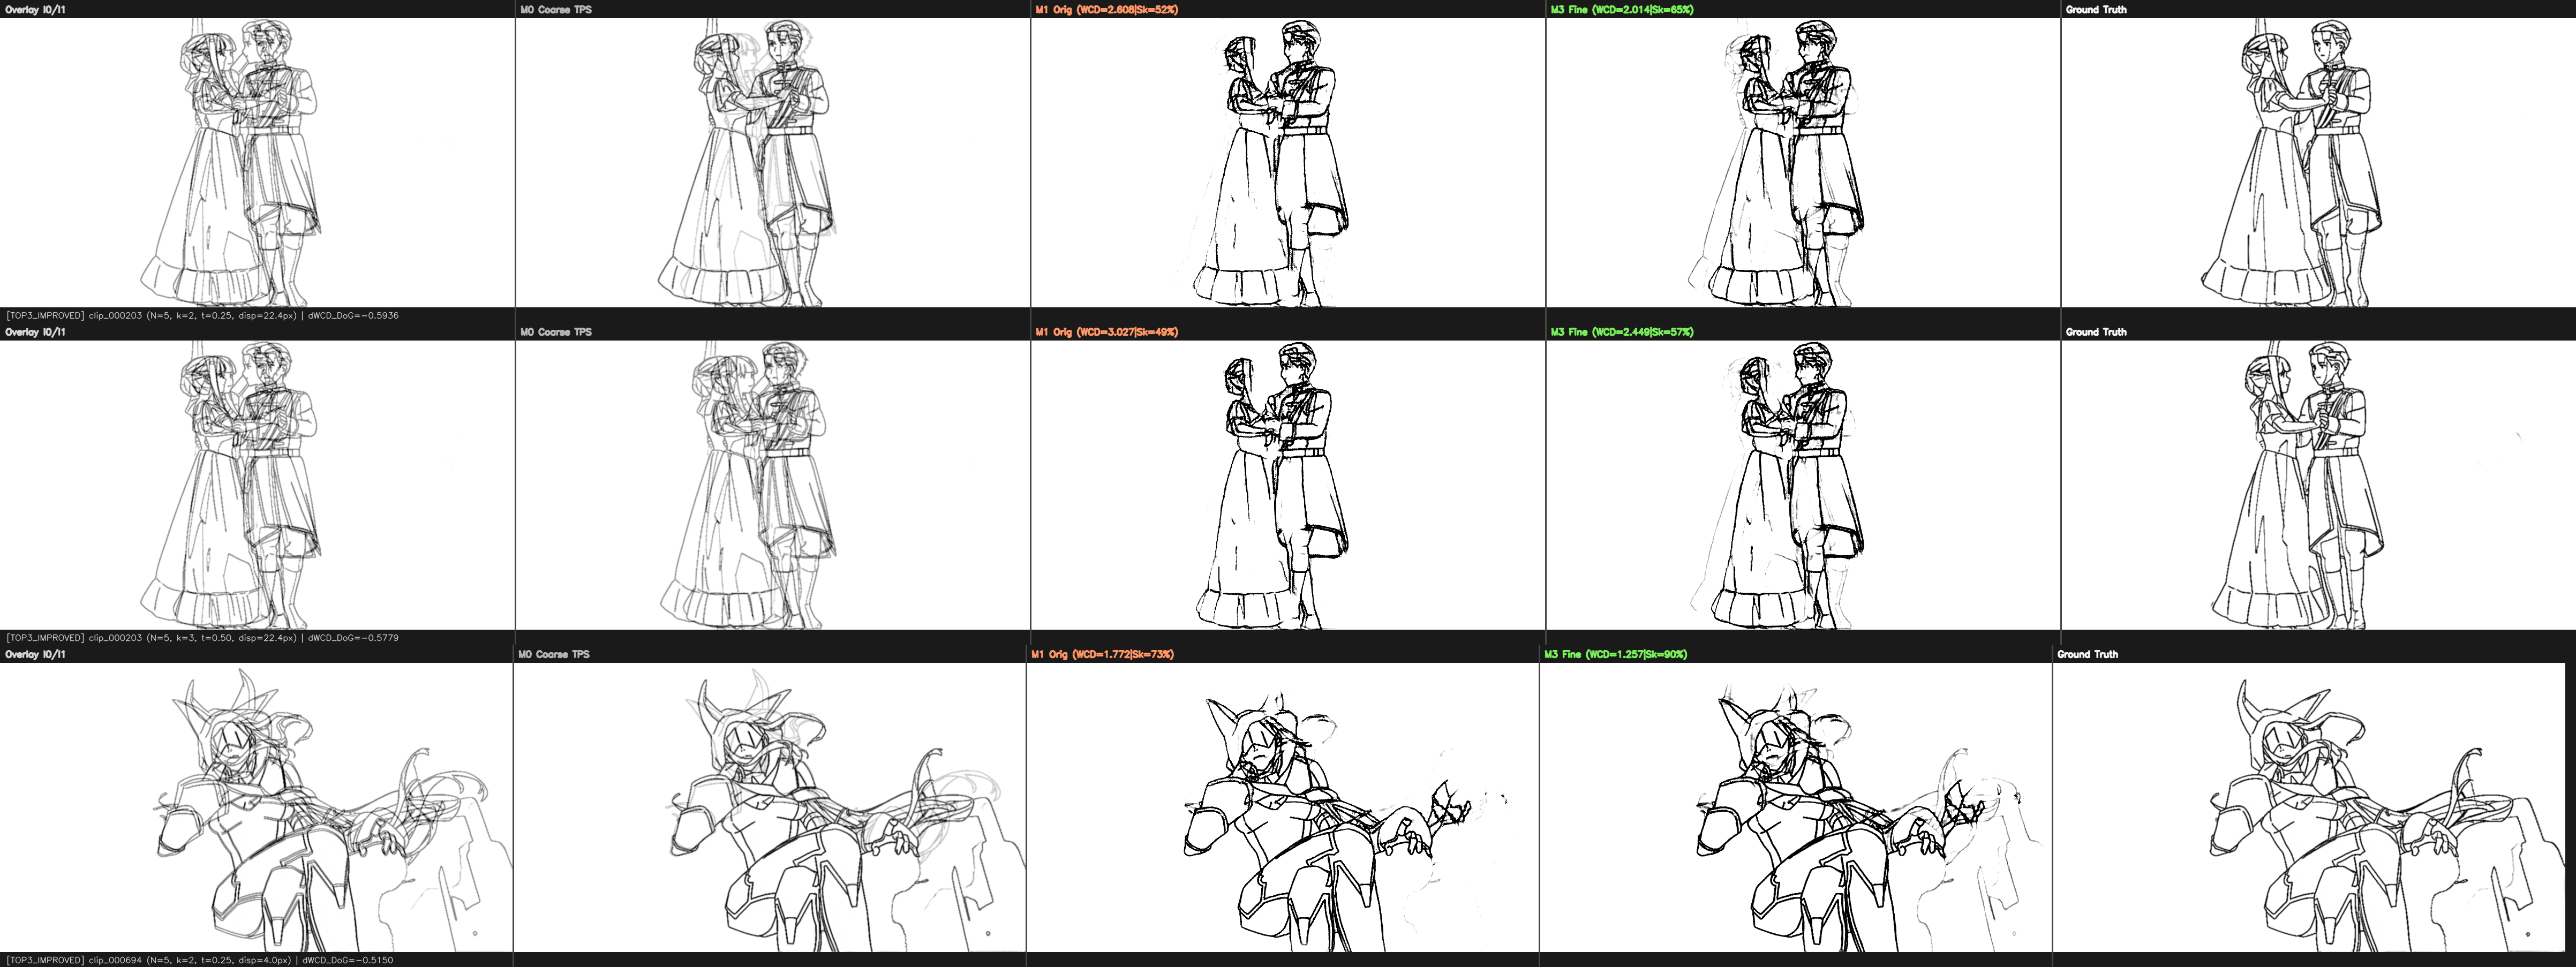


🖼️ Kiểm toán trực quan: TOP3_FAILURE_OR_HARD.png


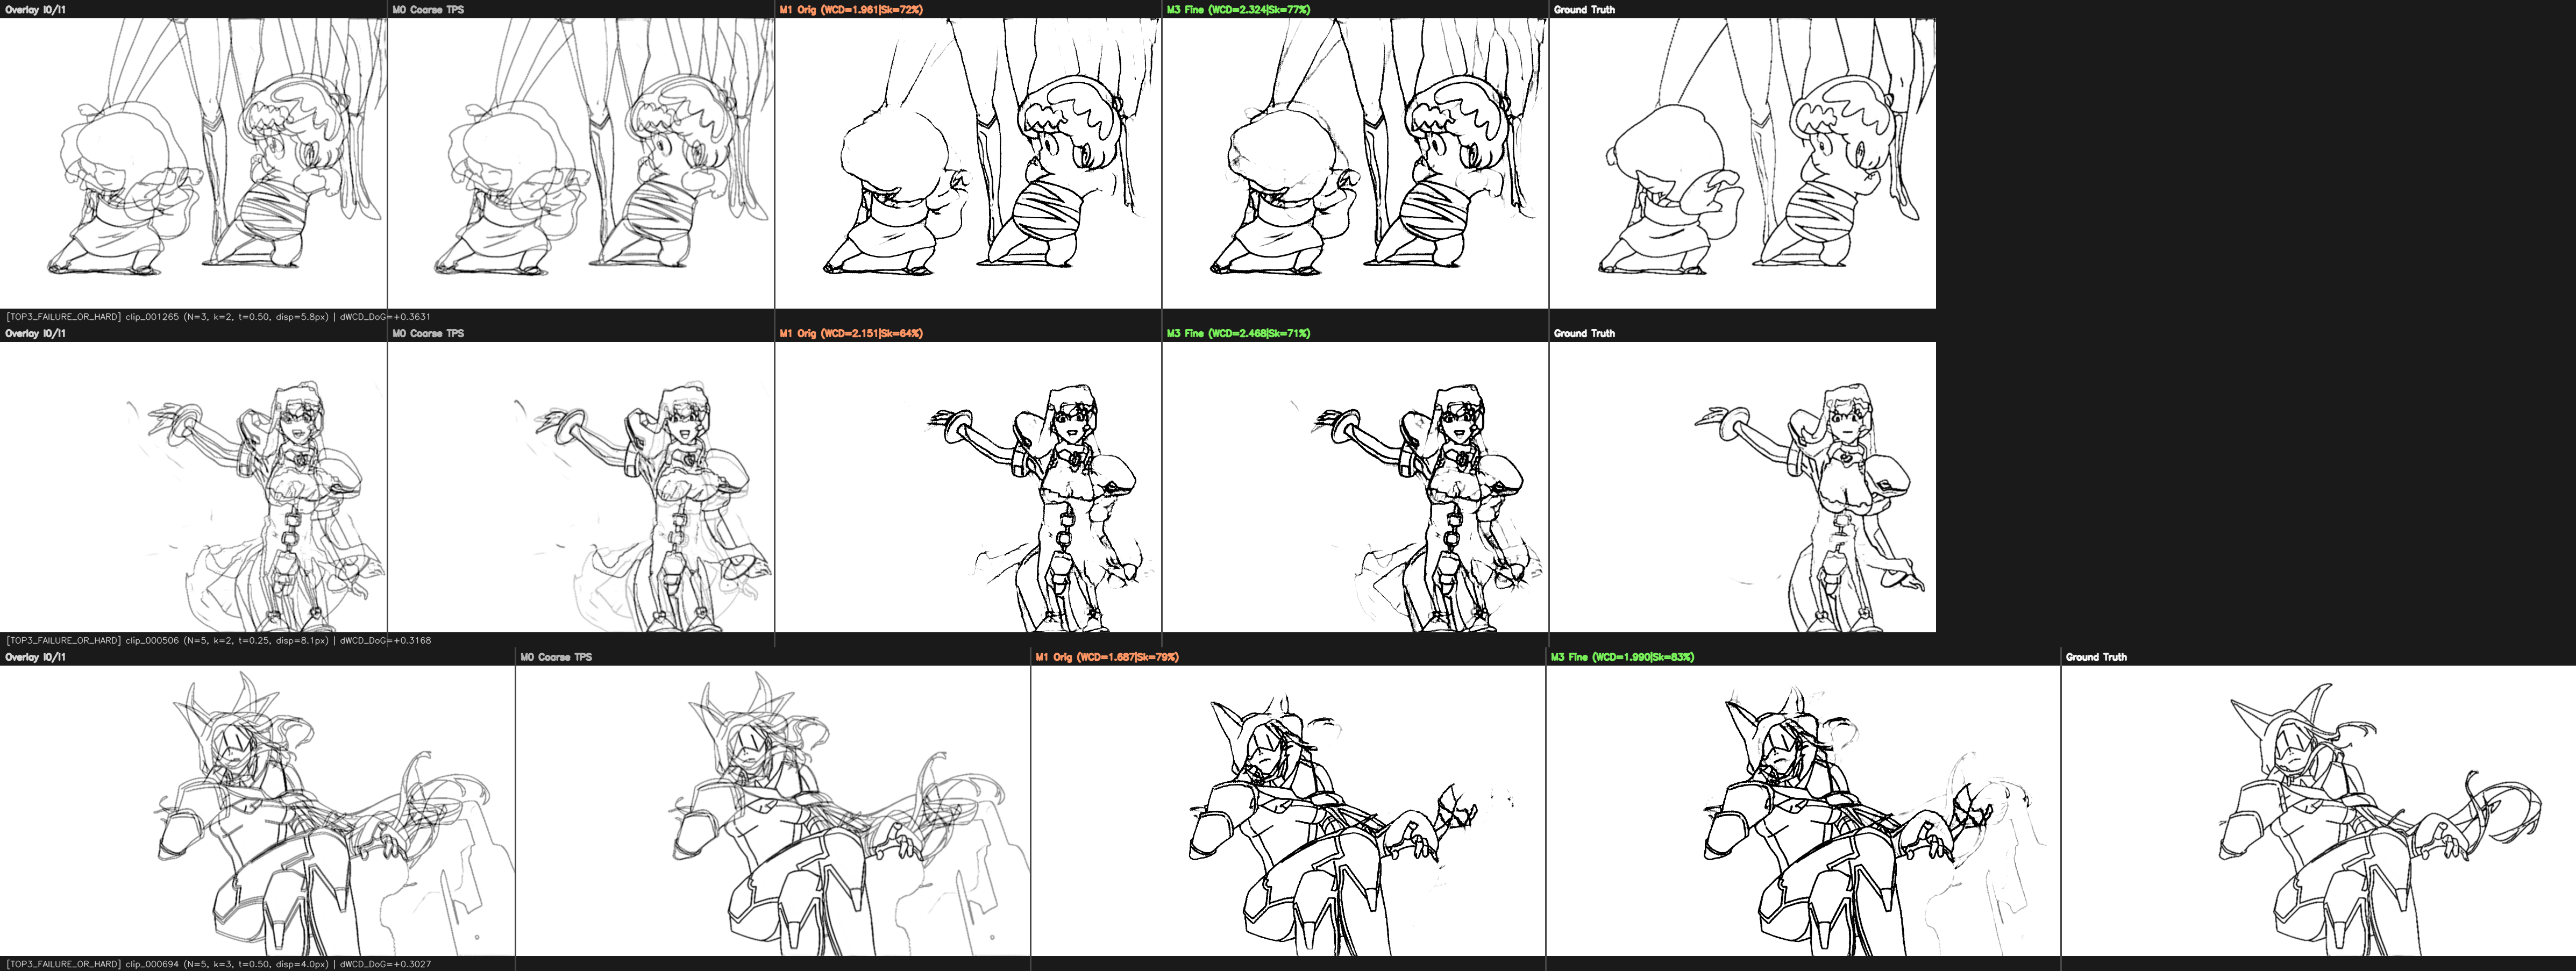

In [7]:
# ==============================================================================
# 🔬 [CELL 7]: BENCHMARK #1 — ĐỐI CHUẨN TẬP CÁCH LY (`sakuga_golden_benchmark_sequences_v2`)
# ==============================================================================
import os
import gc
import json
import torch
import pandas as pd
from IPython.display import display, Image as IPyImage
from ddp_worker_tps_sequence_final import TPSInbetweenOriginal, load_tps_weights
from run_benchmark_suite import run_benchmark_isolated_sequences

BENCH1_OUT = os.path.join(BENCH_OUT_DIR, "bench1_isolated_sequences")
best_ckpt_path = os.path.join(OUTPUT_CKPT_DIR, "model_tps_finetuned_best.pt")
last_ckpt_path = os.path.join(OUTPUT_CKPT_DIR, "model_tps_finetuned_last.pt")

if not BENCH_READY:
    print("[⚠️ BỎ QUA CELL 7]: Tập `sakuga_golden_benchmark_sequences_v2` chưa có trong Input.")
else:
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    models_dict = {}

    m1 = TPSInbetweenOriginal().to(device)
    load_tps_weights(m1, M1_CHECKPOINT_PATH, device=device, prefer_ema=False)
    models_dict['M1_Original'] = m1.eval()

    if os.path.exists(best_ckpt_path):
        m3_b = TPSInbetweenOriginal().to(device)
        load_tps_weights(m3_b, best_ckpt_path, device=device, prefer_ema=True)
        models_dict['M3_Best'] = m3_b.eval()

    if os.path.exists(last_ckpt_path):
        m3_l = TPSInbetweenOriginal().to(device)
        load_tps_weights(m3_l, last_ckpt_path, device=device, prefer_ema=True)
        models_dict['M3_Last'] = m3_l.eval()

    df_sum1, stat_audit1 = run_benchmark_isolated_sequences(
        BENCH_ROOT_PATH, models_dict, device, BENCH1_OUT, downscale_factor=2, save_visuals=True
    )

    print("\n📋 BẢNG PHÂN TẦNG THEO ĐỘ DÀI CHUỖI N={3,5,7} & BIÊN ĐỘ CHUYỂN ĐỘNG:")
    df_strat = pd.read_csv(os.path.join(BENCH1_OUT, "benchmark_stratified_breakdown.csv"))
    display(df_strat.round(4))

    for img_name in ["TOP3_IMPROVED.png", "TOP3_FAILURE_OR_HARD.png"]:
        p = os.path.join(BENCH1_OUT, "audit_cases_top3", img_name)
        if os.path.exists(p):
            print(f"\n🖼️ Kiểm toán trực quan: {img_name}")
            display(IPyImage(filename=p))

    del models_dict
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

[✓] Nạp trọng số (model_latest.pt): Khớp 158/158 active tensors 100%! (Bỏ qua 94 unused/dead keys)
[✓] Nạp trọng số (model_tps_finetuned_best.pt): Khớp 158/158 active tensors 100%!
[✓] Nạp trọng số (model_tps_finetuned_last.pt): Khớp 158/158 active tensors 100%!

🎬 BENCHMARK #2: TẠO FRAME THỰC TẾ LIÊN TỤC (24 frames: 7 keyframes, 17 inbetweens)
[*] Bộ trích xuất điểm neo hình học: GlueStick_MD_Precomputed | Pad: 960x540 -> 960x544

📊 KẾT QUẢ BENCHMARK #2 (ALL 17 INBETWEEN FRAMES - GLUESTICK):
            group   model_tag  frames    psnr   ssim  ie_mae    wcd  wcd_dog   semd  skel_recall  tip_recall     f1  density_ratio      ghost   pwcr    rgd
ALL_17_INBETWEENS          M0      17 15.1535 0.6148 17.4209 2.5613   2.9437 0.0077       0.6492      0.6576 0.7026         1.2609 44039.5294 0.8006 0.1264
ALL_17_INBETWEENS M1_Original      17 12.9400 0.6660 19.2778 2.9842   2.8944 0.0410       0.5050      0.5119 0.6748         0.7095  3869.4706 0.9242 0.0136
ALL_17_INBETWEENS     M3_Best     

,group,model_tag,frames,psnr,ssim,ie_mae,wcd,wcd_dog,semd,skel_recall,tip_recall,f1,density_ratio,ghost,pwcr,rgd
0,ALL_17_INBETWEENS,M0,17,15.1535,0.6148,17.4209,2.5613,2.9437,0.0077,0.6492,0.6576,0.7026,1.2609,44039.5294,0.8006,0.1264
1,ALL_17_INBETWEENS,M1_Original,17,12.9400,0.6660,19.2778,2.9842,2.8944,0.0410,0.5050,0.5119,0.6748,0.7095,3869.4706,0.9242,0.0136
2,ALL_17_INBETWEENS,M3_Best,17,12.3759,0.6490,21.5902,2.3879,2.7171,0.0215,0.5774,0.5865,0.6993,0.9379,6693.6471,0.8980,0.0212
3,ALL_17_INBETWEENS,M3_Last,17,15.0260,0.6550,16.1489,2.3404,2.6244,0.0187,0.5780,0.5871,0.7006,0.9688,20798.7059,0.8703,0.0652
4,delta_f=3,M0,4,16.2087,0.6749,14.7434,2.2858,2.6165,0.0085,0.7408,0.7384,0.7626,1.2891,42789.5000,0.8056,0.1259
5,delta_f=3,M1_Original,4,13.9181,0.7193,16.2130,2.4950,2.4273,0.0491,0.6349,0.6260,0.7702,0.7123,3041.0000,0.9255,0.0132
6,delta_f=3,M3_Best,4,13.4244,0.7078,17.8892,2.0086,2.2435,0.0313,0.7010,0.6929,0.7880,0.9250,5850.7500,0.9011,0.0208
7,delta_f=3,M3_Last,4,16.2900,0.7190,13.0228,1.9457,2.1761,0.0260,0.7037,0.6954,0.7926,0.9589,18468.5000,0.8731,0.0640
8,delta_f=4,M0,9,14.6888,0.5818,18.9104,2.6102,2.9990,0.0077,0.6310,0.6399,0.6903,1.2716,46672.7778,0.7898,0.1335
9,delta_f=4,M1_Original,9,12.5212,0.6379,20.8089,3.1382,3.0414,0.0418,0.4645,0.4734,0.6482,0.7016,4240.0000,0.9219,0.0143



🖼️ Đối đầu trực quan 6 phân đoạn liên tiếp [Overlay | M1 Orig | M3 Fine | GT]:


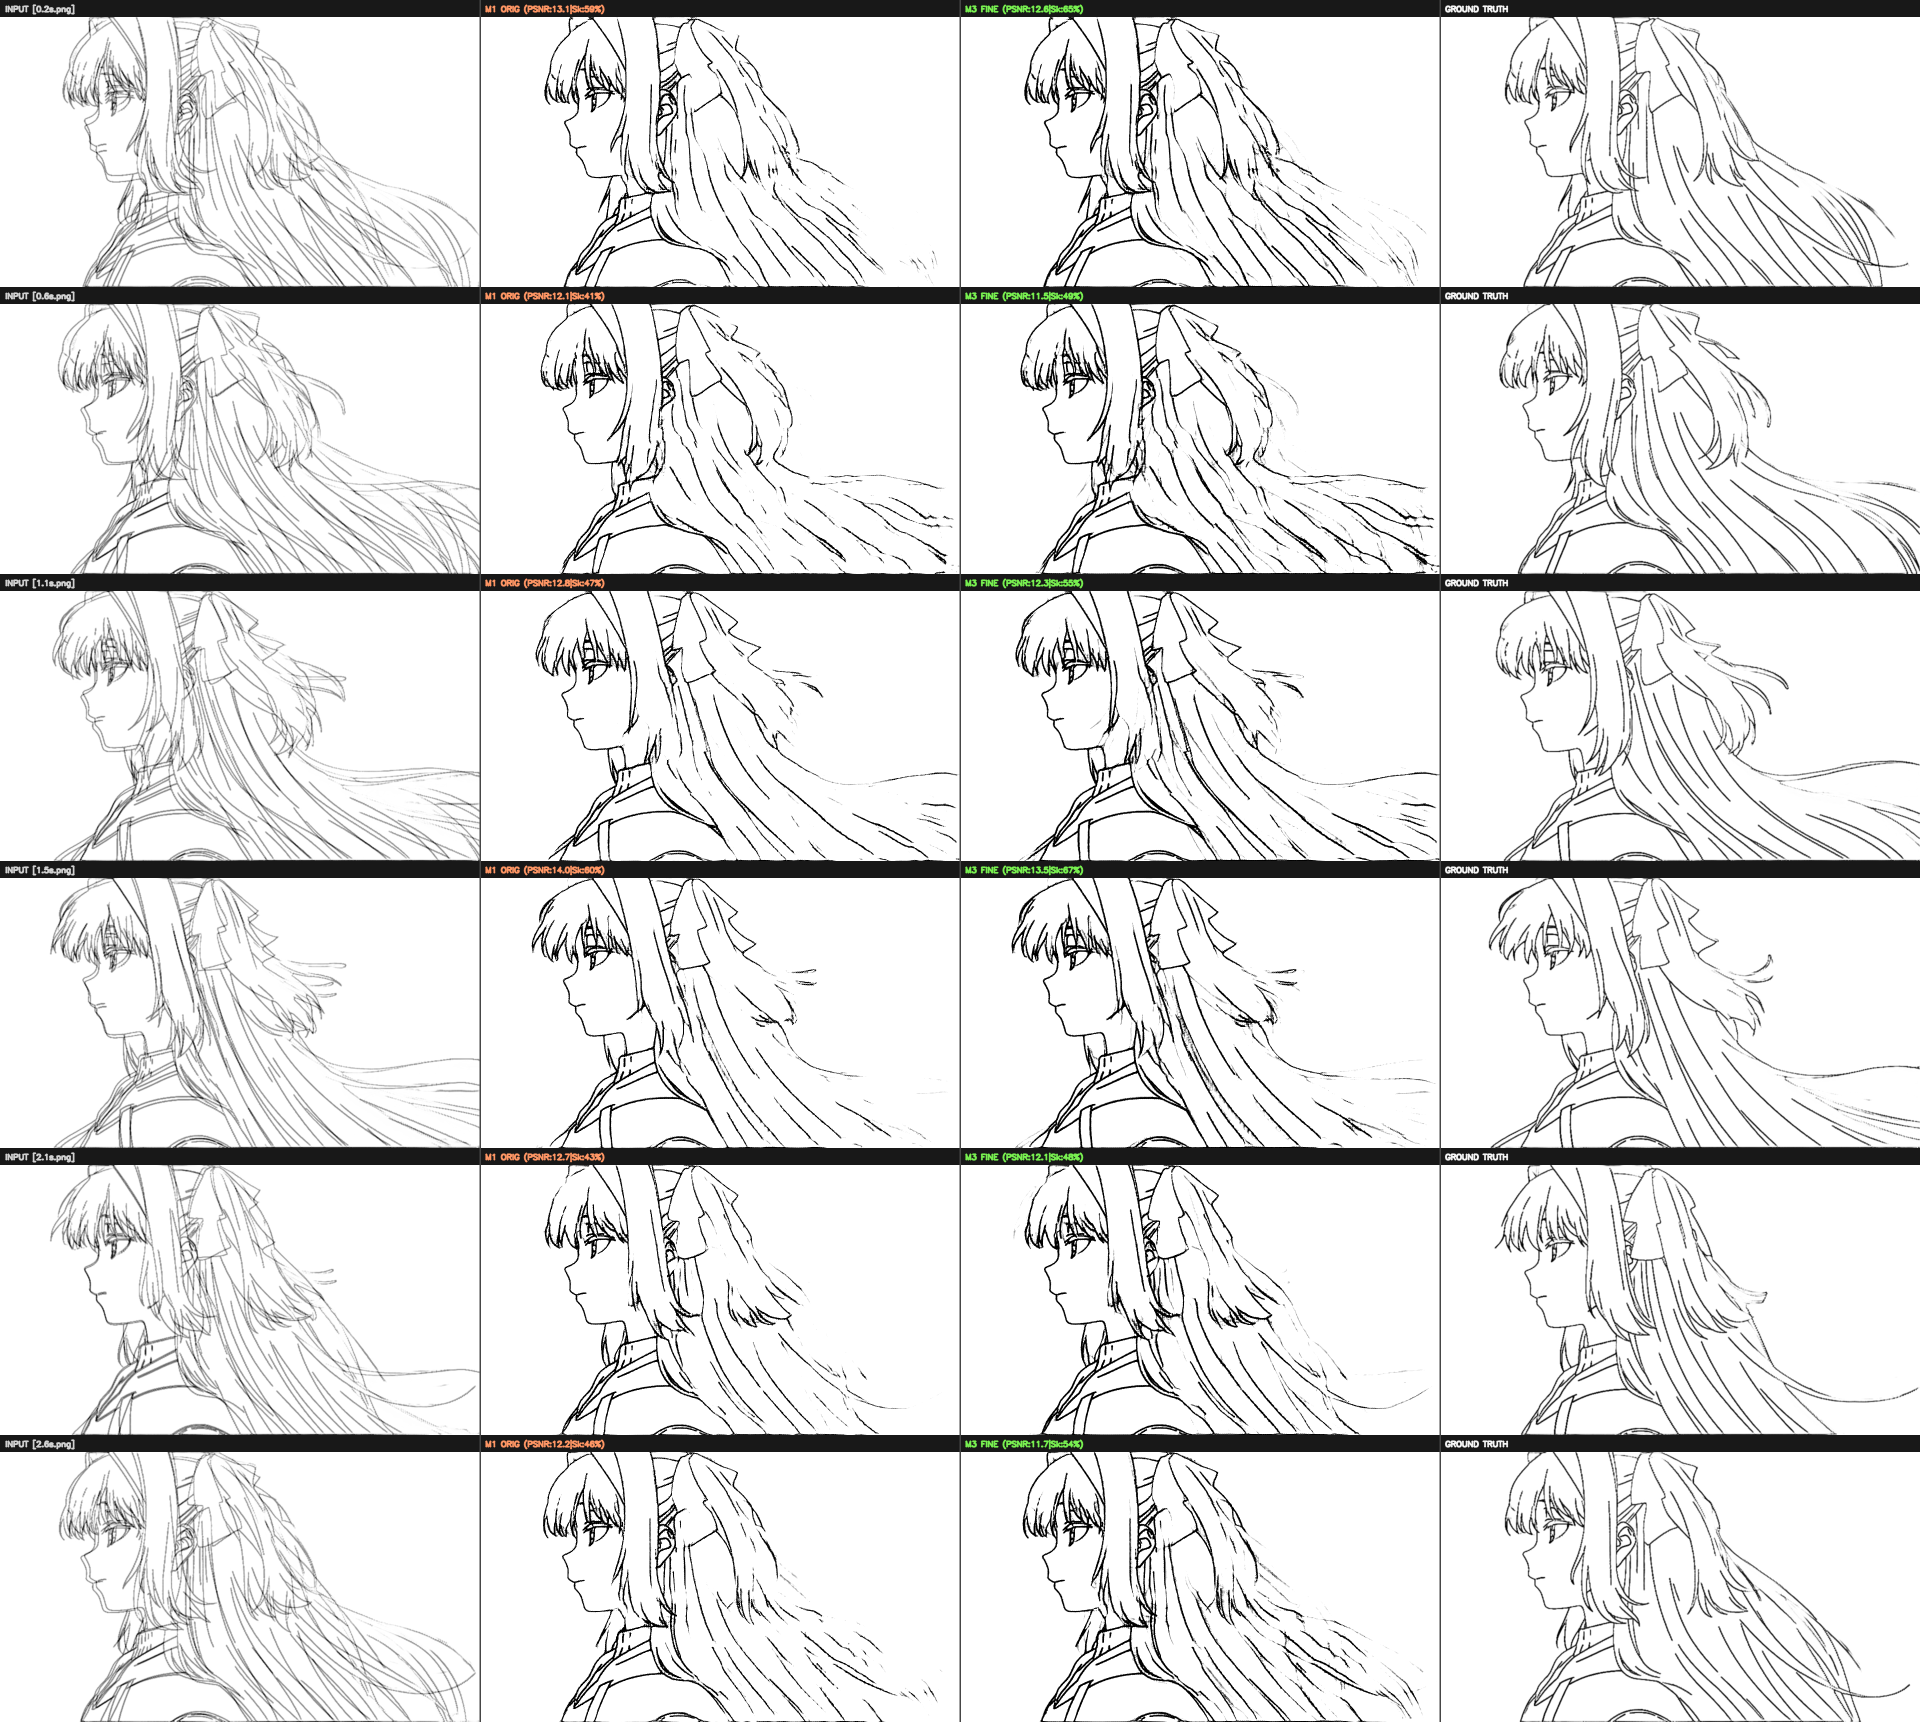

In [8]:
# ==============================================================================
# 🎬 [CELL 8]: BENCHMARK #2 — TẠO FRAME THỰC TẾ LIÊN TỤC (`data/lineart_experiments/test`)
# ==============================================================================
import os
import gc
import torch
import pandas as pd
from IPython.display import display, Image as IPyImage
from ddp_worker_tps_sequence_final import TPSInbetweenOriginal, load_tps_weights
from run_benchmark_suite import run_benchmark_continuous_lineart_test

BENCH2_OUT = os.path.join(BENCH_OUT_DIR, "bench2_continuous_lineart_test")
best_ckpt_path = os.path.join(OUTPUT_CKPT_DIR, "model_tps_finetuned_best.pt")
last_ckpt_path = os.path.join(OUTPUT_CKPT_DIR, "model_tps_finetuned_last.pt")

if not LINEART_TEST_READY:
    print("[⚠️ BỎ QUA CELL 8]: Tập `data/lineart_experiments/test` chưa có trong Input.")
else:
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    models_dict = {}

    m1 = TPSInbetweenOriginal().to(device)
    load_tps_weights(m1, M1_CHECKPOINT_PATH, device=device, prefer_ema=False)
    models_dict['M1_Original'] = m1.eval()

    if os.path.exists(best_ckpt_path):
        m3_b = TPSInbetweenOriginal().to(device)
        load_tps_weights(m3_b, best_ckpt_path, device=device, prefer_ema=True)
        models_dict['M3_Best'] = m3_b.eval()

    if os.path.exists(last_ckpt_path):
        m3_l = TPSInbetweenOriginal().to(device)
        load_tps_weights(m3_l, last_ckpt_path, device=device, prefer_ema=True)
        models_dict['M3_Last'] = m3_l.eval()

    df_sum2 = run_benchmark_continuous_lineart_test(
        LINEART_TEST_PATH, models_dict, device, BENCH2_OUT,
        gluestick_npz=GLUESTICK_TEST_NPZ, downscale_factor=2
    )
    if df_sum2 is not None:
        print("\n📋 TỔNG HỢP THEO ĐỘ DÀI CHẶNG (delta_f = 3, 4, 5):")
        display(df_sum2.round(4))

    montage_p = os.path.join(BENCH2_OUT, "montage_6segments_M1_vs_M3.png")
    if os.path.exists(montage_p):
        print("\n🖼️ Đối đầu trực quan 6 phân đoạn liên tiếp [Overlay | M1 Orig | M3 Fine | GT]:")
        display(IPyImage(filename=montage_p))

    del models_dict
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

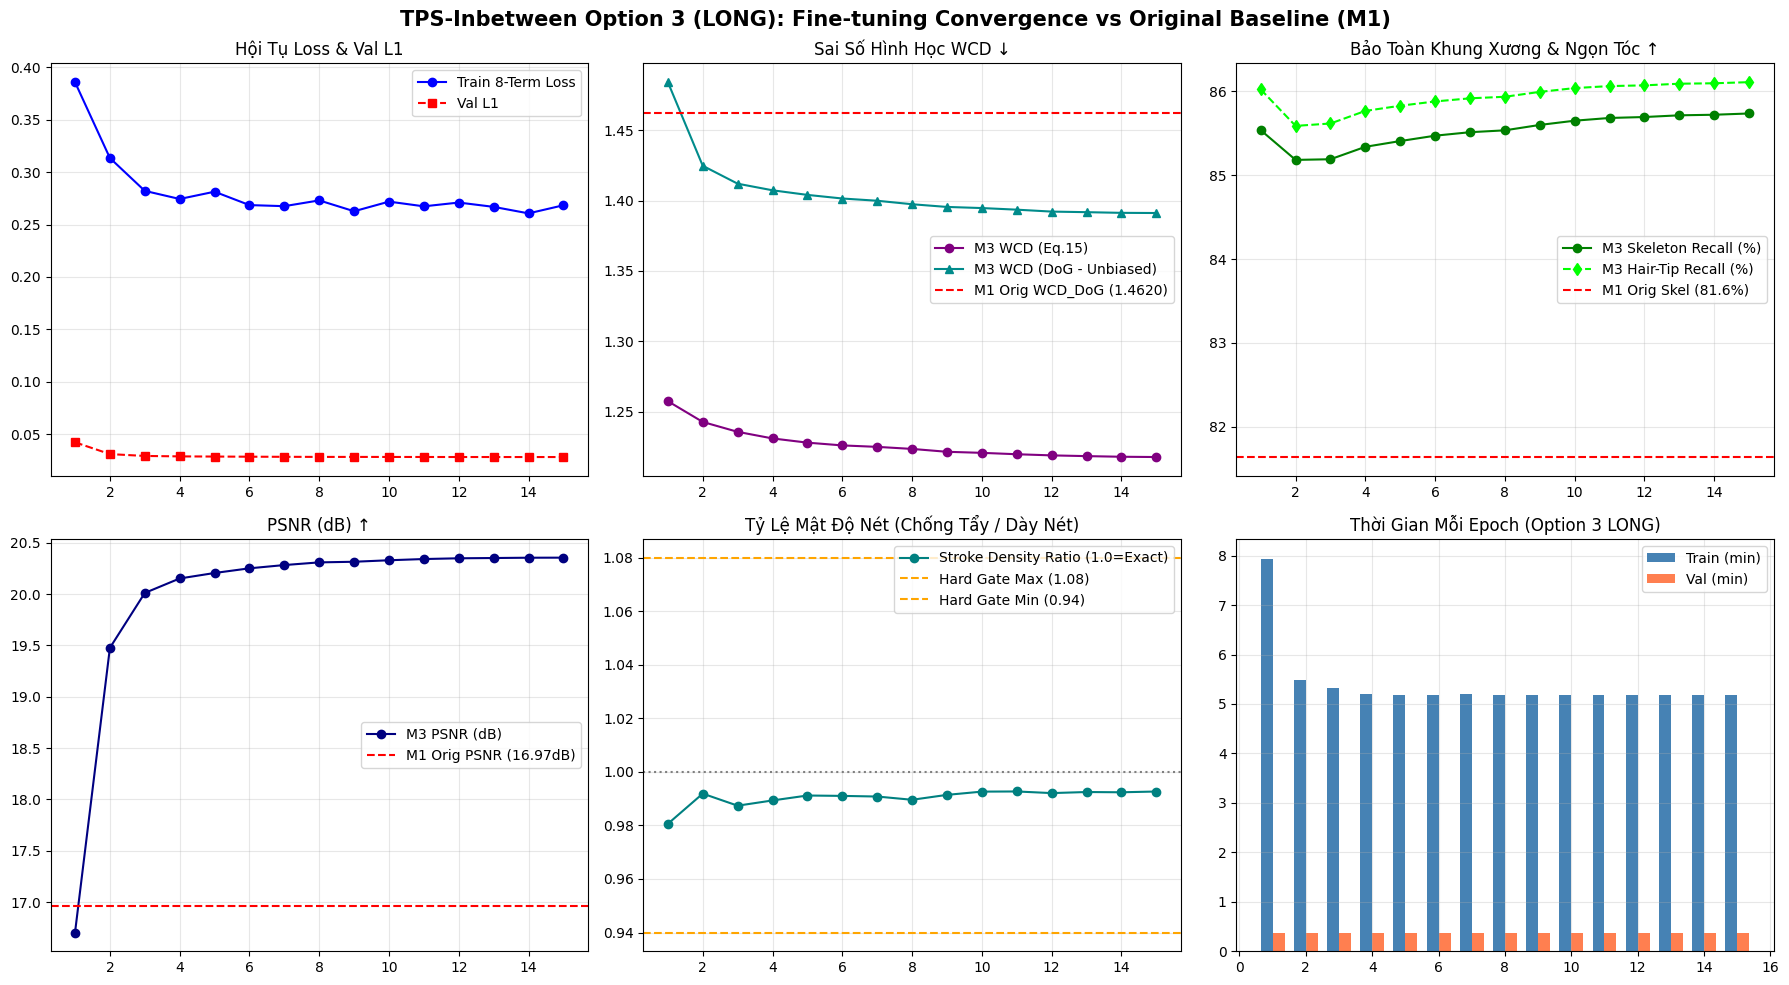

[✓] Đã lưu Dashboard hội tụ tại: /kaggle/working/training_convergence_dashboard.png


### ⚖️ TỔNG KẾT ĐỐI CHỨNG KHÁCH QUAN: `H1_SUPPORTED (Cải thiện đồng thời cả Hình học + Tô-pô nét vẽ với p < 0.01 & Giữ mật độ nét chuẩn [0.95, 1.08])`
- **Cam kết kiến trúc:** `M1` và `M3` cùng chạy trên đúng `TPSInbetweenOriginal` (**10,068,668 active params**, **0% thay đổi kiến trúc**).
- **Các điểm yếu cố hữu của kiến trúc gốc (vẫn tồn tại dù dùng dataset nào):** vùng che khuất 1-chiều (occlusion), một lưới TPS phẳng, và trường `IFNet` không nhận trực tiếp kênh thời gian `t`.
- `wcd_dog`: M1 = `1.4898` $\longrightarrow$ M3 = `1.5004` (WinRate = **30.6%**, Scene Wilcoxon $p$ = `1.68e-06`)
- `semd`: M1 = `0.0133` $\longrightarrow$ M3 = `0.0080` (WinRate = **95.2%**, Scene Wilcoxon $p$ = `8.49e-26`)
- `skel_recall`: M1 = `0.8137` $\longrightarrow$ M3 = `0.8550` (WinRate = **100.0%**, Scene Wilcoxon $p$ = `3.36e-26`)
- `f1`: M1 = `0.8980` $\longrightarrow$ M3 = `0.9079` (WinRate = **88.8%**, Scene Wilcoxon $p$ = `3.34e-20`)
- `psnr`: M1 = `16.6060` $\longrightarrow$ M3 = `16.3510` (WinRate = **7.0%**, Scene Wilcoxon $p$ = `2.76e-25`)

In [9]:
# ==============================================================================
# 📈 [CELL 9]: DASHBOARD HỘI TỤ TRAINING & NHẬN ĐỊNH KHÁCH QUAN KHOA HỌC
# ==============================================================================
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

hist_csv = os.path.join(WORKING_DIR, "training_history_finetune.csv")
val_base_json = os.path.join(WORKING_DIR, "val_baseline_m0_m1.json")

if os.path.exists(hist_csv):
    df_h = pd.read_csv(hist_csv)
    base_data = json.load(open(val_base_json, 'r', encoding='utf-8')) if os.path.exists(val_base_json) else {}
    m0_b = base_data.get('M0_Coarse', {})
    m1_b = base_data.get('M1_Original', {})

    ep = df_h['epoch'].values
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle("TPS-Inbetween Option 3 (LONG): Fine-tuning Convergence vs Original Baseline (M1)", fontsize=15, fontweight='bold')

    axes[0, 0].plot(ep, df_h['train_loss'], 'b-o', label='Train 8-Term Loss')
    axes[0, 0].plot(ep, df_h['val_l1'], 'r--s', label='Val L1')
    axes[0, 0].set_title("Hội Tụ Loss & Val L1"); axes[0, 0].grid(True, alpha=0.3); axes[0, 0].legend()

    axes[0, 1].plot(ep, df_h['wcd'], 'purple', marker='o', label='M3 WCD (Eq.15)')
    axes[0, 1].plot(ep, df_h['wcd_dog'], 'darkcyan', marker='^', label='M3 WCD (DoG - Unbiased)')
    if 'wcd_dog' in m1_b:
        axes[0, 1].axhline(m1_b['wcd_dog'], color='red', linestyle='--', label=f"M1 Orig WCD_DoG ({m1_b['wcd_dog']:.4f})")
    axes[0, 1].set_title("Sai Số Hình Học WCD ↓"); axes[0, 1].grid(True, alpha=0.3); axes[0, 1].legend()

    axes[0, 2].plot(ep, df_h['skel_recall'] * 100, 'g-o', label='M3 Skeleton Recall (%)')
    axes[0, 2].plot(ep, df_h['tip_recall'] * 100, 'lime', linestyle='--', marker='d', label='M3 Hair-Tip Recall (%)')
    if 'skel_recall' in m1_b:
        axes[0, 2].axhline(m1_b['skel_recall'] * 100, color='red', linestyle='--', label=f"M1 Orig Skel ({m1_b['skel_recall']*100:.1f}%)")
    axes[0, 2].set_title("Bảo Toàn Khung Xương & Ngọn Tóc ↑"); axes[0, 2].grid(True, alpha=0.3); axes[0, 2].legend()

    axes[1, 0].plot(ep, df_h['psnr'], 'navy', marker='o', label='M3 PSNR (dB)')
    if 'psnr' in m1_b:
        axes[1, 0].axhline(m1_b['psnr'], color='red', linestyle='--', label=f"M1 Orig PSNR ({m1_b['psnr']:.2f}dB)")
    axes[1, 0].set_title("PSNR (dB) ↑"); axes[1, 0].grid(True, alpha=0.3); axes[1, 0].legend()

    axes[1, 1].plot(ep, df_h['density_ratio'], 'teal', marker='o', label='Stroke Density Ratio (1.0=Exact)')
    axes[1, 1].axhline(1.0, color='gray', linestyle=':')
    axes[1, 1].axhline(1.08, color='orange', linestyle='--', label='Hard Gate Max (1.08)')
    axes[1, 1].axhline(0.94, color='orange', linestyle='--', label='Hard Gate Min (0.94)')
    axes[1, 1].set_title("Tỷ Lệ Mật Độ Nét (Chống Tẩy / Dày Nét)"); axes[1, 1].grid(True, alpha=0.3); axes[1, 1].legend()

    axes[1, 2].bar(ep - 0.18, df_h['train_time_min'], width=0.36, label='Train (min)', color='steelblue')
    axes[1, 2].bar(ep + 0.18, df_h['val_time_min'], width=0.36, label='Val (min)', color='coral')
    axes[1, 2].set_title("Thời Gian Mỗi Epoch (Option 3 LONG)"); axes[1, 2].grid(True, alpha=0.3); axes[1, 2].legend()

    plt.tight_layout()
    dash_path = os.path.join(WORKING_DIR, "training_convergence_dashboard.png")
    plt.savefig(dash_path, dpi=150)
    plt.show()
    print(f"[✓] Đã lưu Dashboard hội tụ tại: {dash_path}")
else:
    print("[*] Chưa có training_history_finetune.csv.")

# Tóm tắt kết luận tự động từ dữ liệu Benchmark #1 (nếu có)
audit_json = os.path.join(BENCH_OUT_DIR, "bench1_isolated_sequences", "benchmark_statistical_audit.json")
if os.path.exists(audit_json):
    au = json.load(open(audit_json, 'r', encoding='utf-8'))
    verdict = au.get('hypothesis_verdict', 'N/A')
    h2h = au.get('head_to_head_M3_vs_M1', {})
    lines = [
        f"### ⚖️ TỔNG KẾT ĐỐI CHỨNG KHÁCH QUAN: `{verdict}`",
        "- **Cam kết kiến trúc:** `M1` và `M3` cùng chạy trên đúng `TPSInbetweenOriginal` (**10,068,668 active params**, **0% thay đổi kiến trúc**).",
        "- **Các điểm yếu cố hữu của kiến trúc gốc (vẫn tồn tại dù dùng dataset nào):** vùng che khuất 1-chiều (occlusion), một lưới TPS phẳng, và trường `IFNet` không nhận trực tiếp kênh thời gian `t`."
    ]
    for mc in ['wcd_dog', 'semd', 'skel_recall', 'f1', 'psnr']:
        if mc in h2h:
            st = h2h[mc]
            lines.append(f"- `{mc}`: M1 = `{st['m1_mean']:.4f}` $\\longrightarrow$ M3 = `{st['m3_mean']:.4f}` (WinRate = **{st['frame_win_rate_pct']:.1f}%**, Scene Wilcoxon $p$ = `{st['scene_wilcoxon_p']:.2e}`)")
    display(Markdown("\n".join(lines)))

In [10]:
# ==============================================================================
# 📦 [CELL 10]: ĐÓNG GÓI CHECKPOINT BEST + LAST & TOÀN BỘ KẾT QUẢ BENCHMARK (.ZIP)
# ==============================================================================
import os
import zipfile
import shutil
import torch

RELEASE_ZIP = os.path.join(WORKING_DIR, "tps_sequence_finetune_option3_release.zip")
STRIP_TEMP = os.path.join("/tmp" if os.path.exists("/tmp") else WORKING_DIR, "_strip_ckpt_tmp")
os.makedirs(STRIP_TEMP, exist_ok=True)

# Rút gọn optimizer_state khi đóng gói release để tải về nhanh (chỉ giữ trọng số chuẩn)
best_src = os.path.join(OUTPUT_CKPT_DIR, "model_tps_finetuned_best.pt")
last_src = os.path.join(OUTPUT_CKPT_DIR, "model_tps_finetuned_last.pt")

pack_items = []
for src_p, zip_name in [(best_src, "checkpoints/model_tps_finetuned_best.pt"),
                        (last_src, "checkpoints/model_tps_finetuned_last.pt")]:
    if os.path.exists(src_p):
        raw = torch.load(src_p, map_location='cpu', weights_only=False)
        # Chọn EMA weights làm model_state chuẩn cho file tải về gọn (~52MB/file)
        clean_sd = raw.get('model_state')
        if zip_name.endswith("last.pt") and raw.get('ema_state') is not None:
            es = raw['ema_state']
            clean_sd = es['shadow'] if isinstance(es, dict) and 'shadow' in es else clean_sd
        lite_obj = {
            'epoch': raw.get('epoch'),
            'best_score': raw.get('best_score'),
            'model_state': clean_sd,
            'history': raw.get('history', []),
        }
        tmp_out = os.path.join(STRIP_TEMP, os.path.basename(zip_name))
        torch.save(lite_obj, tmp_out)
        pack_items.append((tmp_out, zip_name))

# Đính kèm file log training & dashboard
for fname in ["training_history_finetune.csv", "val_baseline_m0_m1.json", "training_convergence_dashboard.png"]:
    fp = os.path.join(WORKING_DIR, fname)
    if os.path.exists(fp):
        pack_items.append((fp, fname))

# Đính kèm toàn bộ output Benchmark #1 & #2
if os.path.exists(BENCH_OUT_DIR):
    for root, _, files in os.walk(BENCH_OUT_DIR):
        for f in files:
            full_p = os.path.join(root, f)
            rel_p = os.path.relpath(full_p, WORKING_DIR)
            pack_items.append((full_p, rel_p))

with zipfile.ZipFile(RELEASE_ZIP, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for src_f, arc_name in pack_items:
        zf.write(src_f, arcname=arc_name)

shutil.rmtree(STRIP_TEMP, ignore_errors=True)

print("=" * 84)
print(f"📦 ĐÃ ĐÓNG GÓI THÀNH CÔNG {len(pack_items)} TỆP VÀO: {RELEASE_ZIP}")
print(f"   Dung lượng nén: {os.path.getsize(RELEASE_ZIP)/(1024**2):.2f} MB")
print(f"📁 Kiểm tra thư mục Checkpoint (chỉ còn đúng best & last): {os.listdir(OUTPUT_CKPT_DIR)}")
print("=" * 84)

📦 ĐÃ ĐÓNG GÓI THÀNH CÔNG 57 TỆP VÀO: /kaggle/working/tps_sequence_finetune_option3_release.zip
   Dung lượng nén: 108.93 MB
📁 Kiểm tra thư mục Checkpoint (chỉ còn đúng best & last): ['model_tps_finetuned_last.pt', 'model_tps_finetuned_best.pt']
